<a href="https://colab.research.google.com/github/MuhammadAhmedSubhani/SartorIA/blob/main/SartorIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recovery Phase in case of Restart Program

## Recovery Phase R1 — Reconnect Google Drive

Reconnect Google Drive and restore the VESTA project paths. Do not rerun the Hugging Face dataset acquisition or download the 500 images again.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import json
import time
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image, ImageOps
from tqdm.auto import tqdm

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

PROJECT_ROOT = Path("/content/drive/MyDrive/VESTA_AI")

DRIVE_ROOT = (
    PROJECT_ROOT / "datasets/processed/viton_hd_500"
)

V2_DIR = PROJECT_ROOT / "models/v2"
V2_CHECKPOINT_DIR = V2_DIR / "checkpoints"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Drive connected.")
print("Project:", PROJECT_ROOT)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert DRIVE_ROOT.exists(), "VESTA dataset folder not found!"
assert V2_CHECKPOINT_DIR.exists(), "V2 checkpoint folder not found!"

print("VESTA project files located successfully.")

Mounted at /content/drive
Drive connected.
Project: /content/drive/MyDrive/VESTA_AI
Device: cuda
GPU: Tesla T4
VESTA project files located successfully.


## Recovery Phase R2 — Restore the dataset and DataLoaders

We will read the saved train/validation manifests directly from Drive. This recreates the same 450/50 split without acquiring the dataset again.

In [2]:
train_manifest_path = DRIVE_ROOT / "train_manifest.csv"
val_manifest_path = DRIVE_ROOT / "validation_manifest.csv"

assert train_manifest_path.exists()
assert val_manifest_path.exists()

train_df = pd.read_csv(train_manifest_path)
val_df = pd.read_csv(val_manifest_path)

IMAGE_SIZE = (256, 192)

rgb_transform = transforms.Compose([
    transforms.Resize(
        IMAGE_SIZE,
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

mask_transform = transforms.Compose([
    transforms.Resize(
        IMAGE_SIZE,
        interpolation=transforms.InterpolationMode.NEAREST
    ),
    transforms.ToTensor()
])

class VESTADataset(Dataset):

    def __init__(self, dataframe, root):
        self.df = dataframe.reset_index(drop=True)
        self.root = Path(root)

    def load_image(self, relative_path, mode="RGB"):
        with Image.open(self.root / relative_path) as image:
            image = ImageOps.exif_transpose(image)
            return image.convert(mode)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        return {
            "target": rgb_transform(
                self.load_image(row["target"])
            ),
            "garment": rgb_transform(
                self.load_image(row["garment"])
            ),
            "agnostic": rgb_transform(
                self.load_image(row["agnostic"])
            ),
            "cloth_mask": mask_transform(
                self.load_image(row["cloth_mask"], "L")
            ),
            "pose": rgb_transform(
                self.load_image(row["pose"])
            ),
            "sample_id": row["sample_id"]
        }

train_dataset = VESTADataset(train_df, DRIVE_ROOT)
val_dataset = VESTADataset(val_df, DRIVE_ROOT)

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

test_batch = next(iter(val_loader))

for key, value in test_batch.items():
    if torch.is_tensor(value):
        print(key, tuple(value.shape))

Training samples: 450
Validation samples: 50
Train batches: 450
Validation batches: 50
target (1, 3, 256, 192)
garment (1, 3, 256, 192)
agnostic (1, 3, 256, 192)
cloth_mask (1, 1, 256, 192)
pose (1, 3, 256, 192)


## Recovery Phase R3 — Restore model architecture definitions

The trained checkpoint contains model weights, not the Python class definitions. We need to recreate those definitions before loading the weights.

From your notebook, rerun these existing definition cells in order:
1. Phase 4.2 — SinusoidalTimeEmbedding
2. Phase 4.3 — valid_groups and ResidualBlock
3. Phase 4.4 — ConditioningEncoder and VESTAConditioningEncoders
4. Phase 4.5 — VESTAFeatureFusion
5. Phase 4.6 — VESTAConditionalUNet
Run the class definitions only. You do not need to rerun old training, forward-pass experiments, or checkpoint-saving cells.

Also rerun these existing Phase 5 definitions:
- extract_values()
- add_noise()
And rerun the Phase 8.11 definition of VESTACosineScheduler.

Do not rerun the old linear training loop or V2 training loop.

##  Recovery Phase R4 — Reload VESTA v2 Checkpoint
This is the most important recovery step. We will reconstruct V2, read its saved training history, identify the best validation epoch, and load that epoch's checkpoint.

In [10]:
BASE_CHANNELS = 32
TIME_DIM = 128

# Restore the cosine scheduler
new_scheduler = VESTACosineScheduler(
    timesteps=1000,
    device=device
)

# Restore training history from Google Drive
v2_history_path = V2_DIR / "vesta_v2_training_history.json"

assert v2_history_path.exists(), (
    "V2 training history not found!"
)

with open(v2_history_path, "r") as f:
    v2_history = json.load(f)

print("Recorded V2 epochs:", len(v2_history))

# Identify the best validation epoch
best_epoch = min(
    v2_history,
    key=lambda item: item["val_unweighted_loss"]
)["epoch"]

best_checkpoint_path = (
    V2_CHECKPOINT_DIR
    / f"vesta_v2_epoch_{best_epoch:02d}.pth"
)

assert best_checkpoint_path.exists(), (
    f"Best checkpoint missing: {best_checkpoint_path}"
)

# Recreate the model architecture
model_v2 = VESTAConditionalUNet(
    base_channels=BASE_CHANNELS,
    time_dim=TIME_DIM
).to(device)

# Load saved weights
best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=False
)

model_v2.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model_v2.eval()

print("\nVESTA v2 restored successfully!")
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    best_checkpoint["validation_metrics"]["unweighted_loss"]
)
print("Checkpoint:", best_checkpoint_path)

Cosine scheduler initialized.
Timesteps: 1000
Alpha cumulative product at timestep 999: 2.428733658632609e-09
Recorded V2 epochs: 10

VESTA v2 restored successfully!
Best epoch: 10
Best validation loss: 0.4666712063550949
Checkpoint: /content/drive/MyDrive/VESTA_AI/models/v2/checkpoints/vesta_v2_epoch_10.pth


## Recovery Phase R5 — Restore the generation function
Define the V2 reverse diffusion sampler again. This sampler uses velocity-to-noise conversion, matching the objective used to train V2.

In [11]:
@torch.no_grad()
def vesta_v2_generate(
    model,
    scheduler,
    person,
    garment,
    mask,
    pose,
    device
):
    model.eval()

    batch_size = person.shape[0]

    image = torch.randn(
        person.shape,
        device=device
    )

    betas = scheduler.betas
    alphas = scheduler.alphas
    alpha_bar = scheduler.alpha_cumprod

    for t in tqdm(
        reversed(range(scheduler.timesteps)),
        total=scheduler.timesteps,
        desc="VESTA v2 generation"
    ):

        timesteps = torch.full(
            (batch_size,),
            t,
            device=device,
            dtype=torch.long
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            predicted_velocity = model(
                noisy_target=image,
                timesteps=timesteps,
                person=person,
                garment=garment,
                mask=mask,
                pose=pose
            )

        a_bar = alpha_bar[t]
        beta = betas[t]
        alpha = alphas[t]

        predicted_noise = (
            torch.sqrt(1.0 - a_bar) * image
            + torch.sqrt(a_bar) * predicted_velocity.float()
        )

        if t > 0:
            previous_alpha_bar = alpha_bar[t - 1]
        else:
            previous_alpha_bar = torch.tensor(
                1.0,
                device=device
            )

        posterior_variance = (
            beta * (1.0 - previous_alpha_bar)
            / (1.0 - a_bar)
        )

        image = (
            image.float()
            - (
                beta / torch.sqrt(1.0 - a_bar)
            ) * predicted_noise
        ) / torch.sqrt(alpha)

        if t > 0:
            image = (
                image
                + torch.sqrt(posterior_variance)
                * torch.randn_like(image)
            )

    return image.clamp(-1, 1)


print("VESTA v2 generation function restored.")

VESTA v2 generation function restored.


## Recovery Phase R6 — Generate VESTA v2

Now the DataLoaders, architecture, checkpoint, scheduler, and generation function are restored. Generate one validation sample.


In [12]:
test_batch = next(iter(val_loader))

person = test_batch["agnostic"][:1].to(device)
garment = test_batch["garment"][:1].to(device)
mask = test_batch["cloth_mask"][:1].to(device)
pose = test_batch["pose"][:1].to(device)
target = test_batch["target"][:1].to(device)

generated_v2 = vesta_v2_generate(
    model=model_v2,
    scheduler=new_scheduler,
    person=person,
    garment=garment,
    mask=mask,
    pose=pose,
    device=device
)

print("Generated V2 shape:", generated_v2.shape)
print("Contains NaN:", torch.isnan(generated_v2).any().item())
print("Contains Inf:", torch.isinf(generated_v2).any().item())

assert generated_v2.shape == target.shape
assert torch.isfinite(generated_v2).all()

print("VESTA v2 generation successful!")

VESTA v2 generation:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated V2 shape: torch.Size([1, 3, 256, 192])
Contains NaN: False
Contains Inf: False
VESTA v2 generation successful!


## Recovery Phase R7 — Display and permanently save the result

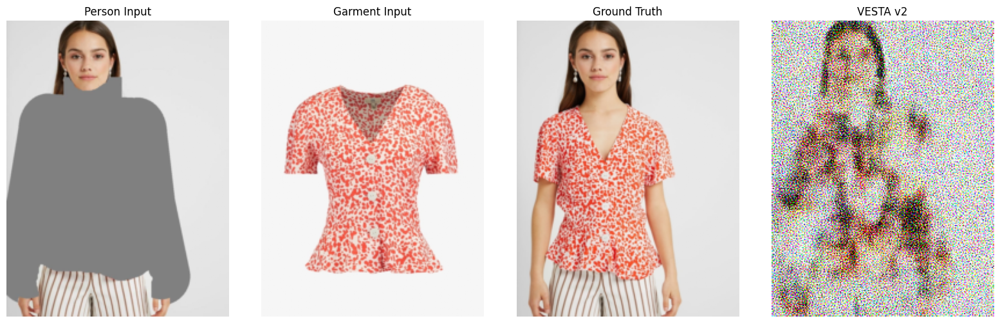

Generated image saved: /content/drive/MyDrive/VESTA_AI/outputs/generated/v2/vesta_v2_first_result.png


In [13]:
def display_vesta_image(tensor):
    return (
        tensor.detach()
        .float()
        .cpu()
        .squeeze(0)
        .permute(1, 2, 0)
        .mul(0.5)
        .add(0.5)
        .clamp(0, 1)
        .numpy()
    )

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    person,
    garment,
    target,
    generated_v2
]

titles = [
    "Person Input",
    "Garment Input",
    "Ground Truth",
    "VESTA v2"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(display_vesta_image(img))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save result to Google Drive
OUTPUT_DIR = PROJECT_ROOT / "outputs/generated/v2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

generated_array = (
    display_vesta_image(generated_v2) * 255
).round().astype("uint8")

generated_path = OUTPUT_DIR / "vesta_v2_first_result.png"

Image.fromarray(generated_array).save(generated_path)

print("Generated image saved:", generated_path)

# Step 0 — Configure Google Drive


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected!")

Mounted at /content/drive
Google Drive connected!


In [ ]:

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/VESTA_AI"
)

folders = [
    "datasets/raw",
    "datasets/processed",
    "datasets/splits",
    "models/checkpoints",
    "models/final",
    "outputs/generated",
    "outputs/evaluation",
    "src/data",
    "src/models",
    "src/training",
    "src/inference",
    "src/utils",
    "configs",
    "logs"
]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("VESTA project structure created!")

for item in PROJECT_ROOT.iterdir():
    print(item.name)


VESTA project structure created!
datasets
models
outputs
src
configs
logs
training_history.json


In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    props = torch.cuda.get_device_properties(0)

    print(
        "GPU memory:",
        round(props.total_memory / 1024**3, 2),
        "GB"
    )

    print(
        "CUDA version:",
        torch.version.cuda
    )
else:
    print("No GPU detected. Check Colab runtime settings.")


PyTorch version: 2.14.1+cpu
CUDA available: False
No GPU detected. Check Colab runtime settings.


# Phase 1 — Dataset Acquisition and Validation

In [ ]:

%pip install -q huggingface_hub datasets


In [ ]:

from huggingface_hub import HfApi

api = HfApi()

repo_id = "forgeml/viton_hd"

info = api.dataset_info(repo_id)

print("Dataset:", repo_id)
print("Repository ID:", info.id)
print("License:", info.card_data.license if info.card_data else "Not specified")

print("\nAvailable files:")

files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

for file in files[:50]:
    print(file)


Dataset: forgeml/viton_hd
Repository ID: forgeml/viton_hd
License: None

Available files:
.gitattributes
README.md
data/train-00000-of-00008-6453a8909f0bec19.parquet
data/train-00001-of-00008-c2ee4b6c4348189d.parquet
data/train-00002-of-00008-a491dcf8c6c1d970.parquet
data/train-00003-of-00008-c5f7d8ce9a564e0c.parquet
data/train-00004-of-00008-7911982a4565dc57.parquet
data/train-00005-of-00008-c7df311908192ba7.parquet
data/train-00006-of-00008-b406fec5581b842c.parquet
data/train-00007-of-00008-89e4bafae18c9c43.parquet


In [ ]:

from datasets import load_dataset

dataset = load_dataset(
    "forgeml/viton_hd",
    split="train",
    streaming=True
)

print("Dataset connected!")

first = next(iter(dataset))

print("Available columns:", list(first.keys()))

for key, value in first.items():
    print(key, type(value).__name__)


README.md:   0%|          | 0.00/543 [00:00<?, ?B/s]

Dataset connected!
Available columns: ['cloth', 'cloth_mask', 'image', 'pose', 'agnostic', 'caption']
cloth JpegImageFile
cloth_mask JpegImageFile
image JpegImageFile
pose PngImageFile
agnostic JpegImageFile
caption str


# Phase 1.2 — VITON-HD Sample Acquisition

In [ ]:

from pathlib import Path

LOCAL_ROOT = Path("/content/VESTA_samples")

DIRS = {
    "target": LOCAL_ROOT / "target",
    "garment": LOCAL_ROOT / "garment",
    "agnostic": LOCAL_ROOT / "agnostic",
    "cloth_mask": LOCAL_ROOT / "cloth_mask",
    "pose": LOCAL_ROOT / "pose"
}

for path in DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

print("VESTA sample directories created!")

for name, path in DIRS.items():
    print(name, "->", path)


VESTA sample directories created!
target -> /content/VESTA_samples/target
garment -> /content/VESTA_samples/garment
agnostic -> /content/VESTA_samples/agnostic
cloth_mask -> /content/VESTA_samples/cloth_mask
pose -> /content/VESTA_samples/pose


In [ ]:

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import random

SAMPLE_COUNT = 500
SEED = 42

random.seed(SEED)

# Start a fresh streaming iterator.
stream = load_dataset(
    "forgeml/viton_hd",
    split="train",
    streaming=True
)

# Randomized buffer avoids simply taking the first 500 records.
stream = stream.shuffle(
    seed=SEED,
    buffer_size=1000
)

manifest = []
failed = []

for index, record in enumerate(
    tqdm(stream.take(SAMPLE_COUNT))
):
    try:
        sample_id = f"vesta_{index:05d}"

        field_map = {
            "image": ("target", "jpg"),
            "cloth": ("garment", "jpg"),
            "agnostic": ("agnostic", "jpg"),
            "cloth_mask": ("cloth_mask", "png"),
            "pose": ("pose", "png")
        }

        paths = {}

        for source_field, (destination, ext) in field_map.items():

            img = record[source_field].copy()

            output_path = (
                DIRS[destination] /
                f"{sample_id}.{ext}"
            )

            if destination == "cloth_mask":
                img.save(output_path, format="PNG")
            elif destination == "pose":
                img.save(output_path, format="PNG")
            else:
                img.convert("RGB").save(
                    output_path,
                    format="JPEG",
                    quality=95
                )

            paths[destination] = str(output_path)

        manifest.append({
            "sample_id": sample_id,
            "source": "forgeml/viton_hd",
            **paths,
            "caption": record.get("caption", "")
        })

    except Exception as error:
        failed.append({
            "index": index,
            "error": str(error)
        })

manifest_df = pd.DataFrame(manifest)

print("\nACQUISITION RESULTS")
print("Successful pairs:", len(manifest_df))
print("Failed records:", len(failed))


0it [00:00, ?it/s]


ACQUISITION RESULTS
Successful pairs: 500
Failed records: 0


In [ ]:

from PIL import Image

required_columns = [
    "target",
    "garment",
    "agnostic",
    "cloth_mask",
    "pose"
]

validation_errors = []

for _, row in tqdm(manifest_df.iterrows(),
                   total=len(manifest_df)):

    for column in required_columns:
        path = Path(row[column])

        if not path.exists():
            validation_errors.append(
                f"Missing {column}: {path}"
            )
            continue

        try:
            with Image.open(path) as img:
                img.verify()
        except Exception as error:
            validation_errors.append(
                f"Corrupt {path}: {error}"
            )

print("Total pairs:", len(manifest_df))
print("Validation errors:", len(validation_errors))

if validation_errors:
    print(validation_errors[:10])
else:
    print("All image files passed validation!")


  0%|          | 0/500 [00:00<?, ?it/s]

Total pairs: 500
Validation errors: 0
All image files passed validation!


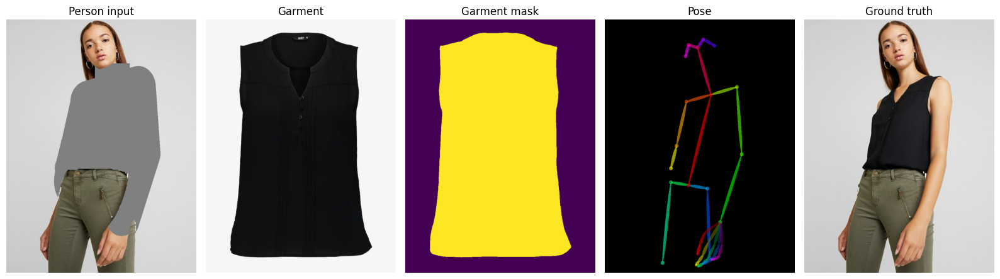

In [ ]:

import matplotlib.pyplot as plt

def show_training_sample(index=0):

    row = manifest_df.iloc[index]

    fig, axes = plt.subplots(1, 5, figsize=(16, 5))

    fields = [
        ("agnostic", "Person input"),
        ("garment", "Garment"),
        ("cloth_mask", "Garment mask"),
        ("pose", "Pose"),
        ("target", "Ground truth")
    ]

    for ax, (field, title) in zip(axes, fields):
        img = Image.open(row[field])
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_training_sample(0)


In [ ]:

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/VESTA_AI"
)

PROJECT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root restored:", PROJECT_ROOT)
print("Google Drive available:",
      Path("/content/drive/MyDrive").exists())


Project root restored: /content/drive/MyDrive/VESTA_AI
Google Drive available: True


In [ ]:

import shutil
import json

DRIVE_ROOT = (
    PROJECT_ROOT / "datasets/processed/viton_hd_500"
)

DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

for name, local_path in DIRS.items():

    destination = DRIVE_ROOT / name

    shutil.copytree(
        local_path,
        destination,
        dirs_exist_ok=True
    )

# Save manifest with portable relative paths.
drive_manifest = manifest_df.copy()

for column in required_columns:
    drive_manifest[column] = drive_manifest[column].apply(
        lambda p: str(Path(p).relative_to(LOCAL_ROOT))
    )

drive_manifest.to_csv(
    DRIVE_ROOT / "manifest.csv",
    index=False
)

metadata = {
    "dataset": "VITON-HD",
    "source": "forgeml/viton_hd",
    "samples": len(drive_manifest),
    "validated": len(validation_errors) == 0,
    "license_status": "Original dataset CC BY-NC 4.0; research use only"
}

with open(DRIVE_ROOT / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("VESTA dataset saved successfully!")
print("Location:", DRIVE_ROOT)
print("Pairs:", len(drive_manifest))


VESTA dataset saved successfully!
Location: /content/drive/MyDrive/VESTA_AI/datasets/processed/viton_hd_500
Pairs: 500


In [ ]:

DRIVE_ROOT = (
    PROJECT_ROOT / "datasets/processed/viton_hd_500"
)

print("Dataset exists:", DRIVE_ROOT.exists())

for folder in DRIVE_ROOT.iterdir():
    if folder.is_dir():
        print(folder.name, ":", len(list(folder.iterdir())), "files")

print(
    "Manifest exists:",
    (DRIVE_ROOT / "manifest.csv").exists()
)

print(
    "Metadata exists:",
    (DRIVE_ROOT / "metadata.json").exists()
)


Dataset exists: True
target : 500 files
garment : 500 files
agnostic : 500 files
cloth_mask : 500 files
pose : 500 files
Manifest exists: True
Metadata exists: True


# Step 2 — Install project dependencies

In [ ]:

%pip install -q \
    numpy \
    pandas \
    pillow \
    matplotlib \
    tqdm \
    opencv-python-headless \
    einops \
    scikit-learn \
    safetensors


In [ ]:

import torch
import torchvision
import numpy
import pandas
import cv2
import PIL
import einops

print("All core dependencies imported successfully!")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)


All core dependencies imported successfully!
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
OpenCV: 4.14.0


# Phase 2.1 — VESTA Data Engineering


In [ ]:

import pandas as pd
from pathlib import Path

DRIVE_ROOT = (
    PROJECT_ROOT / "datasets/processed/viton_hd_500"
)

manifest_path = DRIVE_ROOT / "manifest.csv"

df = pd.read_csv(manifest_path)

print("Total samples:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())


Total samples: 500

Columns:
['sample_id', 'source', 'target', 'garment', 'agnostic', 'cloth_mask', 'pose', 'caption']

First 5 records:


,sample_id,source,target,garment,agnostic,cloth_mask,pose,caption
0,vesta_00000,forgeml/viton_hd,target/vesta_00000.jpg,garment/vesta_00000.jpg,agnostic/vesta_00000.jpg,cloth_mask/vesta_00000.png,pose/vesta_00000.png,NaN
1,vesta_00001,forgeml/viton_hd,target/vesta_00001.jpg,garment/vesta_00001.jpg,agnostic/vesta_00001.jpg,cloth_mask/vesta_00001.png,pose/vesta_00001.png,NaN
2,vesta_00002,forgeml/viton_hd,target/vesta_00002.jpg,garment/vesta_00002.jpg,agnostic/vesta_00002.jpg,cloth_mask/vesta_00002.png,pose/vesta_00002.png,NaN
3,vesta_00003,forgeml/viton_hd,target/vesta_00003.jpg,garment/vesta_00003.jpg,agnostic/vesta_00003.jpg,cloth_mask/vesta_00003.png,pose/vesta_00003.png,NaN
4,vesta_00004,forgeml/viton_hd,target/vesta_00004.jpg,garment/vesta_00004.jpg,agnostic/vesta_00004.jpg,cloth_mask/vesta_00004.png,pose/vesta_00004.png,NaN


In [ ]:

from PIL import Image
from collections import Counter

image_columns = [
    "target",
    "garment",
    "agnostic",
    "cloth_mask",
    "pose"
]

dimension_report = {}

for column in image_columns:

    dimensions = Counter()

    for relative_path in df[column].dropna():

        path = DRIVE_ROOT / relative_path

        with Image.open(path) as img:
            dimensions[img.size] += 1

    dimension_report[column] = dimensions

    print(f"\n{column.upper()}")
    for size, count in dimensions.most_common():
        print(size, ":", count)



TARGET
(768, 1024) : 500

GARMENT
(768, 1024) : 500

AGNOSTIC
(768, 1024) : 500

CLOTH_MASK
(768, 1024) : 500

POSE
(768, 1024) : 500


In [ ]:

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.10,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

train_df.to_csv(
    DRIVE_ROOT / "train_manifest.csv",
    index=False
)

val_df.to_csv(
    DRIVE_ROOT / "validation_manifest.csv",
    index=False
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))


Training samples: 450
Validation samples: 50


In [ ]:

import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image, ImageOps

IMAGE_SIZE = (256, 192)

rgb_transform = transforms.Compose([
    transforms.Resize(
        IMAGE_SIZE,
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

mask_transform = transforms.Compose([
    transforms.Resize(
        IMAGE_SIZE,
        interpolation=transforms.InterpolationMode.NEAREST
    ),
    transforms.ToTensor()
])


class VESTADataset(Dataset):

    def __init__(self, dataframe, root):
        self.df = dataframe.reset_index(drop=True)
        self.root = Path(root)

    def load_image(self, relative_path, mode="RGB"):

        path = self.root / relative_path

        with Image.open(path) as image:
            image = ImageOps.exif_transpose(image)
            image = image.convert(mode)

        return image

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        target = self.load_image(row["target"])
        garment = self.load_image(row["garment"])
        agnostic = self.load_image(row["agnostic"])

        cloth_mask = self.load_image(
            row["cloth_mask"],
            mode="L"
        )

        pose = self.load_image(
            row["pose"],
            mode="RGB"
        )

        return {
            "target": rgb_transform(target),
            "garment": rgb_transform(garment),
            "agnostic": rgb_transform(agnostic),
            "cloth_mask": mask_transform(cloth_mask),
            "pose": rgb_transform(pose),
            "sample_id": row["sample_id"]
        }


train_dataset = VESTADataset(
    train_df,
    DRIVE_ROOT
)

val_dataset = VESTADataset(
    val_df,
    DRIVE_ROOT
)

print("VESTA Dataset class initialized!")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))


VESTA Dataset class initialized!
Training: 450
Validation: 50


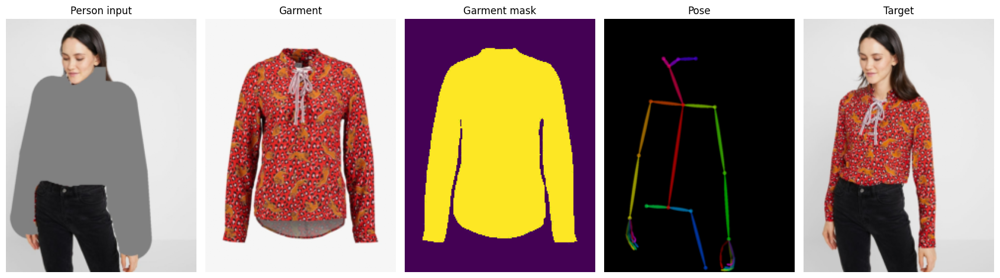

Sample ID: vesta_00072
Target shape: torch.Size([3, 256, 192])
Garment shape: torch.Size([3, 256, 192])


In [ ]:

import matplotlib.pyplot as plt

sample = train_dataset[0]

def display_tensor(tensor):
    image = tensor.detach().cpu()

    if image.shape[0] == 1:
        return image.squeeze(0).numpy()

    image = image.permute(1, 2, 0)
    image = (image * 0.5 + 0.5).clamp(0, 1)

    return image.numpy()


fig, axes = plt.subplots(1, 5, figsize=(17, 5))

fields = [
    ("agnostic", "Person input"),
    ("garment", "Garment"),
    ("cloth_mask", "Garment mask"),
    ("pose", "Pose"),
    ("target", "Target")
]

for ax, (key, title) in zip(axes, fields):

    ax.imshow(display_tensor(sample[key]))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Sample ID:", sample["sample_id"])
print("Target shape:", sample["target"].shape)
print("Garment shape:", sample["garment"].shape)


In [ ]:

from torch.utils.data import DataLoader

BATCH_SIZE = 1

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

batch = next(iter(train_loader))

for key, value in batch.items():

    if isinstance(value, torch.Tensor):
        print(key, value.shape, value.dtype)

print("\nVESTA DataLoaders initialized!")


target torch.Size([1, 3, 256, 192]) torch.float32
garment torch.Size([1, 3, 256, 192]) torch.float32
agnostic torch.Size([1, 3, 256, 192]) torch.float32
cloth_mask torch.Size([1, 1, 256, 192]) torch.float32
pose torch.Size([1, 3, 256, 192]) torch.float32

VESTA DataLoaders initialized!


In [ ]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

batch_gpu = {
    key: value.to(device)
    for key, value in batch.items()
    if isinstance(value, torch.Tensor)
}

print("Device:", device)

for key, value in batch_gpu.items():
    print(key, value.shape, value.device)

if torch.cuda.is_available():
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**2, 2),
        "MB"
    )


Device: cuda
target torch.Size([1, 3, 256, 192]) cuda:0
garment torch.Size([1, 3, 256, 192]) cuda:0
agnostic torch.Size([1, 3, 256, 192]) cuda:0
cloth_mask torch.Size([1, 1, 256, 192]) cuda:0
pose torch.Size([1, 3, 256, 192]) cuda:0
GPU memory allocated: 2.44 MB


# Phase 2.5 — Input Diagnostics

- **Target (`image`)**: ground-truth person image wearing the paired garment.
- **Agnostic (`agnostic`)**: person conditioning representation with the original garment region removed or neutralized.
- **Garment (`cloth`)**: product image paired with the target.
- **Garment mask (`cloth_mask`)**: grayscale mask aligned to the garment product image. It is **not** a mask of the clothing region on the person's body.
- **Pose (`pose`)**: inspect its encoding before choosing preprocessing and channel count.

Preserve grayscale mask boundary values; do not threshold without evidence.

Pose mode: RGB
Pose shape: (1024, 768, 3)
Pose dtype: uint8
Minimum: 0
Maximum: 238
Unique values: 108


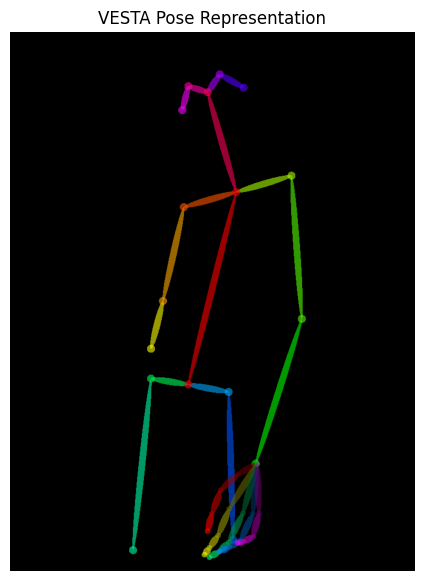

In [ ]:
# Inspect pose representation before finalizing the pose encoder.
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sample_row = df.iloc[0]
pose_path = DRIVE_ROOT / sample_row["pose"]

with Image.open(pose_path) as pose_image:
    pose_image = pose_image.copy()

pose_array = np.array(pose_image)

print("Pose mode:", pose_image.mode)
print("Pose shape:", pose_array.shape)
print("Pose dtype:", pose_array.dtype)
print("Minimum:", pose_array.min())
print("Maximum:", pose_array.max())
print("Unique values:", len(np.unique(pose_array)))

plt.figure(figsize=(6, 7))
if pose_array.ndim == 2:
    plt.imshow(pose_array, cmap="gray")
else:
    plt.imshow(pose_array)
plt.title("VESTA Pose Representation")
plt.axis("off")
plt.show()


# Step 3 — Create our project configuration

In [ ]:
import json

CONFIG = {
    "project_name": "VESTA_AI",
    "version": "0.1.0",
    "data": {
        "image_height": 256,
        "image_width": 192,
        "dataset_size": 500,
        "train_samples": 450,
        "validation_samples": 50
    },
    "model": {
        "architecture": "modular_conditional_diffusion_unet",
        "target_channels": 3,
        "person_channels": 3,
        "garment_channels": 3,
        "garment_mask_channels": 1,
        "pose_channels": 3,  # Provisional; verify pose encoding first.
        "base_channels": 32,
        "conditioning_channels": 32,
        "output_channels": 3,
        "use_separate_encoders": True,
        "use_skip_connections": True,
        "use_attention": False
    },
    "diffusion": {
        "timesteps": 1000,
        "sampling_steps": 30,
        "noise_schedule": "linear"
    },
    "training": {
        "batch_size": 1,
        "learning_rate": 0.0001,
        "epochs": 10,
        "gradient_accumulation_steps": 4,
        "mixed_precision": True,
        "seed": 42
    },
    "categories": ["tops"]
}

config_path = PROJECT_ROOT / "configs/config.json"
config_path.parent.mkdir(parents=True, exist_ok=True)
with open(config_path, "w") as f:
    json.dump(CONFIG, f, indent=4)

print("VESTA architecture configuration updated!")
print(json.dumps(CONFIG, indent=4))


VESTA architecture configuration updated!
{
    "project_name": "VESTA_AI",
    "version": "0.1.0",
    "data": {
        "image_height": 256,
        "image_width": 192,
        "dataset_size": 500,
        "train_samples": 450,
        "validation_samples": 50
    },
    "model": {
        "architecture": "modular_conditional_diffusion_unet",
        "target_channels": 3,
        "person_channels": 3,
        "garment_channels": 3,
        "garment_mask_channels": 1,
        "pose_channels": 3,
        "base_channels": 32,
        "conditioning_channels": 32,
        "output_channels": 3,
        "use_separate_encoders": true,
        "use_skip_connections": true,
        "use_attention": false
    },
    "diffusion": {
        "timesteps": 1000,
        "sampling_steps": 30,
        "noise_schedule": "linear"
    },
    "training": {
        "batch_size": 1,
        "learning_rate": 0.0001,
        "epochs": 10,
        "gradient_accumulation_steps": 4,
        "mixed_precision": tr

# Step 4 - Mask diagnostics

In [ ]:

from PIL import Image
import numpy as np
from pathlib import Path

mask_path = DRIVE_ROOT / df.iloc[0]["cloth_mask"]

mask = np.array(
    Image.open(mask_path)
)

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)

unique_colors = np.unique(
    mask.reshape(-1, mask.shape[-1])
    if mask.ndim == 3
    else mask.reshape(-1),
    axis=0
)

print("Unique mask values/colors:", len(unique_colors))
print("First 20 values:")
print(unique_colors[:20])

print(
    "Minimum:",
    mask.min(),
    "Maximum:",
    mask.max()
)


Mask shape: (1024, 768)
Mask dtype: uint8
Unique mask values/colors: 79
First 20 values:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Minimum: 0 Maximum: 255


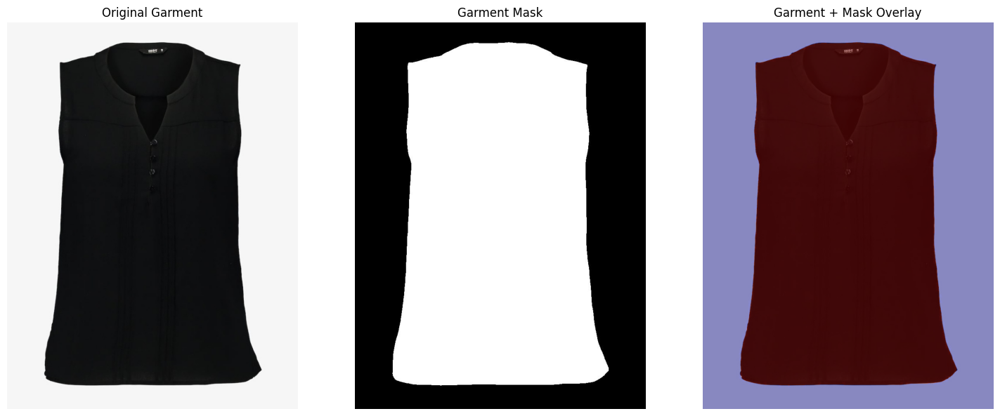

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

sample_row = df.iloc[0]

garment_path = DRIVE_ROOT / sample_row["garment"]
mask_path = DRIVE_ROOT / sample_row["cloth_mask"]

garment = Image.open(garment_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(garment)
axes[0].set_title("Original Garment")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Garment Mask")

axes[2].imshow(garment)
axes[2].imshow(
    mask,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=255
)
axes[2].set_title("Garment + Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

mask_array = np.array(mask)

print("Intensity distribution:")

values, counts = np.unique(
    mask_array,
    return_counts=True
)

for value, count in zip(values, counts):
    print(f"{value}: {count} pixels")

print("\nPercentage of non-zero pixels:",
      round(np.mean(mask_array > 0) * 100, 2), "%")

print("Percentage of strong foreground pixels:",
      round(np.mean(mask_array > 127) * 100, 2), "%")


Intensity distribution:
0: 349865 pixels
1: 736 pixels
2: 896 pixels
3: 412 pixels
4: 632 pixels
5: 256 pixels
6: 218 pixels
7: 193 pixels
8: 174 pixels
9: 162 pixels
10: 123 pixels
11: 148 pixels
12: 135 pixels
13: 91 pixels
14: 96 pixels
15: 80 pixels
16: 71 pixels
17: 45 pixels
18: 38 pixels
19: 21 pixels
20: 26 pixels
21: 22 pixels
22: 16 pixels
23: 4 pixels
24: 10 pixels
25: 12 pixels
26: 3 pixels
27: 10 pixels
28: 4 pixels
29: 9 pixels
30: 8 pixels
31: 5 pixels
32: 3 pixels
33: 4 pixels
34: 4 pixels
35: 2 pixels
36: 3 pixels
37: 3 pixels
38: 2 pixels
39: 2 pixels
216: 2 pixels
217: 2 pixels
218: 4 pixels
219: 5 pixels
220: 2 pixels
221: 4 pixels
222: 2 pixels
223: 7 pixels
224: 2 pixels
225: 6 pixels
226: 5 pixels
227: 5 pixels
228: 7 pixels
230: 4 pixels
231: 15 pixels
232: 8 pixels
233: 17 pixels
234: 21 pixels
235: 36 pixels
236: 24 pixels
237: 41 pixels
238: 43 pixels
239: 57 pixels
240: 80 pixels
241: 89 pixels
242: 89 pixels
243: 117 pixels
244: 149 pixels
245: 123 pixels
2

# Phase 3 — VESTA Architecture Design

## Design decision: modular conditional diffusion U-Net

We will not concatenate every raw input into one undifferentiated tensor. Separate encoders will extract features from the person, garment, garment mask, and (after inspecting its encoding) pose representation. A feature-fusion module will inject these conditioning features into a U-Net that predicts noise for the target image.

### Inputs

| Input | Initial channels | Purpose |
|---|---:|---|
| Noisy target image | 3 | Diffusion input to denoise |
| Agnostic person image | 3 | Person/body context |
| Garment image | 3 | Garment appearance and texture |
| Garment mask | 1 | Garment product silhouette |
| Pose image | To be confirmed | Spatial pose guidance |

### Proposed modules

1. `PersonEncoder`: extracts person-context features.
2. `GarmentEncoder`: extracts garment appearance features.
3. `MaskEncoder`: extracts silhouette features from the grayscale garment mask.
4. `PoseEncoder`: add after the pose diagnostic identifies its encoding.
5. `FeatureFusion`: combines conditioning features at compatible resolutions.
6. `TimeEmbedding`: encodes the diffusion timestep.
7. `ConditionalUNet`: consumes the noisy target and conditioning features, and predicts 3-channel noise.

### Important constraints

- The garment product mask is **not** a person-body garment-region mask.
- The previous 13-channel direct-concatenation proposal is superseded.
- `pose_channels=3` in the config is provisional until the pose diagnostic is reviewed.
- 256 × 192 resolution and small channel widths are experimental settings for the Colab T4.
- Test every module and tensor shape before training.


# Phase 4 — VESTA Custom Neural Network Development

In this phase, we will implement VESTA's first independently initialized neural network.

Components:
1. Time Embedding
2. Residual Convolution Blocks
3. Person Encoder
4. Garment Encoder
5. Mask Encoder
6. Pose Encoder
7. Multi-Scale Feature Fusion
8. Conditional U-Net
9. Model Testing and Checkpoint Saving

Framework: PyTorch
GPU: Google Colab Tesla T4
Initialization: Random weights (no pretrained VTON weights)


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random
import math
from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_DIR = PROJECT_ROOT / "src" / "models"
CHECKPOINT_DIR = PROJECT_ROOT / "models" / "checkpoints"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("VESTA model environment initialized")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")


VESTA model environment initialized
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB



## Phase 4.2 — Sinusoidal Time Embedding

Purpose:
- Represent diffusion timesteps numerically.
- Convert timestep values into meaningful feature vectors.
- Provide timestep information to the U-Net.


In [3]:

class SinusoidalTimeEmbedding(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, timesteps):

        timesteps = timesteps.float()

        half_dim = self.dim // 2

        frequencies = torch.exp(
            -math.log(10000) *
            torch.arange(
                half_dim,
                device=timesteps.device
            ).float() /
            max(half_dim - 1, 1)
        )

        angles = timesteps[:, None] * frequencies[None, :]

        embedding = torch.cat([
            torch.sin(angles),
            torch.cos(angles)
        ], dim=-1)

        if self.dim % 2:
            embedding = F.pad(embedding, (0, 1))

        return embedding


time_embedding = SinusoidalTimeEmbedding(128).to(device)

test_timesteps = torch.tensor(
    [10, 100, 500],
    device=device
)

test_embedding = time_embedding(test_timesteps)

print("Time embedding shape:", test_embedding.shape)


Time embedding shape: torch.Size([3, 128])



## Phase 4.3 — Residual Convolution Blocks

Components:
- Group Normalization
- SiLU Activation
- Convolution Layers
- Time Embedding Projection
- Residual Skip Connection

These blocks will be reused throughout the VESTA U-Net.


In [4]:

def valid_groups(channels, maximum=8):
    for groups in range(min(maximum, channels), 0, -1):
        if channels % groups == 0:
            return groups
    return 1


class ResidualBlock(nn.Module):

    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(
            valid_groups(in_channels), in_channels
        )

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3, padding=1
        )

        self.time_projection = nn.Linear(
            time_dim, out_channels
        )

        self.norm2 = nn.GroupNorm(
            valid_groups(out_channels), out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3, padding=1
        )

        self.shortcut = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x, time_embedding):

        residual = self.shortcut(x)

        h = self.conv1(
            F.silu(self.norm1(x))
        )

        time_features = self.time_projection(
            F.silu(time_embedding)
        )

        h = h + time_features[:, :, None, None]

        h = self.conv2(
            F.silu(self.norm2(h))
        )

        return h + residual


# Test residual block
test_block = ResidualBlock(
    in_channels=32,
    out_channels=64,
    time_dim=128
).to(device)

test_input = torch.randn(
    1, 32, 64, 48, device=device
)

test_time = torch.randn(
    1, 128, device=device
)

with torch.no_grad():
    test_output = test_block(test_input, test_time)

print("Residual block output:", test_output.shape)


Residual block output: torch.Size([1, 64, 64, 48])



## Phase 4.4 — Conditioning Encoders

Four separate encoders:

1. PersonEncoder — 3 channels
2. GarmentEncoder — 3 channels
3. MaskEncoder — 1 channel
4. PoseEncoder — 3 channels

Each encoder extracts features at:
- 1/2 image resolution
- 1/4 image resolution
- 1/8 image resolution

All encoder weights are initialized independently.


In [5]:

class ConditioningEncoder(nn.Module):

    def __init__(self, in_channels, base_channels=32):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(
                in_channels, base_channels, 3, padding=1
            ),
            nn.GroupNorm(
                valid_groups(base_channels), base_channels
            ),
            nn.SiLU()
        )

        self.down1 = nn.Sequential(
            nn.Conv2d(
                base_channels, base_channels,
                4, stride=2, padding=1
            ),
            nn.GroupNorm(
                valid_groups(base_channels), base_channels
            ),
            nn.SiLU()
        )

        self.down2 = nn.Sequential(
            nn.Conv2d(
                base_channels, base_channels * 2,
                4, stride=2, padding=1
            ),
            nn.GroupNorm(
                valid_groups(base_channels * 2),
                base_channels * 2
            ),
            nn.SiLU()
        )

        self.down3 = nn.Sequential(
            nn.Conv2d(
                base_channels * 2, base_channels * 4,
                4, stride=2, padding=1
            ),
            nn.GroupNorm(
                valid_groups(base_channels * 4),
                base_channels * 4
            ),
            nn.SiLU()
        )

    def forward(self, x):

        x = self.stem(x)

        f1 = self.down1(x)
        f2 = self.down2(f1)
        f3 = self.down3(f2)

        return f1, f2, f3


class VESTAConditioningEncoders(nn.Module):

    def __init__(self, base_channels=32):
        super().__init__()

        self.person_encoder = ConditioningEncoder(
            3, base_channels
        )

        self.garment_encoder = ConditioningEncoder(
            3, base_channels
        )

        self.mask_encoder = ConditioningEncoder(
            1, base_channels
        )

        self.pose_encoder = ConditioningEncoder(
            3, base_channels
        )

    def forward(self, person, garment, mask, pose):

        person_features = self.person_encoder(person)
        garment_features = self.garment_encoder(garment)
        mask_features = self.mask_encoder(mask)
        pose_features = self.pose_encoder(pose)

        return (
            person_features,
            garment_features,
            mask_features,
            pose_features
        )


print("VESTA conditioning encoders defined.")


VESTA conditioning encoders defined.



## Phase 4.5 — Multi-Scale Feature Fusion

Inputs:
- Person features
- Garment features
- Garment mask features
- Pose features

Operations:
- Concatenation
- 1×1 convolution
- Group Normalization
- SiLU activation

Output:
Three fused conditioning feature maps.


In [6]:

class VESTAFeatureFusion(nn.Module):

    def __init__(self, base_channels=32):
        super().__init__()

        self.fuse_half = nn.Sequential(
            nn.Conv2d(
                base_channels * 4,
                base_channels,
                kernel_size=1
            ),
            nn.GroupNorm(
                valid_groups(base_channels),
                base_channels
            ),
            nn.SiLU()
        )

        self.fuse_quarter = nn.Sequential(
            nn.Conv2d(
                base_channels * 8,
                base_channels * 2,
                kernel_size=1
            ),
            nn.GroupNorm(
                valid_groups(base_channels * 2),
                base_channels * 2
            ),
            nn.SiLU()
        )

        self.fuse_eighth = nn.Sequential(
            nn.Conv2d(
                base_channels * 16,
                base_channels * 4,
                kernel_size=1
            ),
            nn.GroupNorm(
                valid_groups(base_channels * 4),
                base_channels * 4
            ),
            nn.SiLU()
        )

    def forward(self, encoder_features):

        person, garment, mask, pose = encoder_features

        fused_half = self.fuse_half(
            torch.cat([
                person[0],
                garment[0],
                mask[0],
                pose[0]
            ], dim=1)
        )

        fused_quarter = self.fuse_quarter(
            torch.cat([
                person[1],
                garment[1],
                mask[1],
                pose[1]
            ], dim=1)
        )

        fused_eighth = self.fuse_eighth(
            torch.cat([
                person[2],
                garment[2],
                mask[2],
                pose[2]
            ], dim=1)
        )

        return fused_half, fused_quarter, fused_eighth


print("VESTA feature fusion module defined.")


VESTA feature fusion module defined.



## Phase 4.6 — VESTA Conditional U-Net

Architecture:
- Input convolution
- Encoder blocks
- Bottleneck
- Decoder blocks
- Skip connections
- Multi-scale conditioning injection
- Time embedding
- Noise prediction output

Input: Noisy target image + conditioning features + timestep.

Output: Predicted noise with 3 channels.


In [7]:

class VESTAConditionalUNet(nn.Module):

    def __init__(self, base_channels=32, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim * 4),
            nn.SiLU(),
            nn.Linear(time_dim * 4, time_dim)
        )

        self.condition_encoders = VESTAConditioningEncoders(
            base_channels
        )

        self.feature_fusion = VESTAFeatureFusion(
            base_channels
        )

        # Initial image processing
        self.input_conv = nn.Conv2d(
            3, base_channels, 3, padding=1
        )

        # Encoder
        self.down_block1 = ResidualBlock(
            base_channels, base_channels, time_dim
        )

        self.downsample1 = nn.Conv2d(
            base_channels,
            base_channels * 2,
            4, stride=2, padding=1
        )

        self.down_block2 = ResidualBlock(
            base_channels * 2,
            base_channels * 2,
            time_dim
        )

        self.downsample2 = nn.Conv2d(
            base_channels * 2,
            base_channels * 4,
            4, stride=2, padding=1
        )

        self.down_block3 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        # Bottleneck
        self.mid_block1 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.mid_block2 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        # Decoder
        self.up_block2 = ResidualBlock(
            base_channels * 6,
            base_channels * 2,
            time_dim
        )

        self.up_block1 = ResidualBlock(
            base_channels * 3,
            base_channels,
            time_dim
        )

        # Noise prediction
        self.output_norm = nn.GroupNorm(
            valid_groups(base_channels),
            base_channels
        )

        self.output_conv = nn.Conv2d(
            base_channels, 3, 3, padding=1
        )

    def forward(
        self,
        noisy_target,
        timesteps,
        person,
        garment,
        mask,
        pose
    ):

        # 1. Time embedding
        time_emb = self.time_embedding(timesteps)

        # 2. Conditioning encoders
        encoder_features = self.condition_encoders(
            person, garment, mask, pose
        )

        # 3. Multi-scale feature fusion
        cond_half, cond_quarter, cond_eighth = (
            self.feature_fusion(encoder_features)
        )

        # 4. U-Net encoder
        x0 = self.input_conv(noisy_target)

        x1 = F.avg_pool2d(x0, 2)
        x1 = x1 + cond_half
        x1 = self.down_block1(x1, time_emb)

        x2 = self.downsample1(x1)
        x2 = x2 + cond_quarter
        x2 = self.down_block2(x2, time_emb)

        x3 = self.downsample2(x2)
        x3 = x3 + cond_eighth
        x3 = self.down_block3(x3, time_emb)

        # 5. Bottleneck
        x = self.mid_block1(x3, time_emb)
        x = self.mid_block2(x, time_emb)

        # 6. Decoder with skip connections
        x = F.interpolate(
            x,
            size=x2.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = self.up_block2(
            torch.cat([x, x2], dim=1),
            time_emb
        )

        x = F.interpolate(
            x,
            size=x1.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = self.up_block1(
            torch.cat([x, x1], dim=1),
            time_emb
        )

        x = F.interpolate(
            x,
            size=noisy_target.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # 7. Predict noise
        output = self.output_conv(
            F.silu(self.output_norm(x))
        )

        return output


print("VESTA Conditional U-Net architecture created.")


VESTA Conditional U-Net architecture created.


## Phase 4.7 — Initialize VESTA Model

In [ ]:

BASE_CHANNELS = 32
TIME_DIM = 128

model = VESTAConditionalUNet(
    base_channels=BASE_CHANNELS,
    time_dim=TIME_DIM
).to(device)

total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("VESTA model initialized!")
print("Architecture: Conditional Diffusion U-Net")
print("Device:", device)
print(f"Trainable parameters: {total_parameters:,}")


VESTA model initialized!
Architecture: Conditional Diffusion U-Net
Device: cuda
Trainable parameters: 2,365,923


## Phase 4.8 — Model Forward Pass Testing


In [ ]:

# Get one real training batch
test_batch = next(iter(train_loader))

person = test_batch["agnostic"].to(device)
garment = test_batch["garment"].to(device)
mask = test_batch["cloth_mask"].to(device)
pose = test_batch["pose"].to(device)
target = test_batch["target"].to(device)

batch_size = target.shape[0]

timesteps = torch.randint(
    0,
    1000,
    (batch_size,),
    device=device
)

model.eval()

with torch.no_grad():

    predicted_noise = model(
        noisy_target=target,
        timesteps=timesteps,
        person=person,
        garment=garment,
        mask=mask,
        pose=pose
    )

print("Forward pass completed!")

print("Target shape:", target.shape)
print("Predicted noise shape:", predicted_noise.shape)

assert predicted_noise.shape == target.shape

print("VESTA output shape verification PASSED!")


Forward pass completed!
Target shape: torch.Size([1, 3, 256, 192])
Predicted noise shape: torch.Size([1, 3, 256, 192])
VESTA output shape verification PASSED!


## Phase 4.9 — GPU Memory Testing

In [ ]:

if torch.cuda.is_available():

    torch.cuda.synchronize()

    allocated = (
        torch.cuda.memory_allocated() / 1024**3
    )

    reserved = (
        torch.cuda.memory_reserved() / 1024**3
    )

    total = (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    )

    print("GPU Memory Report")
    print("-----------------")
    print(f"Total: {total:.2f} GB")
    print(f"Allocated: {allocated:.2f} GB")
    print(f"Reserved: {reserved:.2f} GB")
    print(f"Free (approx.): {total - reserved:.2f} GB")

else:
    print("CUDA GPU unavailable.")


GPU Memory Report
-----------------
Total: 14.56 GB
Allocated: 0.02 GB
Reserved: 0.09 GB
Free (approx.): 14.48 GB


## Phase 4.10 — Save Initial Model Checkpoint

In [ ]:

checkpoint_path = (
    CHECKPOINT_DIR / "vesta_untrained_v0_1.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "model_config": {
            "architecture": "VESTAConditionalUNet",
            "base_channels": BASE_CHANNELS,
            "time_dim": TIME_DIM,
            "input_resolution": [256, 192],
            "parameters": total_parameters
        },
        "status": "initialized_not_trained"
    },
    checkpoint_path
)

print("Initial checkpoint saved!")
print("Location:", checkpoint_path)


Initial checkpoint saved!
Location: /content/drive/MyDrive/VESTA_AI/models/checkpoints/vesta_untrained_v0_1.pth



# Phase 5 — Diffusion System Development

In this phase, we implement:

1. Linear noise scheduler
2. Forward diffusion process
3. Noise addition
4. Noise prediction
5. MSE training loss
6. Gradient and numerical verification

The diffusion model will use 1000 timesteps initially.


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class VESTADiffusionScheduler:

    def __init__(
        self,
        timesteps=1000,
        beta_start=0.0001,
        beta_end=0.02,
        device="cpu"
    ):

        self.timesteps = timesteps
        self.device = device

        self.betas = torch.linspace(
            beta_start,
            beta_end,
            timesteps,
            device=device
        )

        self.alphas = 1.0 - self.betas

        self.alpha_cumprod = torch.cumprod(
            self.alphas,
            dim=0
        )

        self.sqrt_alpha_cumprod = torch.sqrt(
            self.alpha_cumprod
        )

        self.sqrt_one_minus_alpha_cumprod = torch.sqrt(
            1.0 - self.alpha_cumprod
        )

        print("VESTA diffusion scheduler initialized!")
        print("Timesteps:", timesteps)
        print("Beta start:", beta_start)
        print("Beta end:", beta_end)


scheduler = VESTADiffusionScheduler(
    timesteps=1000,
    device=device
)


VESTA diffusion scheduler initialized!
Timesteps: 1000
Beta start: 0.0001
Beta end: 0.02


## Phase 5.2 — Forward Diffusion Process
Purpose: Take a clean target image and add a controlled amount of Gaussian noise.

At timestep 0, the image should remain mostly recognizable. At later timesteps, it becomes progressively noisier.

The mathematical operation is:
\[
x_t=\sqrt{\bar{\alpha}_t}x_0+
\sqrt{1-\bar{\alpha}_t}\epsilon
\]

Where:
- \(x_0\) = original target image.
- \(x_t\) = noisy image.
- \(\epsilon\) = randomly generated Gaussian noise.
- \(\bar{\alpha}_t\) = cumulative product of alpha values.

In [8]:

def extract_values(values, timesteps, shape):

    result = values.gather(0, timesteps)

    return result.reshape(
        timesteps.shape[0],
        *([1] * (len(shape) - 1))
    )


def add_noise(original_images, timesteps, scheduler, noise=None):

    if noise is None:
        noise = torch.randn_like(original_images)

    sqrt_alpha = extract_values(
        scheduler.sqrt_alpha_cumprod,
        timesteps,
        original_images.shape
    )

    sqrt_one_minus_alpha = extract_values(
        scheduler.sqrt_one_minus_alpha_cumprod,
        timesteps,
        original_images.shape
    )

    noisy_images = (
        sqrt_alpha * original_images
        +
        sqrt_one_minus_alpha * noise
    )

    return noisy_images, noise


print("Forward diffusion function created!")


Forward diffusion function created!


## Phase 5.3 — Test Noise Addition

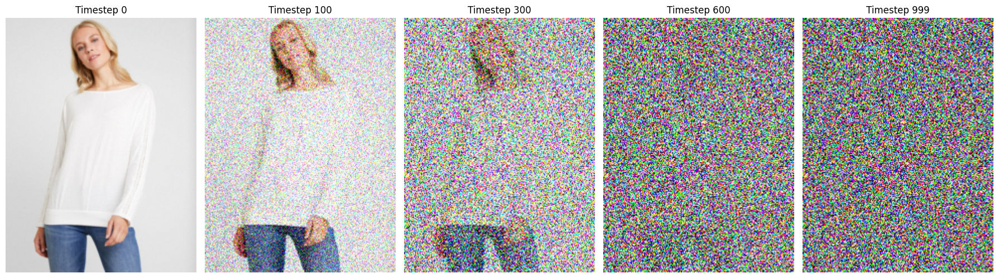

Forward diffusion visualization completed!


In [ ]:

import matplotlib.pyplot as plt

test_batch = next(iter(train_loader))

clean_image = test_batch["target"].to(device)

test_noise = torch.randn_like(clean_image)

test_steps = [0, 100, 300, 600, 999]

fig, axes = plt.subplots(
    1, 5, figsize=(18, 5)
)

for ax, step in zip(axes, test_steps):

    timestep = torch.tensor(
        [step],
        device=device
    )

    noisy_image, _ = add_noise(
        clean_image,
        timestep,
        scheduler,
        test_noise
    )

    display_image = (
        noisy_image[0].detach().cpu()
        .permute(1, 2, 0)
    )

    display_image = (
        display_image * 0.5 + 0.5
    ).clamp(0, 1)

    ax.imshow(display_image.numpy())
    ax.set_title(f"Timestep {step}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Forward diffusion visualization completed!")


## Phase 5.4 — Implement the Noise Prediction Loss
Now VESTA will compare its predicted noise against the actual noise added to the target.

We will use Mean Squared Error (MSE).
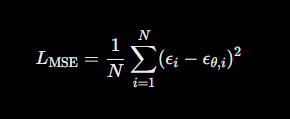

In [ ]:

def vesta_diffusion_loss(
    model,
    batch,
    scheduler,
    device
):

    target = batch["target"].to(device)

    person = batch["agnostic"].to(device)
    garment = batch["garment"].to(device)
    mask = batch["cloth_mask"].to(device)
    pose = batch["pose"].to(device)

    batch_size = target.shape[0]

    timesteps = torch.randint(
        0,
        scheduler.timesteps,
        (batch_size,),
        device=device
    )

    noisy_target, actual_noise = add_noise(
        target,
        timesteps,
        scheduler
    )

    predicted_noise = model(
        noisy_target=noisy_target,
        timesteps=timesteps,
        person=person,
        garment=garment,
        mask=mask,
        pose=pose
    )

    loss = F.mse_loss(
        predicted_noise,
        actual_noise
    )

    return loss


print("VESTA diffusion loss function created!")


VESTA diffusion loss function created!


## Phase 5.5 — Test VESTA Noise Prediction
Now we connect the scheduler, forward diffusion and custom U-Net.

This is our first complete diffusion loss calculation.

In [ ]:

model.train()

test_batch = next(iter(train_loader))

model.zero_grad(set_to_none=True)

loss = vesta_diffusion_loss(
    model=model,
    batch=test_batch,
    scheduler=scheduler,
    device=device
)

print("VESTA Diffusion Test")
print("--------------------")
print("Loss:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())

assert torch.isfinite(loss), "Invalid diffusion loss!"

print("Diffusion loss test PASSED!")


VESTA Diffusion Test
--------------------
Loss: 1.129738211631775
Loss is finite: True
Diffusion loss test PASSED!


## Phase 5.6 — Verify Backpropagation

In [ ]:

model.zero_grad(set_to_none=True)

loss = vesta_diffusion_loss(
    model=model,
    batch=test_batch,
    scheduler=scheduler,
    device=device
)

loss.backward()

gradient_count = 0
missing_gradients = []

for name, parameter in model.named_parameters():

    if parameter.requires_grad:

        if parameter.grad is not None:
            gradient_count += 1
        else:
            missing_gradients.append(name)

print("Gradient Verification")
print("---------------------")

print("Parameters with gradients:", gradient_count)
print("Parameters missing gradients:", len(missing_gradients))

print("Loss:", loss.item())

if missing_gradients:
    print("Missing gradient examples:", missing_gradients[:10])

assert gradient_count > 0, "No gradients were generated!"

print("Backpropagation test PASSED!")

model.zero_grad(set_to_none=True)


Gradient Verification
---------------------
Parameters with gradients: 164
Parameters missing gradients: 0
Loss: 1.1344882249832153
Backpropagation test PASSED!


## Phase 5.7 — Save Diffusion Configuration

In [ ]:

import json

DIFFUSION_CONFIG = {
    "model": "VESTAConditionalUNet",
    "timesteps": 1000,
    "beta_start": 0.0001,
    "beta_end": 0.02,
    "noise_schedule": "linear",
    "prediction_type": "epsilon",
    "loss_function": "MSE",
    "image_height": 256,
    "image_width": 192
}

diffusion_config_path = (
    PROJECT_ROOT / "configs/diffusion_config.json"
)

with open(diffusion_config_path, "w") as f:
    json.dump(DIFFUSION_CONFIG, f, indent=4)

print("Diffusion configuration saved!")
print(diffusion_config_path)


Diffusion configuration saved!
/content/drive/MyDrive/VESTA_AI/configs/diffusion_config.json


## Phase 5.8 — Save Phase 5 Checkpoint

In [ ]:

phase5_checkpoint = (
    CHECKPOINT_DIR / "vesta_phase5_diffusion_ready.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "diffusion_config": DIFFUSION_CONFIG,
        "optimizer_state": None,
        "status": "diffusion_verified_not_trained"
    },
    phase5_checkpoint
)

print("Phase 5 checkpoint saved!")
print(phase5_checkpoint)


Phase 5 checkpoint saved!
/content/drive/MyDrive/VESTA_AI/models/checkpoints/vesta_phase5_diffusion_ready.pth



# Phase 6 — VESTA Model Training

Objectives:
1. Initialize AdamW optimizer.
2. Configure mixed-precision training.
3. Implement gradient accumulation.
4. Train on 450 paired samples.
5. Validate on 50 held-out pairs.
6. Track training and validation loss.
7. Save model checkpoints.
8. Support training resumption.


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import time
import json

TRAIN_CONFIG = {
    "epochs": 10,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "batch_size": 1,
    "gradient_accumulation_steps": 4,
    "mixed_precision": True,
    "max_grad_norm": 1.0,
    "save_every_epoch": True
}

print(json.dumps(TRAIN_CONFIG, indent=4))


{
    "epochs": 10,
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "batch_size": 1,
    "gradient_accumulation_steps": 4,
    "mixed_precision": true,
    "max_grad_norm": 1.0,
    "save_every_epoch": true
}


## Phase 6.2 — Initialize optimizer

In [ ]:

optimizer = optim.AdamW(
    model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"]
)

lr_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=TRAIN_CONFIG["epochs"]
)

use_amp = (
    TRAIN_CONFIG["mixed_precision"]
    and device.type == "cuda"
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("Optimizer:", optimizer.__class__.__name__)
print("Mixed precision:", use_amp)
print("Gradient accumulation:",
      TRAIN_CONFIG["gradient_accumulation_steps"])


Optimizer: AdamW
Mixed precision: True
Gradient accumulation: 4


## Phase 6.3 — Create the training loop

In [ ]:

from tqdm.auto import tqdm

def train_one_epoch(
    model,
    train_loader,
    optimizer,
    scheduler,
    scaler,
    device,
    epoch
):

    model.train()

    total_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    accumulation_steps = TRAIN_CONFIG[
        "gradient_accumulation_steps"
    ]

    total_batches = len(train_loader)

    progress = tqdm(
        enumerate(train_loader),
        total=total_batches,
        desc=f"Epoch {epoch}"
    )

    for step, batch in progress:

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            loss = vesta_diffusion_loss(
                model,
                batch,
                scheduler,
                device
            )

            scaled_loss = loss / accumulation_steps

        scaler.scale(scaled_loss).backward()

        should_update = (
            (step + 1) % accumulation_steps == 0
            or (step + 1) == total_batches
        )

        if should_update:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                TRAIN_CONFIG["max_grad_norm"]
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / total_batches


print("Training function defined!")


Training function defined!


## Phase 6.4 — Create validation function

In [ ]:

def validate_model(
    model,
    val_loader,
    scheduler,
    device
):

    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for batch in tqdm(
            val_loader,
            desc="Validation"
        ):

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):

                loss = vesta_diffusion_loss(
                    model,
                    batch,
                    scheduler,
                    device
                )

            total_loss += loss.item()

    return total_loss / len(val_loader)


print("Validation function defined!")


Validation function defined!


## Phase 6.5 — Save training checkpoints

In [ ]:

def save_training_checkpoint(
    epoch,
    model,
    optimizer,
    lr_scheduler,
    scaler,
    train_loss,
    val_loss
):

    path = CHECKPOINT_DIR / "vesta_latest.pth"

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "lr_scheduler_state_dict": lr_scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "model_config": CONFIG["model"],
            "diffusion_config": DIFFUSION_CONFIG,
            "status": "training"
        },
        path
    )

    print("Checkpoint saved:", path)


print("Checkpoint manager initialized!")


Checkpoint manager initialized!


## Phase 6.6 — Correct gradient accumulation

In [ ]:

def train_one_epoch(
    model,
    train_loader,
    optimizer,
    diffusion_scheduler,
    scaler,
    device,
    epoch
):

    model.train()

    total_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    accumulation_steps = TRAIN_CONFIG[
        "gradient_accumulation_steps"
    ]

    total_batches = len(train_loader)

    for step, batch in tqdm(
        enumerate(train_loader),
        total=total_batches,
        desc=f"Training Epoch {epoch}"
    ):

        # Correctly handle the final incomplete group.
        group_start = (
            step // accumulation_steps
        ) * accumulation_steps

        group_size = min(
            accumulation_steps,
            total_batches - group_start
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            loss = vesta_diffusion_loss(
                model,
                batch,
                diffusion_scheduler,
                device
            )

            scaled_loss = loss / group_size

        scaler.scale(scaled_loss).backward()

        should_update = (
            (step + 1) % accumulation_steps == 0
            or (step + 1) == total_batches
        )

        if should_update:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                TRAIN_CONFIG["max_grad_norm"]
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()

    return total_loss / total_batches


print("Updated training loop ready!")


Updated training loop ready!


## Phase 6.7 — Run your first training epoch

In [ ]:

print("Starting VESTA first training epoch...")

start_time = time.time()

train_loss = train_one_epoch(
    model=model,
    train_loader=train_loader,
    optimizer=optimizer,
    diffusion_scheduler=scheduler,
    scaler=scaler,
    device=device,
    epoch=1
)

elapsed = time.time() - start_time

print("\nFIRST EPOCH COMPLETED")
print("---------------------")
print("Training loss:", train_loss)
print("Time:", round(elapsed / 60, 2), "minutes")


Starting VESTA first training epoch...


Training Epoch 1:   0%|          | 0/450 [00:00<?, ?it/s]


FIRST EPOCH COMPLETED
---------------------
Training loss: 0.9047439983155993
Time: 0.79 minutes


## Phase 6.8 — Run validation

In [ ]:

val_loss = validate_model(
    model=model,
    val_loader=val_loader,
    scheduler=scheduler,
    device=device
)

print("Validation loss:", val_loss)


Validation:   0%|          | 0/50 [00:00<?, ?it/s]

Validation loss: 0.8220931518077851


## Phase 6.9 — Update learning rate and save checkpoint

In [ ]:

lr_scheduler.step()

save_training_checkpoint(
    epoch=1,
    model=model,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    scaler=scaler,
    train_loss=train_loss,
    val_loss=val_loss
)

print("First training checkpoint saved!")


Checkpoint saved: /content/drive/MyDrive/VESTA_AI/models/checkpoints/vesta_latest.pth
First training checkpoint saved!


## Phase 6.10 — Record training history

In [ ]:

history_path = PROJECT_ROOT / "training_history.json"

training_history = {
    "epoch": 1,
    "train_loss": float(train_loss),
    "validation_loss": float(val_loss),
    "learning_rate": optimizer.param_groups[0]["lr"]
}

with open(history_path, "w") as f:
    json.dump(training_history, f, indent=4)

print("Training history saved!")
print(training_history)


Training history saved!
{'epoch': 1, 'train_loss': 0.9047439983155993, 'validation_loss': 0.8220931518077851, 'learning_rate': 9.755282581475769e-05}


## Phase 6.11 — Create checkpoint resume function
This function restores the model weights, optimizer, learning-rate scheduler, and mixed-precision scaler from the latest checkpoint.

In [ ]:
def load_training_checkpoint(
    checkpoint_path,
    model,
    optimizer,
    lr_scheduler,
    scaler,
    device
):
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    lr_scheduler.load_state_dict(
        checkpoint["lr_scheduler_state_dict"]
    )

    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    print("Checkpoint restored successfully!")
    print("Last completed epoch:", checkpoint["epoch"])
    print("Previous training loss:", checkpoint["train_loss"])
    print("Previous validation loss:", checkpoint["val_loss"])

    return checkpoint


print("Checkpoint resume function ready!")

Checkpoint resume function ready!


## Phase 6.12 — Restore Epoch 1 checkpoint

Load the saved checkpoint to ensure training continues from the exact state after Epoch 1.

In [ ]:
checkpoint_path = CHECKPOINT_DIR / "vesta_latest.pth"

checkpoint = load_training_checkpoint(
    checkpoint_path=checkpoint_path,
    model=model,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    scaler=scaler,
    device=device
)

start_epoch = checkpoint["epoch"] + 1
total_epochs = TRAIN_CONFIG["epochs"]

print("Next epoch:", start_epoch)
print("Total epochs:", total_epochs)

Checkpoint restored successfully!
Last completed epoch: 1
Previous training loss: 0.9047439983155993
Previous validation loss: 0.8220931518077851
Next epoch: 2
Total epochs: 10


## Phase 6.13 — Prepare persistent training history

Convert the existing Epoch 1 history into a list. This prevents previous results from being overwritten.

In [ ]:
history_path = PROJECT_ROOT / "training_history.json"

if history_path.exists():
    with open(history_path, "r") as f:
        old_history = json.load(f)

    if isinstance(old_history, dict):
        training_history = [old_history]
    else:
        training_history = old_history

else:
    training_history = []

print("Existing recorded epochs:", len(training_history))
print("History prepared!")

Existing recorded epochs: 1
History prepared!


## Phase 6.14 — Train VESTA from Epoch 2 to Epoch 10

This cell will:
- Train one epoch at a time.
- Calculate validation loss after each epoch.
- Update the learning-rate scheduler.
- Save a checkpoint after every epoch.
- Append results to training_history.json.

In [ ]:
for epoch in range(start_epoch, total_epochs + 1):

    print("\n" + "=" * 50)
    print(f"VESTA TRAINING — EPOCH {epoch}/{total_epochs}")
    print("=" * 50)

    start_time = time.time()

    # Training
    train_loss = train_one_epoch(
        model=model,
        train_loader=train_loader,
        optimizer=optimizer,
        diffusion_scheduler=scheduler,
        scaler=scaler,
        device=device,
        epoch=epoch
    )

    # Validation
    val_loss = validate_model(
        model=model,
        val_loader=val_loader,
        scheduler=scheduler,
        device=device
    )

    # Update learning rate
    lr_scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    elapsed = (time.time() - start_time) / 60

    # Record results
    epoch_record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_loss": float(val_loss),
        "learning_rate": float(current_lr),
        "time_minutes": round(elapsed, 2)
    }

    training_history.append(epoch_record)

    # Save checkpoint
    save_training_checkpoint(
        epoch=epoch,
        model=model,
        optimizer=optimizer,
        lr_scheduler=lr_scheduler,
        scaler=scaler,
        train_loss=train_loss,
        val_loss=val_loss
    )

    # Save complete history
    with open(history_path, "w") as f:
        json.dump(training_history, f, indent=4)

    print("\nEPOCH COMPLETED")
    print("-----------------------------")
    print(f"Training loss:   {train_loss:.6f}")
    print(f"Validation loss: {val_loss:.6f}")
    print(f"Learning rate:   {current_lr:.8f}")
    print(f"Time:            {elapsed:.2f} minutes")
    print("Checkpoint and history saved.")

print("\nVESTA TRAINING FINISHED!")


VESTA TRAINING — EPOCH 2/10


Training Epoch 2:   0%|          | 0/450 [00:00<?, ?it/s]

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

Checkpoint saved: /content/drive/MyDrive/VESTA_AI/models/checkpoints/vesta_latest.pth

EPOCH COMPLETED
-----------------------------
Training loss:   0.781389
Validation loss: 0.752814
Learning rate:   0.00009045
Time:            0.83 minutes
Checkpoint and history saved.

VESTA TRAINING — EPOCH 3/10


Training Epoch 3:   0%|          | 0/450 [00:00<?, ?it/s]

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

... (18 outputs left out)

Checkpoint saved: /content/drive/MyDrive/VESTA_AI/models/checkpoints/vesta_latest.pth

EPOCH COMPLETED
-----------------------------
Training loss:   0.659578
Validation loss: 0.661339
Learning rate:   0.00000245
Time:            0.84 minutes
Checkpoint and history saved.

VESTA TRAINING — EPOCH 10/10


Training Epoch 10:   0%|          | 0/450 [00:00<?, ?it/s]

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

Checkpoint saved: /content/drive/MyDrive/VESTA_AI/models/checkpoints/vesta_latest.pth

EPOCH COMPLETED
-----------------------------
Training loss:   0.655645
Validation loss: 0.649904
Learning rate:   0.00000000
Time:            0.83 minutes
Checkpoint and history saved.

VESTA TRAINING FINISHED!


## Phase 6.15 — Display training progress

In [ ]:
import pandas as pd

history_df = pd.DataFrame(training_history)

display(history_df)

print("\nFinal training loss:",
      history_df.iloc[-1]["train_loss"])

print("Final validation loss:",
      history_df.iloc[-1]["validation_loss"])

,epoch,train_loss,validation_loss,learning_rate,time_minutes
0,1,0.904744,0.822093,0.000098,NaN
1,2,0.781389,0.752814,0.000090,0.83
2,3,0.738789,0.728573,0.000079,0.86
3,4,0.713090,0.708221,0.000065,0.88
4,5,0.694787,0.685264,0.000050,0.86
5,6,0.675033,0.675823,0.000035,0.85
6,7,0.664492,0.664663,0.000021,0.85
7,8,0.658956,0.663709,0.000010,0.83
8,9,0.659578,0.661339,0.000002,0.84
9,10,0.655645,0.649904,0.000000,0.83



Final training loss: 0.6556449842453003
Final validation loss: 0.6499040007591248


# Phase 7 — Generate the first virtual try-on image

## Phase 7.1 — Implement reverse diffusion

At each timestep, the model predicts noise and the scheduler removes part of that noise. This repeats from timestep 999 down to 0.

In [ ]:
@torch.no_grad()
def vesta_generate(
    model,
    scheduler,
    person,
    garment,
    mask,
    pose,
    device
):
    model.eval()

    batch_size = person.shape[0]
    image_shape = person.shape

    # Begin with random Gaussian noise
    image = torch.randn(
        image_shape,
        device=device
    )

    betas = scheduler.betas
    alphas = scheduler.alphas
    alpha_cumprod = scheduler.alpha_cumprod

    for t in tqdm(
        reversed(range(scheduler.timesteps)),
        total=scheduler.timesteps,
        desc="Generating VESTA image"
    ):

        timesteps = torch.full(
            (batch_size,),
            t,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(
            noisy_target=image,
            timesteps=timesteps,
            person=person,
            garment=garment,
            mask=mask,
            pose=pose
        )

        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_cumprod[t]

        if t > 0:
            alpha_bar_previous = alpha_cumprod[t - 1]
        else:
            alpha_bar_previous = torch.tensor(
                1.0,
                device=device
            )

        # DDPM posterior variance
        posterior_variance = (
            beta_t
            * (1.0 - alpha_bar_previous)
            / (1.0 - alpha_bar_t)
        )

        # Predicted previous image
        image = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            image
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * predicted_noise
        )

        if t > 0:
            noise = torch.randn_like(image)

            image = (
                image
                + torch.sqrt(posterior_variance) * noise
            )

    return image.clamp(-1, 1)


print("VESTA reverse diffusion sampler ready!")

VESTA reverse diffusion sampler ready!


## Phase 7.2 — Generate one test image

We'll take one validation sample and use its conditioning inputs to generate a predicted result.

In [ ]:
test_batch = next(iter(val_loader))

person = test_batch["agnostic"][:1].to(device)
garment = test_batch["garment"][:1].to(device)
mask = test_batch["cloth_mask"][:1].to(device)
pose = test_batch["pose"][:1].to(device)

generated_image = vesta_generate(
    model=model,
    scheduler=scheduler,
    person=person,
    garment=garment,
    mask=mask,
    pose=pose,
    device=device
)

print("Generated image shape:", generated_image.shape)
print("Generation completed!")

Generating VESTA image:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated image shape: torch.Size([1, 3, 256, 192])
Generation completed!


## Phase 7.3 — Visualize the result

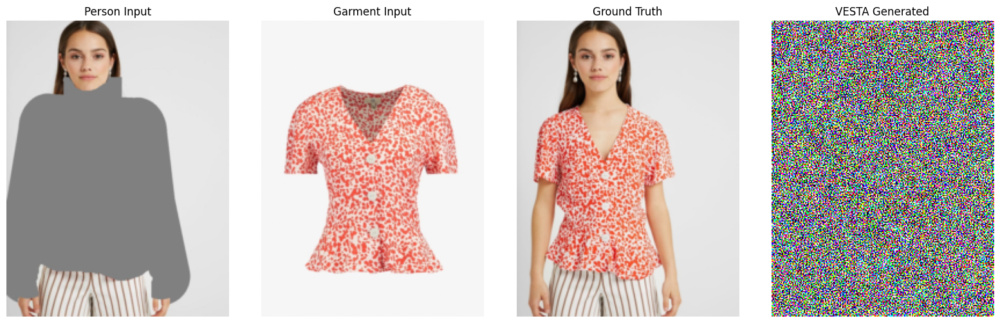

In [ ]:
import matplotlib.pyplot as plt

def denormalize_image(tensor):
    return (
        tensor.detach()
        .cpu()
        .squeeze(0)
        .permute(1, 2, 0)
        .mul(0.5)
        .add(0.5)
        .clamp(0, 1)
        .numpy()
    )

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    denormalize_image(person),
    denormalize_image(garment),
    denormalize_image(test_batch["target"][:1]),
    denormalize_image(generated_image)
]

titles = [
    "Person Input",
    "Garment Input",
    "Ground Truth",
    "VESTA Generated"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Phase 8 — Model Diagnosis and Generation Improvement.

## Phase 8.1 — Controlled denoising diagnostic

We'll use one validation image and the same fixed noise tensor at seven diffusion timesteps. We'll measure:
- Model noise-prediction MSE.
- Baseline noise-prediction MSE.
- Improvement over the baseline.

In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

# Use one held-out validation sample
diagnostic_batch = next(iter(val_loader))

target = diagnostic_batch["target"][:1].to(device)
person = diagnostic_batch["agnostic"][:1].to(device)
garment = diagnostic_batch["garment"][:1].to(device)
mask = diagnostic_batch["cloth_mask"][:1].to(device)
pose = diagnostic_batch["pose"][:1].to(device)

# Fixed noise makes comparisons reproducible
generator = torch.Generator(device=device)
generator.manual_seed(1234)

fixed_noise = torch.randn(
    target.shape,
    generator=generator,
    device=device
)

test_timesteps = [0, 50, 100, 250, 500, 750, 999]

diagnostic_results = []

model.eval()

with torch.no_grad():

    for timestep_value in test_timesteps:

        timesteps = torch.tensor(
            [timestep_value],
            device=device,
            dtype=torch.long
        )

        noisy_target, actual_noise = add_noise(
            target,
            timesteps,
            scheduler,
            noise=fixed_noise
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            predicted_noise = model(
                noisy_target=noisy_target,
                timesteps=timesteps,
                person=person,
                garment=garment,
                mask=mask,
                pose=pose
            )

        # Calculate errors in float32
        model_mse = torch.nn.functional.mse_loss(
            predicted_noise.float(),
            actual_noise.float()
        ).item()

        # Baseline: predict zero noise
        baseline_mse = torch.nn.functional.mse_loss(
            torch.zeros_like(actual_noise),
            actual_noise
        ).item()

        improvement = (
            (baseline_mse - model_mse)
            / baseline_mse
        ) * 100

        diagnostic_results.append({
            "timestep": timestep_value,
            "model_mse": model_mse,
            "baseline_mse": baseline_mse,
            "improvement_percent": improvement
        })

diagnostic_df = pd.DataFrame(diagnostic_results)

display(diagnostic_df)

print("Denoising diagnostic completed!")

,timestep,model_mse,baseline_mse,improvement_percent
0,0,1.088427,1.00713,-8.072112
1,50,0.837363,1.00713,16.856505
2,100,0.741734,1.00713,26.351759
3,250,0.662854,1.00713,34.183908
4,500,0.640180,1.00713,36.435270
5,750,0.638540,1.00713,36.598058
6,999,0.638697,1.00713,36.582469


Denoising diagnostic completed!


## Phase 8.2 — Visualize denoising performance

This chart compares VESTA's noise-prediction error with the zero-noise baseline. We want the VESTA line to remain below the baseline across as many timesteps as possible.

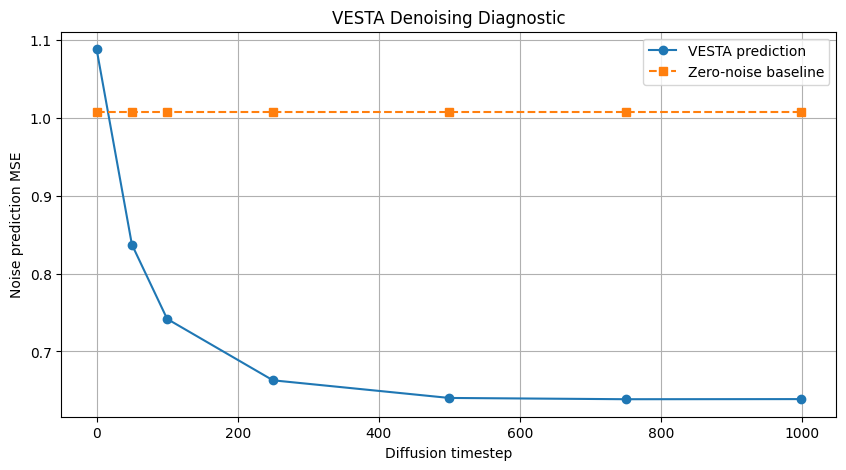

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    diagnostic_df["timestep"],
    diagnostic_df["model_mse"],
    marker="o",
    label="VESTA prediction"
)

plt.plot(
    diagnostic_df["timestep"],
    diagnostic_df["baseline_mse"],
    marker="s",
    linestyle="--",
    label="Zero-noise baseline"
)

plt.xlabel("Diffusion timestep")
plt.ylabel("Noise prediction MSE")
plt.title("VESTA Denoising Diagnostic")
plt.legend()
plt.grid(True)
plt.show()

## Phase 8.3 — Check overall diagnostic performance

In [ ]:
average_model_mse = diagnostic_df["model_mse"].mean()
average_baseline_mse = diagnostic_df["baseline_mse"].mean()

overall_improvement = (
    (average_baseline_mse - average_model_mse)
    / average_baseline_mse
) * 100

print("VESTA Diagnostic Summary")
print("------------------------")
print(f"Average model MSE:    {average_model_mse:.6f}")
print(f"Average baseline MSE: {average_baseline_mse:.6f}")
print(f"Overall improvement:  {overall_improvement:.2f}%")

if overall_improvement > 0:
    print("\nVESTA performs better than the zero-noise baseline overall.")
else:
    print("\nVESTA does not beat the baseline overall.")

VESTA Diagnostic Summary
------------------------
Average model MSE:    0.749685
Average baseline MSE: 1.007130
Overall improvement:  25.56%

VESTA performs better than the zero-noise baseline overall.


## Phase 8.4 — Multi-sample denoising evaluation

This test will evaluate multiple validation images with independently generated noise. It will calculate average MSE and improvement at each timestep.

In [ ]:
import torch
import pandas as pd
from tqdm.auto import tqdm

model.eval()

test_timesteps = [0, 50, 100, 250, 500, 750, 999]
max_samples = 32

results = []

with torch.no_grad():

    for batch_idx, batch in enumerate(
        tqdm(val_loader, desc="Evaluating validation samples")
    ):

        if batch_idx * val_loader.batch_size >= max_samples:
            break

        target = batch["target"].to(device)
        person = batch["agnostic"].to(device)
        garment = batch["garment"].to(device)
        mask = batch["cloth_mask"].to(device)
        pose = batch["pose"].to(device)

        batch_size = target.shape[0]

        for t in test_timesteps:

            timesteps = torch.full(
                (batch_size,),
                t,
                device=device,
                dtype=torch.long
            )

            noise = torch.randn_like(target)

            noisy_target, actual_noise = add_noise(
                target,
                timesteps,
                scheduler,
                noise=noise
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):

                predicted_noise = model(
                    noisy_target=noisy_target,
                    timesteps=timesteps,
                    person=person,
                    garment=garment,
                    mask=mask,
                    pose=pose
                )

            model_mse = (
                (predicted_noise.float() - actual_noise.float())
                .pow(2)
                .flatten(1)
                .mean(dim=1)
            )

            baseline_mse = (
                actual_noise.float()
                .pow(2)
                .flatten(1)
                .mean(dim=1)
            )

            for i in range(batch_size):

                results.append({
                    "timestep": t,
                    "model_mse": model_mse[i].item(),
                    "baseline_mse": baseline_mse[i].item()
                })

        if len(results) >= max_samples * len(test_timesteps):
            break

results_df = pd.DataFrame(results)

summary_df = (
    results_df
    .groupby("timestep")
    .agg(
        model_mse=("model_mse", "mean"),
        baseline_mse=("baseline_mse", "mean"),
        samples=("model_mse", "count")
    )
    .reset_index()
)

summary_df["improvement_percent"] = (
    (summary_df["baseline_mse"] - summary_df["model_mse"])
    / summary_df["baseline_mse"]
) * 100

display(summary_df)

print("Multi-sample evaluation completed!")

Evaluating validation samples:   0%|          | 0/50 [00:00<?, ?it/s]

,timestep,model_mse,baseline_mse,samples,improvement_percent
0,0,1.019590,0.999824,32,-1.976983
1,50,0.759230,0.999495,32,24.038666
2,100,0.694648,0.999014,32,30.466586
3,250,0.650561,0.999535,32,34.913583
4,500,0.636316,0.999784,32,36.354628
5,750,0.635207,0.999976,32,36.477773
6,999,0.634646,0.998901,32,36.465544


Multi-sample evaluation completed!


## Phase 8.5 — Visualize the multi-sample results

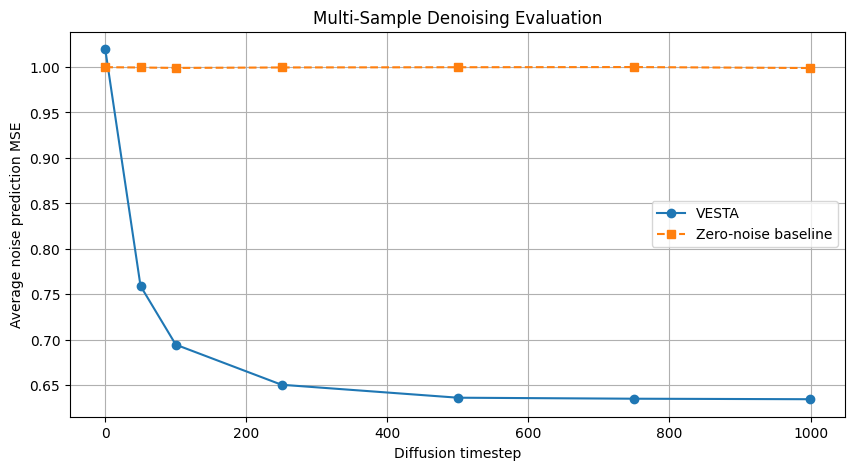

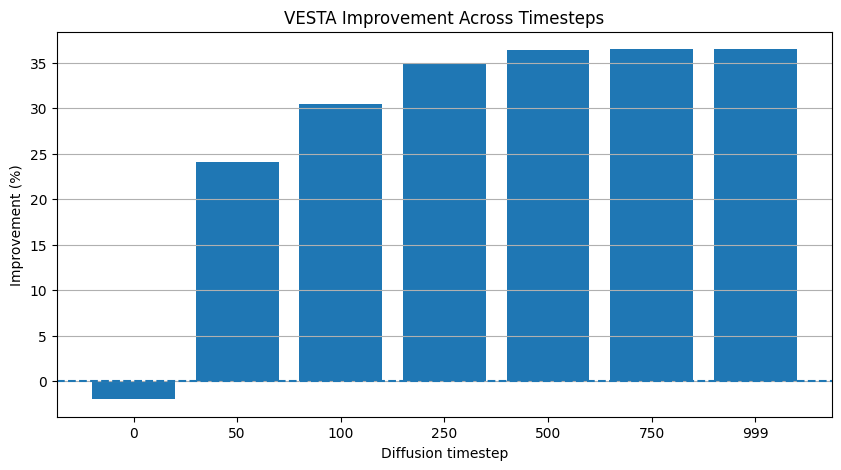

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    summary_df["timestep"],
    summary_df["model_mse"],
    marker="o",
    label="VESTA"
)

plt.plot(
    summary_df["timestep"],
    summary_df["baseline_mse"],
    marker="s",
    linestyle="--",
    label="Zero-noise baseline"
)

plt.xlabel("Diffusion timestep")
plt.ylabel("Average noise prediction MSE")
plt.title("Multi-Sample Denoising Evaluation")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    summary_df["timestep"].astype(str),
    summary_df["improvement_percent"]
)

plt.axhline(0, linestyle="--")
plt.xlabel("Diffusion timestep")
plt.ylabel("Improvement (%)")
plt.title("VESTA Improvement Across Timesteps")
plt.grid(axis="y")
plt.show()

## Phase 8.6 — Controlled image reconstruction
For each selected timestep:
1. Add a known amount of noise to a real target image.
2. Ask VESTA to predict that noise.
3. Estimate the original image using the predicted noise.
4. Compare the reconstructed image against the ground truth.

In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

model.eval()

# Get one validation sample
batch = next(iter(val_loader))

target = batch["target"][:1].to(device)
person = batch["agnostic"][:1].to(device)
garment = batch["garment"][:1].to(device)
mask = batch["cloth_mask"][:1].to(device)
pose = batch["pose"][:1].to(device)

# Fixed noise for reproducibility
generator = torch.Generator(device=device)
generator.manual_seed(2026)

fixed_noise = torch.randn(
    target.shape,
    generator=generator,
    device=device
)

test_timesteps = [0, 50, 100, 250, 500, 750, 999]

reconstruction_results = []
reconstructed_images = {}

with torch.no_grad():

    for t in test_timesteps:

        timesteps = torch.tensor(
            [t],
            device=device,
            dtype=torch.long
        )

        noisy_target, actual_noise = add_noise(
            target,
            timesteps,
            scheduler,
            noise=fixed_noise
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            predicted_noise = model(
                noisy_target=noisy_target,
                timesteps=timesteps,
                person=person,
                garment=garment,
                mask=mask,
                pose=pose
            )

        # Obtain alpha cumulative product
        alpha_bar = scheduler.alpha_cumprod[t].to(device)

        # Reconstruct predicted original image
        reconstructed = (
            noisy_target.float()
            - torch.sqrt(1.0 - alpha_bar)
            * predicted_noise.float()
        ) / torch.sqrt(alpha_bar)

        # Store reconstruction for visualization
        reconstructed_images[t] = reconstructed.clamp(-1, 1)

        # Compare raw, unclamped reconstruction errors
        reconstruction_mse = F.mse_loss(
            reconstructed,
            target.float()
        ).item()

        noisy_input_mse = F.mse_loss(
            noisy_target.float(),
            target.float()
        ).item()

        reconstruction_results.append({
            "timestep": t,
            "noisy_input_mse": noisy_input_mse,
            "reconstruction_mse": reconstruction_mse,
            "improvement_percent": (
                (noisy_input_mse - reconstruction_mse)
                / max(noisy_input_mse, 1e-12)
            ) * 100
        })

reconstruction_df = pd.DataFrame(reconstruction_results)

display(reconstruction_df)

print("Controlled reconstruction test completed!")

,timestep,noisy_input_mse,reconstruction_mse,improvement_percent
0,0,0.000100,0.000109,-8.331241e+00
1,50,0.030277,0.025914,1.441113e+01
2,100,0.106662,0.086813,1.860935e+01
3,250,0.516840,0.607826,-1.760430e+01
4,500,1.168797,7.585208,-5.489759e+02
5,750,1.414895,192.796738,-1.352622e+04
6,999,1.464110,15821.434570,-1.080518e+06


Controlled reconstruction test completed!


## Phase 8.7 — Visualize reconstructed images
Compare the original target, noisy inputs and VESTA reconstructions. This will help us identify whether the model is recovering recognizable image structure.

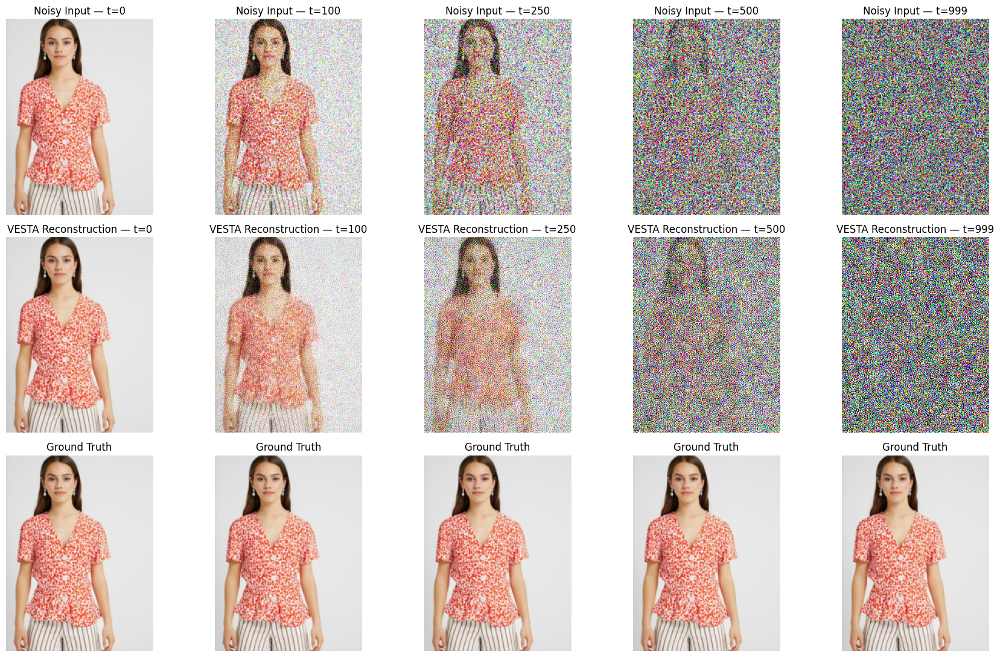

In [ ]:
def show_tensor_image(tensor):
    return (
        tensor.detach()
        .cpu()
        .squeeze(0)
        .permute(1, 2, 0)
        .mul(0.5)
        .add(0.5)
        .clamp(0, 1)
        .numpy()
    )

fig, axes = plt.subplots(
    3, 5,
    figsize=(18, 11)
)

selected_timesteps = [0, 100, 250, 500, 999]

for col, t in enumerate(selected_timesteps):

    timestep_tensor = torch.tensor(
        [t],
        device=device,
        dtype=torch.long
    )

    noisy, _ = add_noise(
        target,
        timestep_tensor,
        scheduler,
        noise=fixed_noise
    )

    axes[0, col].imshow(show_tensor_image(noisy))
    axes[0, col].set_title(f"Noisy Input — t={t}")

    axes[1, col].imshow(
        show_tensor_image(reconstructed_images[t])
    )
    axes[1, col].set_title(f"VESTA Reconstruction — t={t}")

    axes[2, col].imshow(show_tensor_image(target))
    axes[2, col].set_title("Ground Truth")

    for row in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Phase 8.8 — Compare reconstruction errors

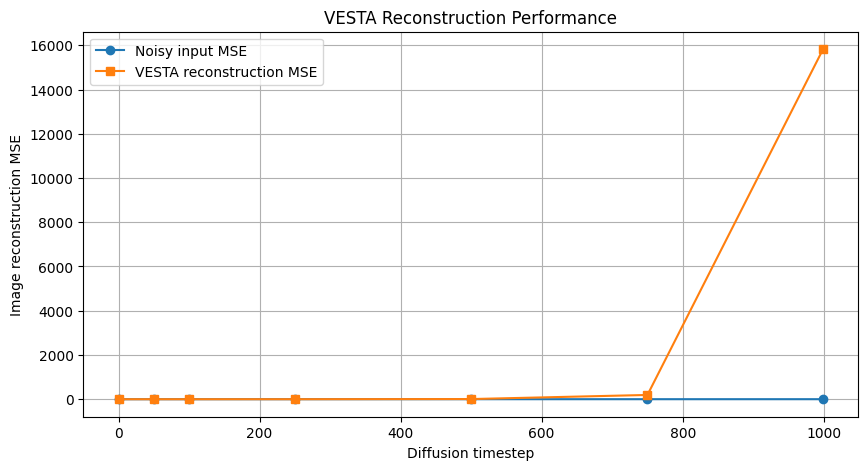

,timestep,improvement_percent
0,0,-8.331241e+00
1,50,1.441113e+01
2,100,1.860935e+01
3,250,-1.760430e+01
4,500,-5.489759e+02
5,750,-1.352622e+04
6,999,-1.080518e+06


In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    reconstruction_df["timestep"],
    reconstruction_df["noisy_input_mse"],
    marker="o",
    label="Noisy input MSE"
)

plt.plot(
    reconstruction_df["timestep"],
    reconstruction_df["reconstruction_mse"],
    marker="s",
    label="VESTA reconstruction MSE"
)

plt.xlabel("Diffusion timestep")
plt.ylabel("Image reconstruction MSE")
plt.title("VESTA Reconstruction Performance")
plt.legend()
plt.grid(True)
plt.show()

display(
    reconstruction_df[
        ["timestep", "improvement_percent"]
    ]
)

## Phase 8.9 — Diagnose prediction error amplification
We will use the existing diagnostic sample and calculate the theoretical amplification factor at each timestep.

In [ ]:
import pandas as pd
import torch
import torch.nn.functional as F

amplification_results = []

model.eval()

with torch.no_grad():

    for t in [0, 50, 100, 250, 500, 750, 999]:

        timesteps = torch.tensor(
            [t],
            device=device,
            dtype=torch.long
        )

        noisy_target, actual_noise = add_noise(
            target,
            timesteps,
            scheduler,
            noise=fixed_noise
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            predicted_noise = model(
                noisy_target=noisy_target,
                timesteps=timesteps,
                person=person,
                garment=garment,
                mask=mask,
                pose=pose
            )

        alpha_bar = scheduler.alpha_cumprod[t].to(device)

        noise_mse = F.mse_loss(
            predicted_noise.float(),
            actual_noise.float()
        ).item()

        theoretical_amplification = (
            (1.0 - alpha_bar) / alpha_bar
        ).item()

        reconstruction_mse = (
            noise_mse * theoretical_amplification
        )

        amplification_results.append({
            "timestep": t,
            "alpha_bar": alpha_bar.item(),
            "noise_mse": noise_mse,
            "amplification_factor": theoretical_amplification,
            "predicted_reconstruction_mse": reconstruction_mse
        })

amplification_df = pd.DataFrame(amplification_results)

display(amplification_df)

print("Amplification diagnosis completed!")

,timestep,alpha_bar,noise_mse,amplification_factor,predicted_reconstruction_mse
0,0,0.999900,1.087278,0.000100,0.000109
1,50,0.969951,0.836486,0.030980,0.025914
2,100,0.895141,0.741093,0.117142,0.086813
3,250,0.521423,0.662243,0.917829,0.607826
4,500,0.077797,0.639885,11.854019,7.585208
5,750,0.003300,0.638366,302.015778,192.796743
6,999,0.000040,0.638552,24777.054688,15821.433644


Amplification diagnosis completed!


## Phase 8.10 — Visualize amplification

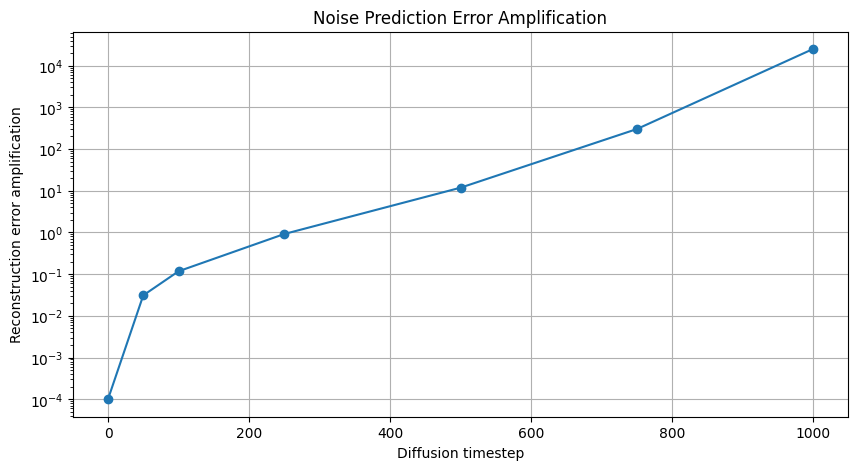

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    amplification_df["timestep"],
    amplification_df["amplification_factor"],
    marker="o"
)

plt.yscale("log")
plt.xlabel("Diffusion timestep")
plt.ylabel("Reconstruction error amplification")
plt.title("Noise Prediction Error Amplification")
plt.grid(True)
plt.show()

## Phase 8.11 — Replace the linear scheduler with a cosine scheduler

The current linear schedule reaches an extremely low cumulative alpha value at the final timestep. We'll replace it with a cosine schedule, which distributes signal degradation more gradually.

In [9]:
import math
import torch

class VESTACosineScheduler:

    def __init__(
        self,
        timesteps=1000,
        offset=0.008,
        device="cpu"
    ):
        self.timesteps = timesteps
        self.device = device

        steps = torch.arange(
            timesteps + 1,
            dtype=torch.float64,
            device=device
        )

        angles = (
            (steps / timesteps + offset)
            / (1 + offset)
        ) * (math.pi / 2)

        alpha_bar = torch.cos(angles).pow(2)
        alpha_bar = alpha_bar / alpha_bar[0]

        betas = 1 - (
            alpha_bar[1:] / alpha_bar[:-1]
        )

        self.betas = betas.clamp(0.000001, 0.999).float()
        self.alphas = 1.0 - self.betas

        self.alpha_cumprod = torch.cumprod(
            self.alphas,
            dim=0
        )

        self.sqrt_alpha_cumprod = torch.sqrt(
            self.alpha_cumprod
        )

        self.sqrt_one_minus_alpha_cumprod = torch.sqrt(
            1.0 - self.alpha_cumprod
        )

        print("Cosine scheduler initialized.")
        print("Timesteps:", self.timesteps)
        print("Alpha cumulative product at timestep 999:",
              self.alpha_cumprod[-1].item())


new_scheduler = VESTACosineScheduler(
    timesteps=1000,
    device=device
)

Cosine scheduler initialized.
Timesteps: 1000
Alpha cumulative product at timestep 999: 2.428733658632609e-09


## Phase 8.12 — Implement velocity prediction
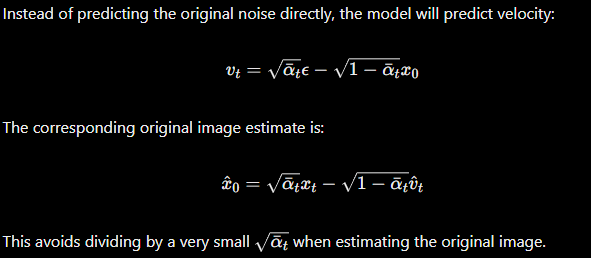


In [ ]:
def vesta_v_prediction_loss(
    model,
    batch,
    scheduler,
    device,
    snr_gamma=5.0
):

    target = batch["target"].to(device)

    person = batch["agnostic"].to(device)
    garment = batch["garment"].to(device)
    mask = batch["cloth_mask"].to(device)
    pose = batch["pose"].to(device)

    batch_size = target.shape[0]

    timesteps = torch.randint(
        0,
        scheduler.timesteps,
        (batch_size,),
        device=device
    )

    noise = torch.randn_like(target)

    noisy_target, _ = add_noise(
        target,
        timesteps,
        scheduler,
        noise=noise
    )

    alpha_bar = extract_values(
        scheduler.alpha_cumprod,
        timesteps,
        target.shape
    )

    # Velocity target
    velocity_target = (
        torch.sqrt(alpha_bar) * noise
        -
        torch.sqrt(1.0 - alpha_bar) * target
    )

    predicted_velocity = model(
        noisy_target=noisy_target,
        timesteps=timesteps,
        person=person,
        garment=garment,
        mask=mask,
        pose=pose
    )

    # Min-SNR weighting for velocity prediction
    snr = alpha_bar / (1.0 - alpha_bar).clamp(min=1e-8)

    weights = (
        torch.minimum(
            snr,
            torch.full_like(snr, snr_gamma)
        )
        / (snr + 1.0)
    )

    per_sample_loss = (
        (predicted_velocity.float() - velocity_target.float())
        .pow(2)
        .flatten(1)
        .mean(dim=1)
    )

    loss = (weights.flatten() * per_sample_loss).mean()

    return loss


print("VESTA velocity-prediction loss ready!")

VESTA velocity-prediction loss ready!


## Phase 8.13 — Verify the new scheduler and objective

Before starting training, check that:
- The cosine scheduler produces finite values.
- The new objective produces a finite loss.
- Gradients reach the model.

In [ ]:
# Check scheduler values
assert torch.isfinite(new_scheduler.betas).all()
assert torch.isfinite(new_scheduler.alpha_cumprod).all()

assert (new_scheduler.betas > 0).all()
assert (new_scheduler.betas < 1).all()

print("Cosine scheduler checks passed.")

# Test the new objective on one batch
test_batch = next(iter(train_loader))

model.eval()
model.zero_grad(set_to_none=True)

with torch.autocast(
    device_type=device.type,
    dtype=torch.float16,
    enabled=use_amp
):
    test_loss = vesta_v_prediction_loss(
        model=model,
        batch=test_batch,
        scheduler=new_scheduler,
        device=device
    )

assert torch.isfinite(test_loss), "Loss is not finite!"

test_loss.backward()

gradient_count = sum(
    1 for parameter in model.parameters()
    if parameter.grad is not None
)

print("Test v-prediction loss:", test_loss.item())
print("Parameters receiving gradients:", gradient_count)

model.zero_grad(set_to_none=True)

Cosine scheduler checks passed.
Test v-prediction loss: 0.017770951613783836
Parameters receiving gradients: 164


## Phase 8.14 — Validate the new objective before training
This test will help us establish a baseline for the new objective before retraining.

In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd

model.eval()

velocity_results = []
test_timesteps = [0, 50, 100, 250, 500, 750, 999]

with torch.no_grad():

    for batch in val_loader:

        target = batch["target"].to(device)
        person = batch["agnostic"].to(device)
        garment = batch["garment"].to(device)
        mask = batch["cloth_mask"].to(device)
        pose = batch["pose"].to(device)

        batch_size = target.shape[0]

        for t in test_timesteps:

            timesteps = torch.full(
                (batch_size,),
                t,
                device=device,
                dtype=torch.long
            )

            noise = torch.randn_like(target)

            noisy_target, _ = add_noise(
                target,
                timesteps,
                new_scheduler,
                noise=noise
            )

            alpha_bar = extract_values(
                new_scheduler.alpha_cumprod,
                timesteps,
                target.shape
            )

            velocity_target = (
                torch.sqrt(alpha_bar) * noise
                - torch.sqrt(1.0 - alpha_bar) * target
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):

                predicted_velocity = model(
                    noisy_target=noisy_target,
                    timesteps=timesteps,
                    person=person,
                    garment=garment,
                    mask=mask,
                    pose=pose
                )

            unweighted_mse = F.mse_loss(
                predicted_velocity.float(),
                velocity_target.float()
            ).item()

            snr = (
                alpha_bar / (1.0 - alpha_bar).clamp(min=1e-8)
            )

            weights = (
                torch.minimum(
                    snr,
                    torch.full_like(snr, 5.0)
                ) / (snr + 1.0)
            )

            weighted_mse = (
                (
                    (predicted_velocity.float() - velocity_target.float())
                    .pow(2)
                    .flatten(1)
                    .mean(dim=1)
                )
                * weights.flatten()
            ).mean().item()

            velocity_results.append({
                "timestep": t,
                "unweighted_mse": unweighted_mse,
                "weighted_mse": weighted_mse
            })

        # Evaluate first 32 validation images
        if len(velocity_results) >= 32 * len(test_timesteps):
            break

velocity_df = pd.DataFrame(velocity_results)

velocity_summary = (
    velocity_df.groupby("timestep")
    .mean(numeric_only=True)
    .reset_index()
)

display(velocity_summary)

print("Velocity objective baseline evaluation completed!")

,timestep,unweighted_mse,weighted_mse
0,0,1.028767,2.124713e-04
1,50,0.854290,3.534817e-02
2,100,0.775539,1.102215e-01
3,250,0.689257,5.311135e-01
4,500,0.645728,3.178824e-01
5,750,0.692773,9.919026e-02
6,999,0.829513,2.014665e-09


Velocity objective baseline evaluation completed!


## Phase 8.15 — Initialize VESTA v2 from scratch

We will create a separate model instance using the existing architecture. The architecture remains unchanged initially so that we can isolate the effect of the new diffusion objective.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import json
import time
from pathlib import Path
from tqdm.auto import tqdm

# Preserve the original VESTA model
model_v1 = model

# Separate V2 checkpoint directory
V2_DIR = PROJECT_ROOT / "models" / "v2"
V2_CHECKPOINT_DIR = V2_DIR / "checkpoints"

V2_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Initialize fresh model weights
model_v2 = VESTAConditionalUNet(
    base_channels=BASE_CHANNELS,
    time_dim=TIME_DIM
).to(device)

# Fresh optimizer
optimizer_v2 = optim.AdamW(
    model_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Fresh learning-rate scheduler
V2_EPOCHS = 10

lr_scheduler_v2 = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_v2,
    T_max=V2_EPOCHS,
    eta_min=1e-6
)

# Fresh mixed-precision scaler
scaler_v2 = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("VESTA v2 initialized!")
print("Trainable parameters:", sum(
    p.numel() for p in model_v2.parameters()
))
print("Optimizer: AdamW")
print("Diffusion objective: Velocity prediction")
print("Original V1 model preserved.")

VESTA v2 initialized!
Trainable parameters: 2365923
Optimizer: AdamW
Diffusion objective: Velocity prediction
Original V1 model preserved.


## Phase 8.16 — Verify the cosine scheduler

In [ ]:
new_scheduler = VESTACosineScheduler(
    timesteps=1000,
    device=device
)

assert torch.isfinite(new_scheduler.betas).all()
assert torch.isfinite(new_scheduler.alpha_cumprod).all()

assert torch.all(new_scheduler.betas > 0)
assert torch.all(new_scheduler.betas < 1)

assert torch.all(
    new_scheduler.alpha_cumprod[1:]
    <= new_scheduler.alpha_cumprod[:-1]
)

print("Cosine scheduler verified.")
print("Initial alpha_bar:", new_scheduler.alpha_cumprod[0].item())
print("Final alpha_bar:", new_scheduler.alpha_cumprod[-1].item())

Cosine scheduler initialized.
Timesteps: 1000
Alpha cumulative product at timestep 999: 2.428733658632609e-09
Cosine scheduler verified.
Initial alpha_bar: 0.9999586939811707
Final alpha_bar: 2.428733658632609e-09


## Phase 8.17 — Correct velocity-prediction loss

This is the training objective for VESTA v2.

It calculates:
- Velocity targets from clean images and sampled noise.
- Predicted velocity from the U-Net.
- Unweighted MSE for measuring actual prediction quality.
- Min-SNR weighted MSE for optimization.

In [ ]:
def vesta_v2_loss(
    model,
    batch,
    diffusion_scheduler,
    device,
    snr_gamma=5.0
):
    target = batch["target"].to(device)
    person = batch["agnostic"].to(device)
    garment = batch["garment"].to(device)
    mask = batch["cloth_mask"].to(device)
    pose = batch["pose"].to(device)

    batch_size = target.shape[0]

    timesteps = torch.randint(
        0,
        diffusion_scheduler.timesteps,
        (batch_size,),
        device=device
    )

    noise = torch.randn_like(target)

    noisy_target, _ = add_noise(
        target,
        timesteps,
        diffusion_scheduler,
        noise=noise
    )

    alpha_bar = extract_values(
        diffusion_scheduler.alpha_cumprod,
        timesteps,
        target.shape
    )

    # Velocity target
    velocity_target = (
        torch.sqrt(alpha_bar) * noise
        - torch.sqrt(1.0 - alpha_bar) * target
    )

    predicted_velocity = model(
        noisy_target=noisy_target,
        timesteps=timesteps,
        person=person,
        garment=garment,
        mask=mask,
        pose=pose
    )

    # Per-sample unweighted MSE
    per_sample_mse = (
        (predicted_velocity.float() - velocity_target.float())
        .pow(2)
        .flatten(1)
        .mean(dim=1)
    )

    # Min-SNR weighting for v-prediction
    snr = (
        alpha_bar.flatten()
        / (1.0 - alpha_bar.flatten()).clamp(min=1e-8)
    )

    weights = (
        torch.minimum(
            snr,
            torch.full_like(snr, snr_gamma)
        )
        / (snr + 1.0)
    )

    weighted_loss = (weights * per_sample_mse).mean()
    unweighted_loss = per_sample_mse.mean()

    return weighted_loss, unweighted_loss

## Phase 8.18 — Test VESTA v2 before training


In [ ]:
model_v2.train()
optimizer_v2.zero_grad(set_to_none=True)

test_batch = next(iter(train_loader))

with torch.autocast(
    device_type=device.type,
    dtype=torch.float16,
    enabled=(device.type == "cuda")
):
    test_weighted_loss, test_unweighted_loss = vesta_v2_loss(
        model_v2,
        test_batch,
        new_scheduler,
        device
    )

assert torch.isfinite(test_weighted_loss)
assert torch.isfinite(test_unweighted_loss)

test_weighted_loss.backward()

gradient_parameters = sum(
    1 for p in model_v2.parameters()
    if p.grad is not None
)

assert gradient_parameters > 0

print("VESTA v2 test passed.")
print("Weighted loss:", test_weighted_loss.item())
print("Unweighted loss:", test_unweighted_loss.item())
print("Parameters receiving gradients:", gradient_parameters)

optimizer_v2.zero_grad(set_to_none=True)

VESTA v2 test passed.
Weighted loss: 0.8554839491844177
Unweighted loss: 1.0750277042388916
Parameters receiving gradients: 164


## Phase 8.19 — Create the V2 training function

This training loop includes:
- Mixed-precision training.
- Min-SNR weighted velocity loss.
- Gradient accumulation.
- Correct handling of the final incomplete accumulation group.
- Gradient clipping.
- Optimizer updates.

In [ ]:
V2_TRAIN_CONFIG = {
    "epochs": 10,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "gradient_accumulation_steps": 4,
    "max_grad_norm": 1.0,
    "snr_gamma": 5.0,
    "mixed_precision": device.type == "cuda"
}

def train_v2_one_epoch(epoch):

    model_v2.train()

    optimizer_v2.zero_grad(set_to_none=True)

    total_weighted_loss = 0.0
    total_unweighted_loss = 0.0

    accumulation_steps = V2_TRAIN_CONFIG[
        "gradient_accumulation_steps"
    ]

    total_batches = len(train_loader)

    progress = tqdm(
        enumerate(train_loader),
        total=total_batches,
        desc=f"VESTA v2 Epoch {epoch}"
    )

    for step, batch in progress:

        group_start = (
            step // accumulation_steps
        ) * accumulation_steps

        group_size = min(
            accumulation_steps,
            total_batches - group_start
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=V2_TRAIN_CONFIG["mixed_precision"]
        ):

            weighted_loss, unweighted_loss = vesta_v2_loss(
                model_v2,
                batch,
                new_scheduler,
                device,
                snr_gamma=V2_TRAIN_CONFIG["snr_gamma"]
            )

            loss_for_backward = weighted_loss / group_size

        scaler_v2.scale(loss_for_backward).backward()

        should_update = (
            (step + 1) % accumulation_steps == 0
            or (step + 1) == total_batches
        )

        if should_update:

            scaler_v2.unscale_(optimizer_v2)

            torch.nn.utils.clip_grad_norm_(
                model_v2.parameters(),
                V2_TRAIN_CONFIG["max_grad_norm"]
            )

            scaler_v2.step(optimizer_v2)
            scaler_v2.update()

            optimizer_v2.zero_grad(set_to_none=True)

        total_weighted_loss += weighted_loss.item()
        total_unweighted_loss += unweighted_loss.item()

        progress.set_postfix(
            weighted=f"{weighted_loss.item():.4f}",
            unweighted=f"{unweighted_loss.item():.4f}"
        )

    return {
        "weighted_loss": total_weighted_loss / total_batches,
        "unweighted_loss": total_unweighted_loss / total_batches
    }


print("VESTA v2 training function ready!")

VESTA v2 training function ready!


## Phase 8.20 — Create reliable validation

Validation will use a fixed random seed so that results are more comparable between epochs. We will report both losses:
- validation_weighted_loss: objective used for optimization.
- validation_unweighted_loss: actual velocity-prediction error, without Min-SNR weighting.

In [ ]:
@torch.no_grad()
def validate_v2():

    model_v2.eval()

    generator = torch.Generator(device=device)
    generator.manual_seed(20261122)

    total_weighted = 0.0
    total_unweighted = 0.0
    total_samples = 0

    for batch in val_loader:

        target = batch["target"].to(device)
        batch_size = target.shape[0]

        # Reproducible validation timesteps and noise
        timesteps = torch.randint(
            0,
            new_scheduler.timesteps,
            (batch_size,),
            device=device,
            generator=generator
        )

        noise = torch.randn(
            target.shape,
            device=device,
            generator=generator
        )

        noisy_target, _ = add_noise(
            target,
            timesteps,
            new_scheduler,
            noise=noise
        )

        alpha_bar = extract_values(
            new_scheduler.alpha_cumprod,
            timesteps,
            target.shape
        )

        velocity_target = (
            torch.sqrt(alpha_bar) * noise
            - torch.sqrt(1.0 - alpha_bar) * target
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=V2_TRAIN_CONFIG["mixed_precision"]
        ):

            predicted_velocity = model_v2(
                noisy_target=noisy_target,
                timesteps=timesteps,
                person=batch["agnostic"].to(device),
                garment=batch["garment"].to(device),
                mask=batch["cloth_mask"].to(device),
                pose=batch["pose"].to(device)
            )

        per_sample_mse = (
            (predicted_velocity.float() - velocity_target.float())
            .pow(2)
            .flatten(1)
            .mean(dim=1)
        )

        snr = (
            alpha_bar.flatten()
            / (1.0 - alpha_bar.flatten()).clamp(min=1e-8)
        )

        weights = (
            torch.minimum(
                snr,
                torch.full_like(snr, V2_TRAIN_CONFIG["snr_gamma"])
            )
            / (snr + 1.0)
        )

        total_weighted += (per_sample_mse * weights).sum().item()
        total_unweighted += per_sample_mse.sum().item()
        total_samples += batch_size

    return {
        "weighted_loss": total_weighted / total_samples,
        "unweighted_loss": total_unweighted / total_samples
    }


print("VESTA v2 validation function ready!")

VESTA v2 validation function ready!


## Phase 8.21 — Save V2 checkpoints safely

Every epoch will have its own checkpoint. We will also maintain a vesta_v2_latest.pth file for convenient resumption.

In [ ]:
def save_v2_checkpoint(epoch, train_metrics, val_metrics):

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model_v2.state_dict(),
        "optimizer_state_dict": optimizer_v2.state_dict(),
        "lr_scheduler_state_dict": lr_scheduler_v2.state_dict(),
        "scaler_state_dict": scaler_v2.state_dict(),
        "train_metrics": train_metrics,
        "validation_metrics": val_metrics,
        "model_config": {
            "architecture": "VESTAConditionalUNet",
            "base_channels": BASE_CHANNELS,
            "time_dim": TIME_DIM
        },
        "diffusion_config": {
            "type": "cosine",
            "timesteps": new_scheduler.timesteps,
            "prediction_type": "v_prediction",
            "snr_gamma": V2_TRAIN_CONFIG["snr_gamma"]
        }
    }

    epoch_path = (
        V2_CHECKPOINT_DIR / f"vesta_v2_epoch_{epoch:02d}.pth"
    )

    latest_path = (
        V2_CHECKPOINT_DIR / "vesta_v2_latest.pth"
    )

    torch.save(checkpoint, epoch_path)
    torch.save(checkpoint, latest_path)

    print("Saved:", epoch_path)
    print("Updated latest V2 checkpoint.")


v2_history = []

v2_history_path = V2_DIR / "vesta_v2_training_history.json"

print("V2 checkpoint manager ready!")

V2 checkpoint manager ready!


## Phase 8.22 — Train VESTA v2

We will now train the fresh model for 10 epochs using the cosine scheduler and velocity-prediction objective.

After every epoch, we will:
1. Calculate training losses.
2. Run validation.
3. Update the learning rate.
4. Save the checkpoint.
5. Append results to the training history.

In [ ]:
for epoch in range(1, V2_EPOCHS + 1):

    print("\n" + "=" * 55)
    print(f"VESTA v2 — EPOCH {epoch}/{V2_EPOCHS}")
    print("=" * 55)

    start_time = time.time()

    # Train
    train_metrics = train_v2_one_epoch(epoch)

    # Validate
    val_metrics = validate_v2()

    # Update learning rate
    lr_scheduler_v2.step()

    current_lr = optimizer_v2.param_groups[0]["lr"]

    elapsed = (time.time() - start_time) / 60

    record = {
        "epoch": epoch,
        "train_weighted_loss": float(train_metrics["weighted_loss"]),
        "train_unweighted_loss": float(train_metrics["unweighted_loss"]),
        "val_weighted_loss": float(val_metrics["weighted_loss"]),
        "val_unweighted_loss": float(val_metrics["unweighted_loss"]),
        "learning_rate": float(current_lr),
        "time_minutes": round(elapsed, 2)
    }

    v2_history.append(record)

    # Save checkpoint
    save_v2_checkpoint(
        epoch,
        train_metrics,
        val_metrics
    )

    # Save history
    with open(v2_history_path, "w") as f:
        json.dump(v2_history, f, indent=4)

    print("\nEPOCH SUMMARY")
    print("-" * 35)
    print(f"Train weighted:   {train_metrics['weighted_loss']:.6f}")
    print(f"Train unweighted: {train_metrics['unweighted_loss']:.6f}")
    print(f"Val weighted:     {val_metrics['weighted_loss']:.6f}")
    print(f"Val unweighted:   {val_metrics['unweighted_loss']:.6f}")
    print(f"Learning rate:    {current_lr:.8f}")
    print(f"Time:             {elapsed:.2f} minutes")

print("\nVESTA v2 TRAINING COMPLETED!")


VESTA v2 — EPOCH 1/10


VESTA v2 Epoch 1:   0%|          | 0/450 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/VESTA_AI/models/v2/checkpoints/vesta_v2_epoch_01.pth
Updated latest V2 checkpoint.

EPOCH SUMMARY
-----------------------------------
Train weighted:   0.223112
Train unweighted: 0.578955
Val weighted:     0.214270
Val unweighted:   0.589113
Learning rate:    0.00009758
Time:             0.87 minutes

VESTA v2 — EPOCH 2/10


VESTA v2 Epoch 2:   0%|          | 0/450 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/VESTA_AI/models/v2/checkpoints/vesta_v2_epoch_02.pth
Updated latest V2 checkpoint.

EPOCH SUMMARY
-----------------------------------
Train weighted:   0.215821
Train unweighted: 0.525283
Val weighted:     0.193899
Val unweighted:   0.546977
Learning rate:    0.00009055
Time:             0.84 minutes

VESTA v2 — EPOCH 3/10


VESTA v2 Epoch 3:   0%|          | 0/450 [00:00<?, ?it/s]

... (11 outputs left out)

VESTA v2 Epoch 9:   0%|          | 0/450 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/VESTA_AI/models/v2/checkpoints/vesta_v2_epoch_09.pth
Updated latest V2 checkpoint.

EPOCH SUMMARY
-----------------------------------
Train weighted:   0.147779
Train unweighted: 0.420028
Val weighted:     0.161445
Val unweighted:   0.467652
Learning rate:    0.00000342
Time:             0.85 minutes

VESTA v2 — EPOCH 10/10


VESTA v2 Epoch 10:   0%|          | 0/450 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/VESTA_AI/models/v2/checkpoints/vesta_v2_epoch_10.pth
Updated latest V2 checkpoint.

EPOCH SUMMARY
-----------------------------------
Train weighted:   0.158400
Train unweighted: 0.416690
Val weighted:     0.161211
Val unweighted:   0.466671
Learning rate:    0.00000100
Time:             0.88 minutes

VESTA v2 TRAINING COMPLETED!


## Phase 8.23 — Review training progress

,epoch,train_weighted_loss,train_unweighted_loss,val_weighted_loss,val_unweighted_loss,learning_rate,time_minutes
0,1,0.223112,0.578955,0.214270,0.589113,0.000098,0.87
1,2,0.215821,0.525283,0.193899,0.546977,0.000091,0.84
2,3,0.188284,0.472248,0.178750,0.513083,0.000080,0.83
3,4,0.176413,0.457165,0.173085,0.500344,0.000066,0.83
4,5,0.183825,0.463071,0.168816,0.487431,0.000051,0.85
5,6,0.180314,0.443953,0.166695,0.480883,0.000035,0.84
6,7,0.174582,0.440052,0.163702,0.472492,0.000021,0.86
7,8,0.170331,0.434036,0.162106,0.469303,0.000010,0.84
8,9,0.147779,0.420028,0.161445,0.467652,0.000003,0.85
9,10,0.158400,0.416690,0.161211,0.466671,0.000001,0.88


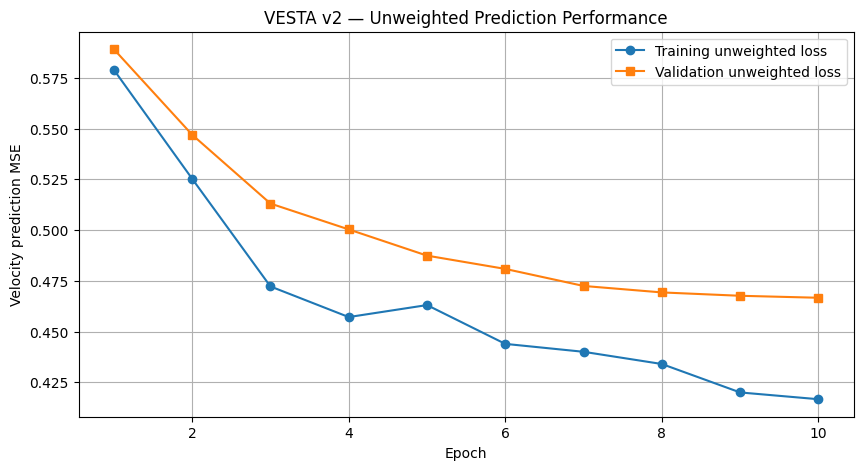

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

v2_df = pd.DataFrame(v2_history)

display(v2_df)

plt.figure(figsize=(10, 5))

plt.plot(
    v2_df["epoch"],
    v2_df["train_unweighted_loss"],
    marker="o",
    label="Training unweighted loss"
)

plt.plot(
    v2_df["epoch"],
    v2_df["val_unweighted_loss"],
    marker="s",
    label="Validation unweighted loss"
)

plt.xlabel("Epoch")
plt.ylabel("Velocity prediction MSE")
plt.title("VESTA v2 — Unweighted Prediction Performance")
plt.legend()
plt.grid(True)
plt.show()

# Phase 9 — VESTA v2 generation system

## Phase 9.1 — Implement the correct v-prediction DDPM sampler

We will convert predicted velocity into predicted noise and use it in the DDPM reverse process.
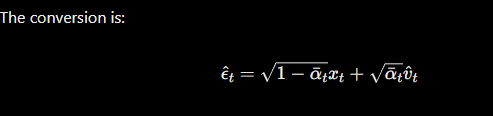

In [ ]:
@torch.no_grad()
def vesta_v2_generate(
    model,
    scheduler,
    person,
    garment,
    mask,
    pose,
    device
):
    model.eval()

    batch_size = person.shape[0]

    image = torch.randn(
        person.shape,
        device=device
    )

    betas = scheduler.betas
    alphas = scheduler.alphas
    alpha_bar = scheduler.alpha_cumprod

    for t in tqdm(
        reversed(range(scheduler.timesteps)),
        total=scheduler.timesteps,
        desc="VESTA v2 generation"
    ):

        timesteps = torch.full(
            (batch_size,),
            t,
            device=device,
            dtype=torch.long
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            predicted_velocity = model(
                noisy_target=image,
                timesteps=timesteps,
                person=person,
                garment=garment,
                mask=mask,
                pose=pose
            )

        a_bar = alpha_bar[t]
        beta = betas[t]
        alpha = alphas[t]

        # Convert velocity prediction to noise prediction
        predicted_noise = (
            torch.sqrt(1.0 - a_bar) * image
            + torch.sqrt(a_bar) * predicted_velocity.float()
        )

        if t > 0:
            previous_alpha_bar = alpha_bar[t - 1]
        else:
            previous_alpha_bar = torch.tensor(
                1.0,
                device=device
            )

        posterior_variance = (
            beta * (1.0 - previous_alpha_bar)
            / (1.0 - a_bar)
        )

        image = (
            image.float()
            - (
                beta / torch.sqrt(1.0 - a_bar)
            ) * predicted_noise
        ) / torch.sqrt(alpha)

        if t > 0:
            image = (
                image
                + torch.sqrt(posterior_variance)
                * torch.randn_like(image)
            )

    return image.clamp(-1, 1)


print("VESTA v2 DDPM sampler ready!")

VESTA v2 DDPM sampler ready!


## Phase 9.2 — Load the best V2 checkpoint
We'll select the checkpoint with the lowest recorded validation unweighted loss, rather than automatically assuming the last epoch is best.

In [ ]:
best_epoch = min(
    v2_history,
    key=lambda x: x["val_unweighted_loss"]
)["epoch"]

best_checkpoint_path = (
    V2_CHECKPOINT_DIR
    / f"vesta_v2_epoch_{best_epoch:02d}.pth"
)

best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=False
)

model_v2.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model_v2.eval()

print("Best V2 epoch:", best_epoch)
print(
    "Best validation unweighted loss:",
    best_checkpoint["validation_metrics"]["unweighted_loss"]
)

NameError: name 'v2_history' is not defined

## Phase 9.3 — Generate the first V2 image

We'll use one validation sample with its person, garment, mask, and pose inputs

In [ ]:
test_batch = next(iter(val_loader))

person = test_batch["agnostic"][:1].to(device)
garment = test_batch["garment"][:1].to(device)
mask = test_batch["cloth_mask"][:1].to(device)
pose = test_batch["pose"][:1].to(device)
target = test_batch["target"][:1].to(device)

generated_v2 = vesta_v2_generate(
    model=model_v2,
    scheduler=new_scheduler,
    person=person,
    garment=garment,
    mask=mask,
    pose=pose,
    device=device
)

print("Generated V2 image:", generated_v2.shape)
print("Generation completed!")

NameError: name 'val_loader' is not defined

## Phase 9.4 — Compare V1 and V2 visually

Generating VESTA image:   0%|          | 0/1000 [00:00<?, ?it/s]

NameError: name 'generated_v2' is not defined

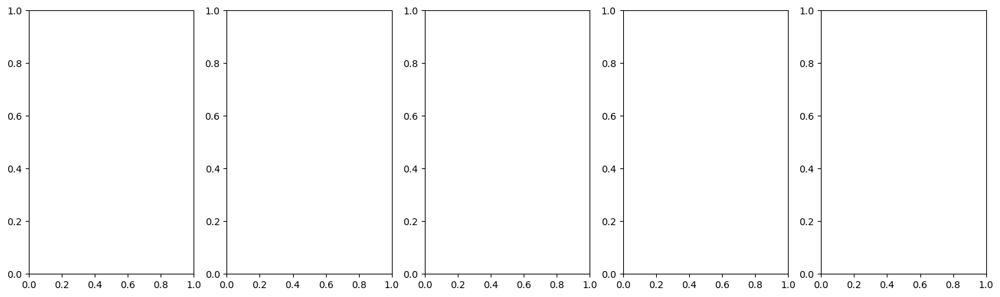

In [ ]:
import matplotlib.pyplot as plt

def display_vesta_image(tensor):
    return (
        tensor.detach()
        .cpu()
        .squeeze(0)
        .permute(1, 2, 0)
        .mul(0.5)
        .add(0.5)
        .clamp(0, 1)
        .numpy()
    )

# Generate V1 output for the same conditioning inputs
generated_v1 = vesta_generate(
    model=model_v1,
    scheduler=scheduler,
    person=person,
    garment=garment,
    mask=mask,
    pose=pose,
    device=device
)

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

images = [
    person,
    garment,
    target,
    generated_v1,
    generated_v2
]

titles = [
    "Person Input",
    "Garment Input",
    "Ground Truth",
    "VESTA V1",
    "VESTA V2"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(display_vesta_image(img))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Phase 10: Diagnose V2 generation

## Phase 10.1 — V2 Reverse Diffusion Stability Test

In [14]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

model_v2.eval()

# Reproducible random generator
generator = torch.Generator(device=device)
generator.manual_seed(20261123)

# Start from Gaussian noise
image = torch.randn(
    person.shape,
    generator=generator,
    device=device
)

alpha_bar = new_scheduler.alpha_cumprod
alphas = new_scheduler.alphas
betas = new_scheduler.betas

# Timesteps we want to inspect
inspect_steps = {999, 750, 500, 250, 100, 50, 0}

stability_records = []

print("Starting VESTA v2 stability test...")

with torch.no_grad():

    for t in tqdm(
        reversed(range(new_scheduler.timesteps)),
        total=new_scheduler.timesteps,
        desc="Stability test"
    ):

        timesteps = torch.full(
            (person.shape[0],),
            t,
            device=device,
            dtype=torch.long
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            predicted_velocity = model_v2(
                noisy_target=image,
                timesteps=timesteps,
                person=person,
                garment=garment,
                mask=mask,
                pose=pose
            )

        predicted_velocity = predicted_velocity.float()

        a_bar = alpha_bar[t].float()
        alpha = alphas[t].float()
        beta = betas[t].float()

        # Convert velocity prediction to noise
        predicted_noise = (
            torch.sqrt(1.0 - a_bar) * image.float()
            + torch.sqrt(a_bar) * predicted_velocity
        )

        # Stable clean-image estimate from velocity
        predicted_x0 = (
            torch.sqrt(a_bar) * image.float()
            - torch.sqrt(1.0 - a_bar) * predicted_velocity
        )

        # Record selected timesteps
        if t in inspect_steps:

            stability_records.append({
                "timestep": t,
                "alpha_bar": a_bar.item(),
                "image_rms": image.float().square().mean().sqrt().item(),
                "velocity_rms": predicted_velocity.square().mean().sqrt().item(),
                "noise_rms": predicted_noise.square().mean().sqrt().item(),
                "predicted_x0_rms": predicted_x0.square().mean().sqrt().item(),
                "predicted_x0_abs_max": predicted_x0.abs().max().item(),
                "predicted_x0_mean": predicted_x0.mean().item(),
                "predicted_x0_std": predicted_x0.std().item(),
                "finite": bool(
                    torch.isfinite(predicted_x0).all()
                )
            })

        # DDPM posterior update
        if t > 0:
            previous_alpha_bar = alpha_bar[t - 1].float()
        else:
            previous_alpha_bar = torch.tensor(
                1.0,
                device=device
            )

        posterior_variance = (
            beta * (1.0 - previous_alpha_bar)
            / (1.0 - a_bar)
        )

        image = (
            image.float()
            - beta / torch.sqrt(1.0 - a_bar) * predicted_noise
        ) / torch.sqrt(alpha)

        if t > 0:
            reverse_noise = torch.randn(
                image.shape,
                generator=generator,
                device=device
            )

            image = (
                image
                + torch.sqrt(posterior_variance) * reverse_noise
            )

        # Stop if numerical values become invalid
        if not torch.isfinite(image).all():
            raise RuntimeError(
                f"Numerical instability detected at timestep {t}"
            )

# Keep the unclamped final image statistics
final_rms = image.square().mean().sqrt().item()
final_abs_max = image.abs().max().item()

stability_df = pd.DataFrame(stability_records)

print("\nSTABILITY TEST COMPLETED")
display(stability_df)

print("\nFinal raw image RMS:", final_rms)
print("Final raw image maximum absolute value:", final_abs_max)

# Save diagnostic results
diagnostic_path = V2_DIR / "phase10_stability_diagnostic.csv"

stability_df.to_csv(
    diagnostic_path,
    index=False
)

print("\nDiagnostic saved:", diagnostic_path)

Starting VESTA v2 stability test...


Stability test:   0%|          | 0/1000 [00:00<?, ?it/s]


STABILITY TEST COMPLETED


,timestep,alpha_bar,image_rms,velocity_rms,noise_rms,predicted_x0_rms,predicted_x0_abs_max,predicted_x0_mean,predicted_x0_std,finite
0,999,2.428734e-09,0.999536,0.528566,0.999542,0.528554,1.773418,0.359490,0.387475,True
1,750,1.431786e-01,1.005610,0.638882,0.939379,0.732795,2.257201,0.494473,0.540821,True
2,500,4.922850e-01,1.035158,0.571912,0.792865,0.877498,3.417542,0.493796,0.725376,True
3,250,8.458881e-01,1.057686,0.469378,0.573012,1.005323,4.637591,0.493125,0.876075,True
4,100,9.715755e-01,1.062169,0.363414,0.396315,1.050337,5.146233,0.497637,0.924971,True
5,50,9.917246e-01,1.061822,0.319606,0.328614,1.059069,5.266538,0.501152,0.932994,True
6,0,9.999587e-01,1.069859,0.309444,0.307665,1.070372,5.173970,0.514649,0.938530,True



Final raw image RMS: 1.0703721046447754
Final raw image maximum absolute value: 5.173969268798828

Diagnostic saved: /content/drive/MyDrive/VESTA_AI/models/v2/phase10_stability_diagnostic.csv


## Phase 10.2 — Analyze Reverse Diffusion Statistics

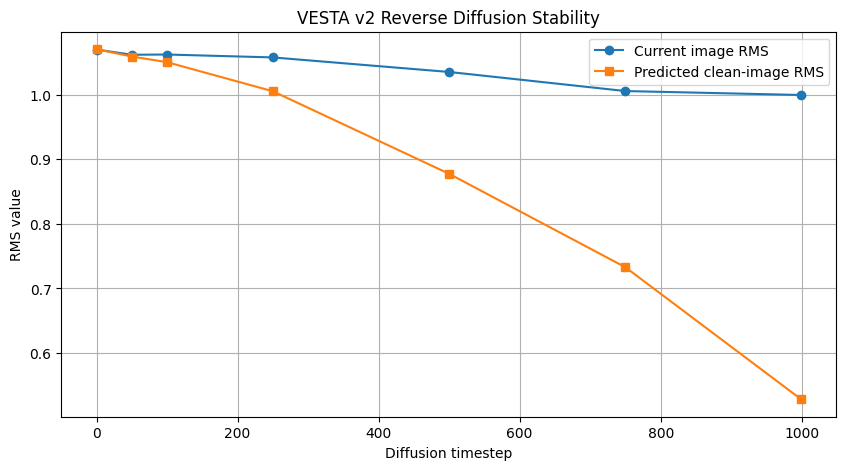

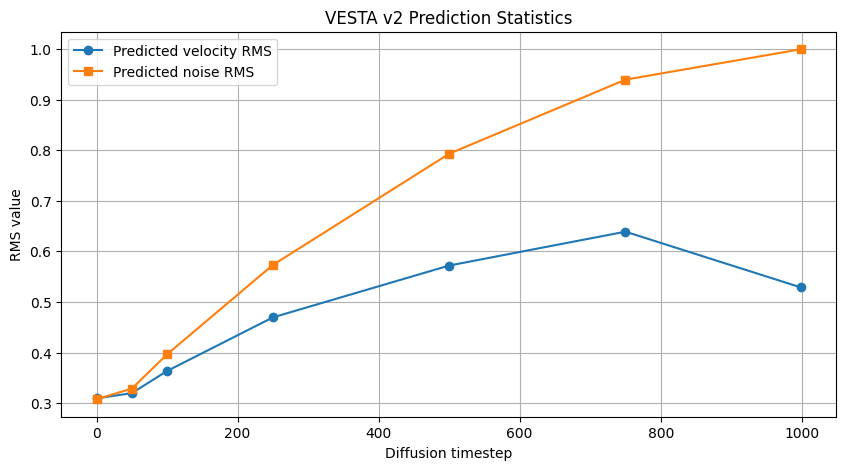

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    stability_df["timestep"],
    stability_df["image_rms"],
    marker="o",
    label="Current image RMS"
)

plt.plot(
    stability_df["timestep"],
    stability_df["predicted_x0_rms"],
    marker="s",
    label="Predicted clean-image RMS"
)

plt.xlabel("Diffusion timestep")
plt.ylabel("RMS value")
plt.title("VESTA v2 Reverse Diffusion Stability")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    stability_df["timestep"],
    stability_df["velocity_rms"],
    marker="o",
    label="Predicted velocity RMS"
)

plt.plot(
    stability_df["timestep"],
    stability_df["noise_rms"],
    marker="s",
    label="Predicted noise RMS"
)

plt.xlabel("Diffusion timestep")
plt.ylabel("RMS value")
plt.title("VESTA v2 Prediction Statistics")
plt.legend()
plt.grid(True)
plt.show()

## Phase 10.3 — Garment Conditioning Sensitivity Test

In [16]:
model_v2.eval()

# Two different garment samples
batch_a = val_dataset[0]
batch_b = val_dataset[1]

person_a = batch_a["agnostic"].unsqueeze(0).to(device)
garment_a = batch_a["garment"].unsqueeze(0).to(device)
garment_b = batch_b["garment"].unsqueeze(0).to(device)

mask_a = batch_a["cloth_mask"].unsqueeze(0).to(device)
pose_a = batch_a["pose"].unsqueeze(0).to(device)
target_a = batch_a["target"].unsqueeze(0).to(device)

# Same noise and timestep for both predictions
generator = torch.Generator(device=device)
generator.manual_seed(2026)

noise = torch.randn(
    target_a.shape,
    generator=generator,
    device=device
)

timestep = 500

timesteps = torch.tensor(
    [timestep],
    device=device,
    dtype=torch.long
)

noisy_target, _ = add_noise(
    target_a,
    timesteps,
    new_scheduler,
    noise=noise
)

with torch.no_grad():

    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):

        prediction_a = model_v2(
            noisy_target=noisy_target,
            timesteps=timesteps,
            person=person_a,
            garment=garment_a,
            mask=mask_a,
            pose=pose_a
        )

        prediction_b = model_v2(
            noisy_target=noisy_target,
            timesteps=timesteps,
            person=person_a,
            garment=garment_b,
            mask=mask_a,
            pose=pose_a
        )

prediction_a = prediction_a.float()
prediction_b = prediction_b.float()

difference = (prediction_a - prediction_b).abs()

print("Garment conditioning sensitivity")
print("--------------------------------")
print("Prediction A RMS:",
      prediction_a.square().mean().sqrt().item())

print("Prediction B RMS:",
      prediction_b.square().mean().sqrt().item())

print("Mean absolute difference:",
      difference.mean().item())

print("Maximum absolute difference:",
      difference.max().item())

print("Relative prediction difference (%):",
      (
          difference.mean()
          / (prediction_a.abs().mean() + 1e-8)
          * 100
      ).item())

Garment conditioning sensitivity
--------------------------------
Prediction A RMS: 0.5883780121803284
Prediction B RMS: 0.5846417546272278
Mean absolute difference: 0.02247486263513565
Maximum absolute difference: 0.1983642578125
Relative prediction difference (%): 4.596144199371338


## Phase 10.4 — Visualize Garment Conditioning

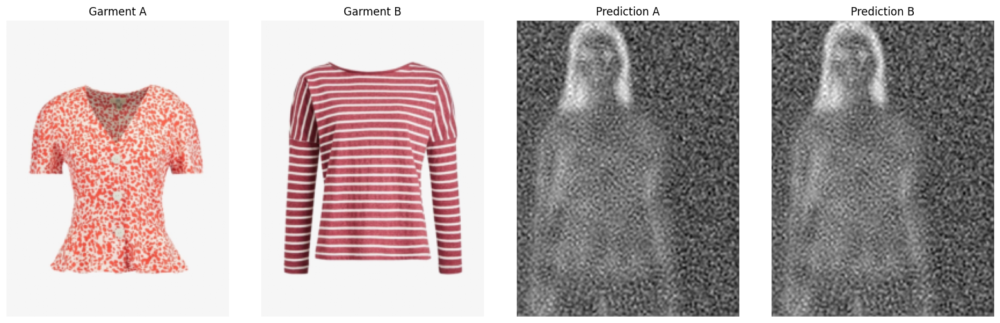

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    garment_a,
    garment_b,
    prediction_a,
    prediction_b
]

titles = [
    "Garment A",
    "Garment B",
    "Prediction A",
    "Prediction B"
]

for ax, img, title in zip(axes, images, titles):

    if "Prediction" in title:
        display_img = (
            img.detach().cpu().squeeze(0)
            .permute(1, 2, 0).numpy()
        )
        ax.imshow(display_img.mean(axis=2), cmap="gray")
    else:
        ax.imshow(display_vesta_image(img))

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Phase 10.5 — Multi-Sample Garment Conditioning Evaluation

Test whether VESTA v2 meaningfully responds to different garment inputs across multiple validation samples and diffusion timesteps.

In [18]:
model_v2.eval()

sample_count = min(16, len(val_dataset))
test_timesteps = [100, 500, 900]

conditioning_results = []

with torch.no_grad():

    for i in tqdm(range(sample_count), desc="Testing garment influence"):

        j = (i + 1) % len(val_dataset)

        sample_a = val_dataset[i]
        sample_b = val_dataset[j]

        person = sample_a["agnostic"].unsqueeze(0).to(device)
        garment_a = sample_a["garment"].unsqueeze(0).to(device)
        garment_b = sample_b["garment"].unsqueeze(0).to(device)

        mask = sample_a["cloth_mask"].unsqueeze(0).to(device)
        pose = sample_a["pose"].unsqueeze(0).to(device)
        target = sample_a["target"].unsqueeze(0).to(device)

        generator = torch.Generator(device=device)
        generator.manual_seed(10000 + i)

        noise = torch.randn(
            target.shape,
            generator=generator,
            device=device
        )

        for t in test_timesteps:

            timesteps = torch.tensor(
                [t],
                device=device,
                dtype=torch.long
            )

            noisy_target, _ = add_noise(
                target,
                timesteps,
                new_scheduler,
                noise=noise
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                pred_correct = model_v2(
                    noisy_target=noisy_target,
                    timesteps=timesteps,
                    person=person,
                    garment=garment_a,
                    mask=mask,
                    pose=pose
                )

                pred_swapped = model_v2(
                    noisy_target=noisy_target,
                    timesteps=timesteps,
                    person=person,
                    garment=garment_b,
                    mask=mask,
                    pose=pose
                )

            pred_correct = pred_correct.float()
            pred_swapped = pred_swapped.float()

            difference = (
                pred_correct - pred_swapped
            ).abs().mean().item()

            reference_magnitude = (
                pred_correct.abs().mean().item()
            )

            relative_difference = (
                difference / (reference_magnitude + 1e-8)
            ) * 100

            garment_difference = (
                garment_a - garment_b
            ).abs().mean().item()

            conditioning_results.append({
                "sample": i,
                "timestep": t,
                "garment_difference": garment_difference,
                "prediction_difference": difference,
                "relative_difference_percent": relative_difference
            })

conditioning_df = pd.DataFrame(conditioning_results)

display(
    conditioning_df.groupby("timestep").agg({
        "garment_difference": "mean",
        "prediction_difference": "mean",
        "relative_difference_percent": "mean"
    }).reset_index()
)

print("\nOverall mean conditioning sensitivity:",
      conditioning_df["relative_difference_percent"].mean())

print("Multi-sample test completed!")

Testing garment influence:   0%|          | 0/16 [00:00<?, ?it/s]

,timestep,garment_difference,prediction_difference,relative_difference_percent
0,100,0.472685,0.051852,17.923202
1,500,0.472685,0.027862,5.546902
2,900,0.472685,0.043603,7.812640



Overall mean conditioning sensitivity: 10.427581338735019
Multi-sample test completed!


## Phase 10.6 — Plot conditioning sensitivity

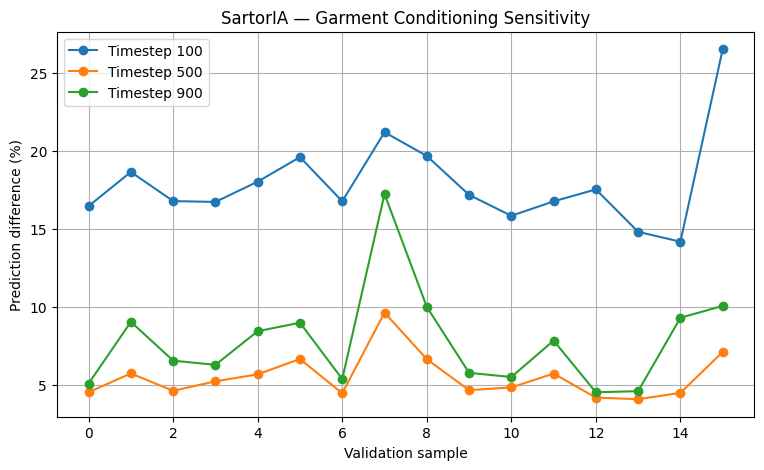

In [19]:
plt.figure(figsize=(9, 5))

for timestep in test_timesteps:

    subset = conditioning_df[
        conditioning_df["timestep"] == timestep
    ]

    plt.plot(
        subset["sample"],
        subset["relative_difference_percent"],
        marker="o",
        label=f"Timestep {timestep}"
    )

plt.xlabel("Validation sample")
plt.ylabel("Prediction difference (%)")
plt.title("SartorIA — Garment Conditioning Sensitivity")
plt.legend()
plt.grid(True)
plt.show()

## Phase 10.7 — Correct vs Incorrect Garment Evaluation

Compare velocity-prediction errors using the correct garment and a mismatched garment while keeping the person, pose, mask, noisy target, timestep, and noise identical.

In [20]:
model_v2.eval()

sample_count = min(32, len(val_dataset))
test_timesteps = [100, 500, 900]

paired_results = []

with torch.no_grad():

    for i in tqdm(range(sample_count), desc="Testing garment correspondence"):

        j = (i + 1) % len(val_dataset)

        sample_a = val_dataset[i]
        sample_b = val_dataset[j]

        target = sample_a["target"].unsqueeze(0).to(device)
        person = sample_a["agnostic"].unsqueeze(0).to(device)
        correct_garment = sample_a["garment"].unsqueeze(0).to(device)
        wrong_garment = sample_b["garment"].unsqueeze(0).to(device)

        mask = sample_a["cloth_mask"].unsqueeze(0).to(device)
        pose = sample_a["pose"].unsqueeze(0).to(device)

        generator = torch.Generator(device=device)
        generator.manual_seed(30000 + i)

        noise = torch.randn(
            target.shape,
            generator=generator,
            device=device
        )

        for t in test_timesteps:

            timesteps = torch.tensor(
                [t], device=device, dtype=torch.long
            )

            noisy_target, _ = add_noise(
                target,
                timesteps,
                new_scheduler,
                noise=noise
            )

            alpha_bar = extract_values(
                new_scheduler.alpha_cumprod,
                timesteps,
                target.shape
            )

            velocity_target = (
                torch.sqrt(alpha_bar) * noise
                - torch.sqrt(1.0 - alpha_bar) * target
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                correct_prediction = model_v2(
                    noisy_target=noisy_target,
                    timesteps=timesteps,
                    person=person,
                    garment=correct_garment,
                    mask=mask,
                    pose=pose
                )

                wrong_prediction = model_v2(
                    noisy_target=noisy_target,
                    timesteps=timesteps,
                    person=person,
                    garment=wrong_garment,
                    mask=mask,
                    pose=pose
                )

            correct_mse = F.mse_loss(
                correct_prediction.float(),
                velocity_target.float()
            ).item()

            wrong_mse = F.mse_loss(
                wrong_prediction.float(),
                velocity_target.float()
            ).item()

            improvement = (
                (wrong_mse - correct_mse)
                / (wrong_mse + 1e-8)
            ) * 100

            paired_results.append({
                "sample": i,
                "timestep": t,
                "correct_garment_mse": correct_mse,
                "wrong_garment_mse": wrong_mse,
                "correct_garment_advantage_percent": improvement
            })

paired_df = pd.DataFrame(paired_results)

paired_summary = (
    paired_df.groupby("timestep")
    .agg({
        "correct_garment_mse": "mean",
        "wrong_garment_mse": "mean",
        "correct_garment_advantage_percent": "mean"
    })
    .reset_index()
)

display(paired_summary)

print(
    "Overall correct-garment advantage:",
    paired_df["correct_garment_advantage_percent"].mean(),
    "%"
)

Testing garment correspondence:   0%|          | 0/32 [00:00<?, ?it/s]

,timestep,correct_garment_mse,wrong_garment_mse,correct_garment_advantage_percent
0,100,0.797684,0.799935,0.284729
1,500,0.382076,0.382782,0.184585
2,900,0.098715,0.104513,5.644560


Overall correct-garment advantage: 2.037957882225548 %


## Phase 10.8 — Visualize the comparison

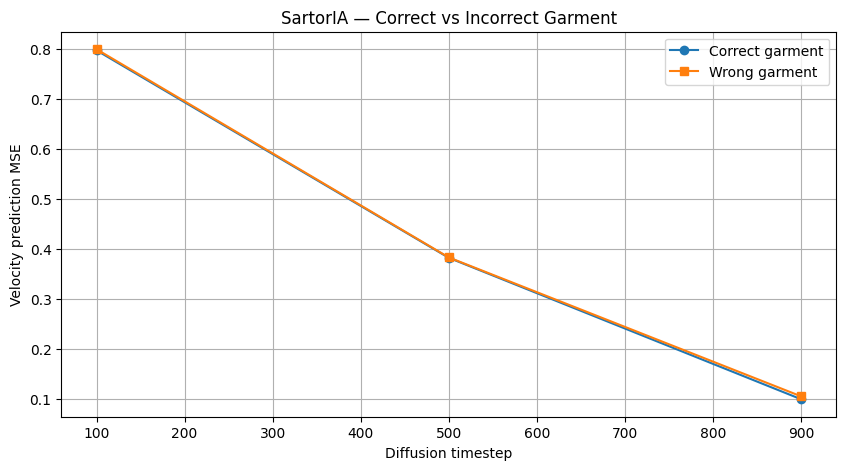

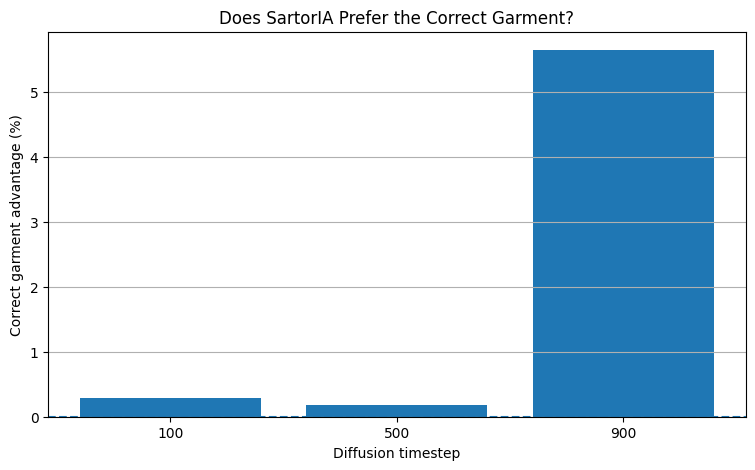

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    paired_summary["timestep"],
    paired_summary["correct_garment_mse"],
    marker="o",
    label="Correct garment"
)

plt.plot(
    paired_summary["timestep"],
    paired_summary["wrong_garment_mse"],
    marker="s",
    label="Wrong garment"
)

plt.xlabel("Diffusion timestep")
plt.ylabel("Velocity prediction MSE")
plt.title("SartorIA — Correct vs Incorrect Garment")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))

plt.bar(
    paired_summary["timestep"].astype(str),
    paired_summary["correct_garment_advantage_percent"]
)

plt.axhline(0, linestyle="--")
plt.xlabel("Diffusion timestep")
plt.ylabel("Correct garment advantage (%)")
plt.title("Does SartorIA Prefer the Correct Garment?")
plt.grid(axis="y")
plt.show()

## Phase 10.9 — Randomized Garment Mismatch Evaluation

Evaluate correct and randomly mismatched garments across the entire validation dataset. Use multiple mismatches per person to reduce dependence on the choice of one incorrect garment.

In [22]:
model_v2.eval()

sample_count = len(val_dataset)
mismatches_per_sample = 3
test_timesteps = [100, 500, 900]

random_generator = random.Random(2026)

robust_results = []

with torch.no_grad():

    for i in tqdm(
        range(sample_count),
        desc="Robust garment evaluation"
    ):

        sample_a = val_dataset[i]

        target = sample_a["target"].unsqueeze(0).to(device)
        person = sample_a["agnostic"].unsqueeze(0).to(device)
        correct_garment = sample_a["garment"].unsqueeze(0).to(device)
        mask = sample_a["cloth_mask"].unsqueeze(0).to(device)
        pose = sample_a["pose"].unsqueeze(0).to(device)

        possible_indices = [
            k for k in range(sample_count) if k != i
        ]

        wrong_indices = random_generator.sample(
            possible_indices,
            min(mismatches_per_sample, len(possible_indices))
        )

        generator = torch.Generator(device=device)
        generator.manual_seed(50000 + i)

        noise = torch.randn(
            target.shape,
            generator=generator,
            device=device
        )

        for t in test_timesteps:

            timesteps = torch.tensor(
                [t], device=device, dtype=torch.long
            )

            noisy_target, _ = add_noise(
                target,
                timesteps,
                new_scheduler,
                noise=noise
            )

            alpha_bar = extract_values(
                new_scheduler.alpha_cumprod,
                timesteps,
                target.shape
            )

            velocity_target = (
                torch.sqrt(alpha_bar) * noise
                - torch.sqrt(1.0 - alpha_bar) * target
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                correct_prediction = model_v2(
                    noisy_target=noisy_target,
                    timesteps=timesteps,
                    person=person,
                    garment=correct_garment,
                    mask=mask,
                    pose=pose
                )

            correct_mse = F.mse_loss(
                correct_prediction.float(),
                velocity_target.float()
            ).item()

            for wrong_index in wrong_indices:

                wrong_sample = val_dataset[wrong_index]

                wrong_garment = (
                    wrong_sample["garment"]
                    .unsqueeze(0)
                    .to(device)
                )

                garment_difference = (
                    correct_garment - wrong_garment
                ).abs().mean().item()

                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16,
                    enabled=(device.type == "cuda")
                ):

                    wrong_prediction = model_v2(
                        noisy_target=noisy_target,
                        timesteps=timesteps,
                        person=person,
                        garment=wrong_garment,
                        mask=mask,
                        pose=pose
                    )

                wrong_mse = F.mse_loss(
                    wrong_prediction.float(),
                    velocity_target.float()
                ).item()

                advantage = (
                    (wrong_mse - correct_mse)
                    / (wrong_mse + 1e-8)
                ) * 100

                robust_results.append({
                    "person_sample": i,
                    "wrong_garment_sample": wrong_index,
                    "timestep": t,
                    "garment_difference": garment_difference,
                    "correct_mse": correct_mse,
                    "wrong_mse": wrong_mse,
                    "correct_advantage_percent": advantage
                })

robust_df = pd.DataFrame(robust_results)

robust_summary = (
    robust_df.groupby("timestep")
    .agg({
        "garment_difference": "mean",
        "correct_mse": "mean",
        "wrong_mse": "mean",
        "correct_advantage_percent": "mean"
    })
    .reset_index()
)

display(robust_summary)

print(
    "Overall correct-garment advantage:",
    robust_df["correct_advantage_percent"].mean(),
    "%"
)

print("Total comparisons:", len(robust_df))

Robust garment evaluation:   0%|          | 0/50 [00:00<?, ?it/s]

,timestep,garment_difference,correct_mse,wrong_mse,correct_advantage_percent
0,100,0.469802,0.794413,0.796665,0.284705
1,500,0.469802,0.380082,0.380863,0.205849
2,900,0.469802,0.094604,0.101375,6.626396


Overall correct-garment advantage: 2.3723166932181337 %
Total comparisons: 450


## Phase 10.10 — Plot the results

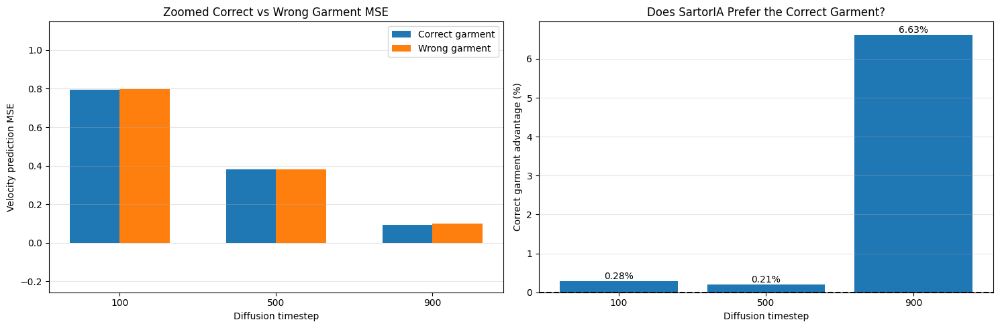

Overall advantage: 2.3723166932181337 %


In [24]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure sorted timestep data
plot_df = robust_summary.sort_values("timestep").copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# GRAPH 1: Zoomed MSE comparison
ax = axes[0]

x = np.arange(len(plot_df))
width = 0.32

ax.bar(
    x - width/2,
    plot_df["correct_mse"],
    width,
    label="Correct garment"
)

ax.bar(
    x + width/2,
    plot_df["wrong_mse"],
    width,
    label="Wrong garment"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["timestep"].astype(str))

# Zoom the Y-axis to reveal small differences
y_min = min(
    plot_df["correct_mse"].min(),
    plot_df["wrong_mse"].min()
)

y_max = max(
    plot_df["correct_mse"].max(),
    plot_df["wrong_mse"].max()
)

padding = max((y_max - y_min) * 0.5, 0.0005)

ax.set_ylim(y_min - padding, y_max + padding)

ax.set_xlabel("Diffusion timestep")
ax.set_ylabel("Velocity prediction MSE")
ax.set_title("Zoomed Correct vs Wrong Garment MSE")
ax.legend()
ax.grid(axis="y", alpha=0.3)

# GRAPH 2: Correct garment advantage
ax = axes[1]

values = plot_df["correct_advantage_percent"].values
labels = plot_df["timestep"].astype(str).values

bars = ax.bar(
    labels,
    values
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

ax.set_xlabel("Diffusion timestep")
ax.set_ylabel("Correct garment advantage (%)")
ax.set_title("Does SartorIA Prefer the Correct Garment?")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Overall advantage:",
      robust_df["correct_advantage_percent"].mean(), "%")

# Phase 11 — SartorIA v3 Architecture
The intended data flow:
1. Person encoder extracts person features.
2. Garment encoder extracts garment features.
3. Person features become Query (Q).
4. Garment features become Key (K) and Value (V).
5. Cross-attention allows person features to retrieve relevant garment information.
6. The resulting features are integrated into the U-Net at multiple resolutions.

The attention operation is:

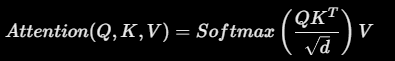


## Phase 11.1 — Inspect Existing Conditioning Architecture

In [25]:
model_v2.eval()

print("SartorIA v2 architecture:")
print(model_v2)

print("\nTrainable parameters:")

total_parameters = sum(
    p.numel() for p in model_v2.parameters()
)

print(f"{total_parameters:,}")

print("\nConditioning encoder modules:")

for name, module in model_v2.named_modules():

    if any(
        keyword in name.lower()
        for keyword in ["person", "garment", "fusion", "condition"]
    ):
        print(name, ":", module.__class__.__name__)

print("\nArchitecture inspection completed!")

SartorIA v2 architecture:
VESTAConditionalUNet(
  (time_embedding): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=128, out_features=512, bias=True)
    (2): SiLU()
    (3): Linear(in_features=512, out_features=128, bias=True)
  )
  (condition_encoders): VESTAConditioningEncoders(
    (person_encoder): ConditioningEncoder(
      (stem): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
        (2): SiLU()
      )
      (down1): Sequential(
        (0): Conv2d(32, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
        (2): SiLU()
      )
      (down2): Sequential(
        (0): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (2): SiLU()
      )
      (down3): Sequential(
        (0): Conv2d(64, 1

## Phase 11.2 — SartorIA Garment-Aware Cross-Attention Module

Create a memory-efficient cross-attention module that allows person features to retrieve relevant garment information.

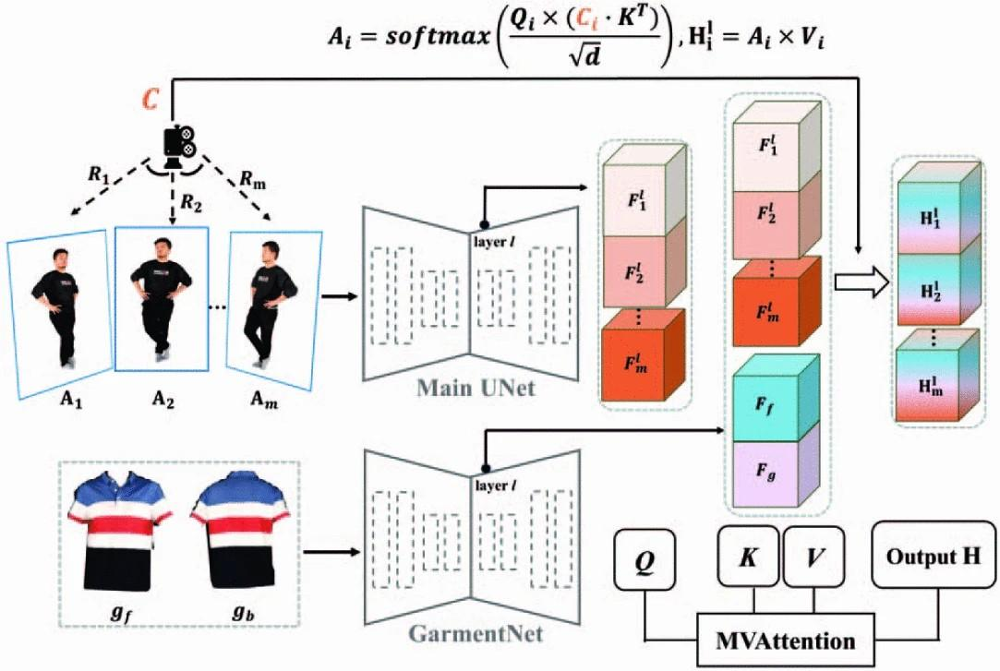

In [26]:
class SartorIAGarmentCrossAttention(nn.Module):

    def __init__(
        self,
        channels,
        num_heads=4,
        max_garment_tokens=(8, 6)
    ):
        super().__init__()

        assert channels % num_heads == 0

        self.channels = channels
        self.max_garment_tokens = max_garment_tokens

        self.norm_person = nn.GroupNorm(
            valid_groups(channels),
            channels
        )

        self.norm_garment = nn.GroupNorm(
            valid_groups(channels),
            channels
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

        self.output_projection = nn.Linear(
            channels,
            channels
        )

        # Start as an identity residual connection
        nn.init.zeros_(self.output_projection.weight)
        nn.init.zeros_(self.output_projection.bias)

        self.residual_scale = nn.Parameter(
            torch.tensor(0.1)
        )

    def forward(self, person_features, garment_features):

        batch_size, channels, height, width = (
            person_features.shape
        )

        # Normalize both feature maps
        person_features = self.norm_person(
            person_features
        )

        garment_features = self.norm_garment(
            garment_features
        )

        # Person features become queries
        queries = person_features.flatten(2).transpose(1, 2)

        # Compress garment features into a small token set
        pooled_garment = F.adaptive_avg_pool2d(
            garment_features,
            self.max_garment_tokens
        )

        # Garment features become keys and values
        garment_tokens = (
            pooled_garment.flatten(2).transpose(1, 2)
        )

        # Cross-attention
        attended_features, attention_weights = self.attention(
            query=queries,
            key=garment_tokens,
            value=garment_tokens,
            need_weights=False
        )

        attended_features = self.output_projection(
            attended_features
        )

        attended_features = (
            attended_features.transpose(1, 2)
            .reshape(
                batch_size,
                channels,
                height,
                width
            )
        )

        # Residual integration
        output = (
            person_features
            + self.residual_scale * attended_features
        )

        return output


print("SartorIA garment cross-attention module defined!")

SartorIA garment cross-attention module defined!


## Phase 11.3 — Test the attention module

Test all three feature resolutions using the actual V2 conditioning encoders. Verify output shapes, finite values, and gradient propagation.

In [27]:
model_v2.eval()

# Obtain actual conditioning features
with torch.no_grad():

    encoder_features = model_v2.condition_encoders(
        person,
        garment,
        mask,
        pose
    )

person_features, garment_features, _, _ = encoder_features

channels_per_scale = [32, 64, 128]

attention_modules = nn.ModuleList([
    SartorIAGarmentCrossAttention(channels)
    for channels in channels_per_scale
]).to(device)

attention_modules.eval()

attention_results = []

with torch.no_grad():

    for index, (person_feat, garment_feat) in enumerate(
        zip(person_features, garment_features)
    ):

        attended = attention_modules[index](
            person_feat,
            garment_feat
        )

        attention_results.append(attended)

        print(f"Scale {index + 1}")
        print("Input:", tuple(person_feat.shape))
        print("Garment:", tuple(garment_feat.shape))
        print("Output:", tuple(attended.shape))
        print("Finite:", torch.isfinite(attended).all().item())
        print("-" * 35)

# Gradient verification
attention_modules.train()

test_person = person_features[2].detach()
test_garment = garment_features[2].detach()

test_output = attention_modules[2](
    test_person,
    test_garment
)

test_loss = test_output.square().mean()
test_loss.backward()

gradient_count = sum(
    1 for p in attention_modules.parameters()
    if p.grad is not None
)

print("Attention gradient parameters:", gradient_count)
print("Cross-attention test completed!")

Scale 1
Input: (1, 32, 128, 96)
Garment: (1, 32, 128, 96)
Output: (1, 32, 128, 96)
Finite: True
-----------------------------------
Scale 2
Input: (1, 64, 64, 48)
Garment: (1, 64, 64, 48)
Output: (1, 64, 64, 48)
Finite: True
-----------------------------------
Scale 3
Input: (1, 128, 32, 24)
Garment: (1, 128, 32, 24)
Output: (1, 128, 32, 24)
Finite: True
-----------------------------------
Attention gradient parameters: 11
Cross-attention test completed!


## Phase 11.4 — Corrected Identity Residual Cross-Attention

Preserve the original person features through an identity residual connection. Normalize only the features used to calculate attention.

In [28]:
class SartorIAGarmentCrossAttention(nn.Module):

    def __init__(
        self,
        channels,
        num_heads=4,
        max_garment_tokens=(8, 6)
    ):
        super().__init__()

        assert channels % num_heads == 0

        self.channels = channels
        self.max_garment_tokens = max_garment_tokens

        self.norm_person = nn.GroupNorm(
            valid_groups(channels),
            channels
        )

        self.norm_garment = nn.GroupNorm(
            valid_groups(channels),
            channels
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

        self.output_projection = nn.Linear(
            channels,
            channels
        )

        # Zero-initialized attention output
        nn.init.zeros_(self.output_projection.weight)
        nn.init.zeros_(self.output_projection.bias)

        self.residual_scale = nn.Parameter(
            torch.tensor(0.1)
        )

    def forward(self, person_features, garment_features):

        # Preserve original person features
        residual = person_features

        batch_size, channels, height, width = (
            person_features.shape
        )

        # Normalize only attention inputs
        normalized_person = self.norm_person(
            person_features
        )

        normalized_garment = self.norm_garment(
            garment_features
        )

        queries = (
            normalized_person.flatten(2)
            .transpose(1, 2)
        )

        pooled_garment = F.adaptive_avg_pool2d(
            normalized_garment,
            self.max_garment_tokens
        )

        garment_tokens = (
            pooled_garment.flatten(2)
            .transpose(1, 2)
        )

        attended, _ = self.attention(
            query=queries,
            key=garment_tokens,
            value=garment_tokens,
            need_weights=False
        )

        attended = self.output_projection(attended)

        attended = (
            attended.transpose(1, 2)
            .reshape(batch_size, channels, height, width)
        )

        return residual + self.residual_scale * attended


print("Corrected cross-attention module defined!")

Corrected cross-attention module defined!


## Phase 11.5 — Verify identity residual and gradient flow

The zero-initialized attention projection should initially preserve the original person features exactly. We will also check that the attention projection receives gradients.

In [29]:
# Recreate modules with corrected class
attention_modules = nn.ModuleList([
    SartorIAGarmentCrossAttention(channels)
    for channels in [32, 64, 128]
]).to(device)

attention_modules.train()

# Test the eighth-resolution features
test_person = person_features[2].detach()
test_garment = garment_features[2].detach()

test_output = attention_modules[2](
    test_person,
    test_garment
)

identity_difference = (
    test_output - test_person
).abs().max().item()

print("Identity residual maximum difference:",
      identity_difference)

assert torch.allclose(
    test_output,
    test_person,
    atol=1e-6
), "Identity residual test failed!"

# Test gradients
test_loss = test_output.square().mean()
test_loss.backward()

projection_gradient = (
    attention_modules[2]
    .output_projection.weight.grad
)

assert projection_gradient is not None
assert torch.isfinite(projection_gradient).all()

print("Output projection gradient verified.")
print("Gradient norm:", projection_gradient.norm().item())
print("Corrected attention tests passed!")

Identity residual maximum difference: 0.0
Output projection gradient verified.
Gradient norm: 0.031009163707494736
Corrected attention tests passed!


## Phase 11.6 — SartorIA v3 Cross-Attention U-Net

Integrate garment-aware cross-attention into the U-Net at half, quarter, and eighth resolutions.
Preserve the existing V2 architecture and checkpoint.

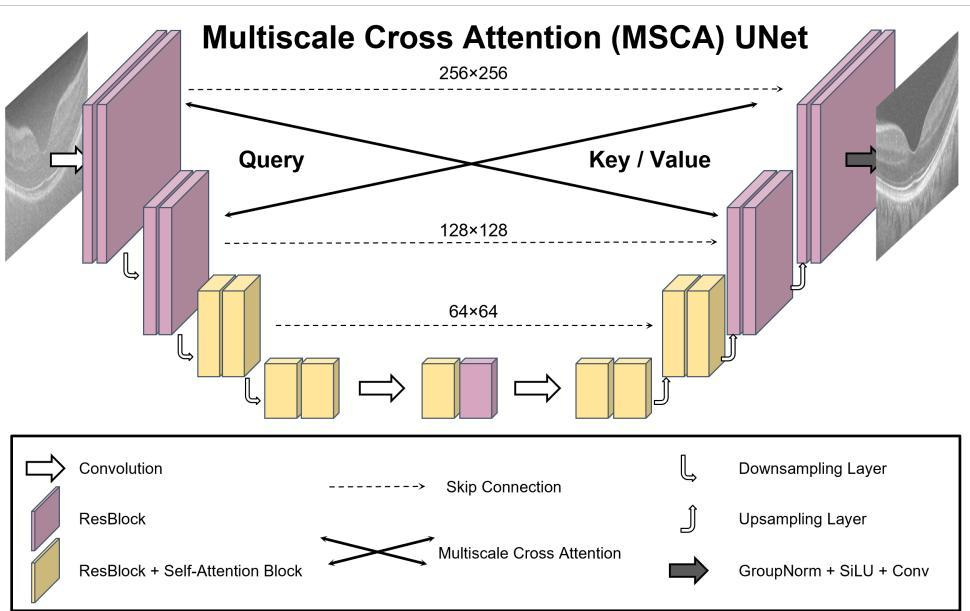

In [37]:
class SartorIAv3UNet(nn.Module):

    def __init__(self, base_channels=32, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim * 4),
            nn.SiLU(),
            nn.Linear(time_dim * 4, time_dim)
        )

        self.condition_encoders = VESTAConditioningEncoders(
            base_channels
        )

        self.feature_fusion = VESTAFeatureFusion(
            base_channels
        )

        # Garment-aware cross-attention at three scales
        self.cross_attention_half = SartorIAGarmentCrossAttention(
            base_channels
        )

        self.cross_attention_quarter = SartorIAGarmentCrossAttention(
            base_channels * 2
        )

        self.cross_attention_eighth = SartorIAGarmentCrossAttention(
            base_channels * 4
        )

        self.input_conv = nn.Conv2d(
            3, base_channels, 3, padding=1
        )

        self.down_block1 = ResidualBlock(
            base_channels, base_channels, time_dim
        )

        self.downsample1 = nn.Conv2d(
            base_channels,
            base_channels * 2,
            4, stride=2, padding=1
        )

        self.down_block2 = ResidualBlock(
            base_channels * 2,
            base_channels * 2,
            time_dim
        )

        self.downsample2 = nn.Conv2d(
            base_channels * 2,
            base_channels * 4,
            4, stride=2, padding=1
        )

        self.down_block3 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.mid_block1 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.mid_block2 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.up_block2 = ResidualBlock(
            base_channels * 6,
            base_channels * 2,
            time_dim
        )

        self.up_block1 = ResidualBlock(
            base_channels * 3,
            base_channels,
            time_dim
        )

        self.output_norm = nn.GroupNorm(
            valid_groups(base_channels),
            base_channels
        )

        self.output_conv = nn.Conv2d(
            base_channels, 3, 3, padding=1
        )

    def forward(
        self,
        noisy_target,
        timesteps,
        person,
        garment,
        mask,
        pose
    ):

        time_emb = self.time_embedding(timesteps)

        # Conditioning encoders
        encoder_features = self.condition_encoders(
            person, garment, mask, pose
        )

        person_features, garment_features, _, _ = (
            encoder_features
        )

        # Multi-scale feature fusion
        cond_half, cond_quarter, cond_eighth = (
            self.feature_fusion(encoder_features)
        )

        # Cross-attention: person queries garment
        attended_half = self.cross_attention_half(
            person_features[0],
            garment_features[0]
        )

        attended_quarter = self.cross_attention_quarter(
            person_features[1],
            garment_features[1]
        )

        attended_eighth = self.cross_attention_eighth(
            person_features[2],
            garment_features[2]
        )

        # Inject only the garment-attention updates.
        # The original person features are already included in feature fusion.

        cond_half = cond_half + (
            attended_half - person_features[0]
        )

        cond_quarter = cond_quarter + (
            attended_quarter - person_features[1]
        )

        cond_eighth = cond_eighth + (
            attended_eighth - person_features[2]
        )

        # U-Net encoder
        x0 = self.input_conv(noisy_target)

        x1 = F.avg_pool2d(x0, 2)
        x1 = x1 + cond_half
        x1 = self.down_block1(x1, time_emb)

        x2 = self.downsample1(x1)
        x2 = x2 + cond_quarter
        x2 = self.down_block2(x2, time_emb)

        x3 = self.downsample2(x2)
        x3 = x3 + cond_eighth
        x3 = self.down_block3(x3, time_emb)

        # Bottleneck
        x = self.mid_block1(x3, time_emb)
        x = self.mid_block2(x, time_emb)

        # Decoder
        x = F.interpolate(
            x,
            size=x2.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = self.up_block2(
            torch.cat([x, x2], dim=1),
            time_emb
        )

        x = F.interpolate(
            x,
            size=x1.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = self.up_block1(
            torch.cat([x, x1], dim=1),
            time_emb
        )

        x = F.interpolate(
            x,
            size=noisy_target.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        output = self.output_conv(
            F.silu(self.output_norm(x))
        )

        return output


print("SartorIA v3 U-Net architecture defined!")

SartorIA v3 U-Net architecture defined!


## Phase 11.7 — Initialize V3 and verify dimensions

Initialize V3 with fresh weights. Check parameter count, GPU memory, output shape, and numerical stability.

In [38]:
model_v3 = SartorIAv3UNet(
    base_channels=32,
    time_dim=128
).to(device)

total_v3_parameters = sum(
    p.numel() for p in model_v3.parameters()
)

trainable_v3_parameters = sum(
    p.numel()
    for p in model_v3.parameters()
    if p.requires_grad
)

print("SartorIA v3 initialized.")
print("Total parameters:", f"{total_v3_parameters:,}")
print("Trainable parameters:", f"{trainable_v3_parameters:,}")

if torch.cuda.is_available():
    print(
        "GPU allocated memory:",
        round(torch.cuda.memory_allocated() / 1024**3, 3),
        "GB"
    )

SartorIA v3 initialized.
Total parameters: 2,475,462
Trainable parameters: 2,475,462
GPU allocated memory: 0.103 GB


## Phase 11.8 — Run a forward-pass test

Test one real training batch through the complete V3 U-Net.

In [39]:
model_v3.eval()

test_batch = next(iter(train_loader))

test_person = test_batch["agnostic"].to(device)
test_garment = test_batch["garment"].to(device)
test_mask = test_batch["cloth_mask"].to(device)
test_pose = test_batch["pose"].to(device)
test_target = test_batch["target"].to(device)

test_timesteps = torch.tensor(
    [500],
    device=device,
    dtype=torch.long
)

test_noisy_target, _ = add_noise(
    test_target,
    test_timesteps,
    new_scheduler,
    noise=torch.randn_like(test_target)
)

with torch.no_grad():

    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):

        v3_output = model_v3(
            noisy_target=test_noisy_target,
            timesteps=test_timesteps,
            person=test_person,
            garment=test_garment,
            mask=test_mask,
            pose=test_pose
        )

print("Input shape:", tuple(test_noisy_target.shape))
print("Output shape:", tuple(v3_output.shape))
print("Output finite:", torch.isfinite(v3_output).all().item())

assert v3_output.shape == test_target.shape
assert torch.isfinite(v3_output).all()

print("SartorIA v3 forward-pass test passed!")

Input shape: (1, 3, 256, 192)
Output shape: (1, 3, 256, 192)
Output finite: True
SartorIA v3 forward-pass test passed!


## Phase 11.9 — V3 Velocity Loss and Gradient Verification

Verify that SartorIA v3 can calculate the velocity-prediction objective and propagate gradients through its U-Net and garment cross-attention modules.

In [40]:
def sartoria_v3_loss(
    model,
    batch,
    diffusion_scheduler,
    device,
    snr_gamma=5.0
):
    target = batch["target"].to(device)
    person = batch["agnostic"].to(device)
    garment = batch["garment"].to(device)
    mask = batch["cloth_mask"].to(device)
    pose = batch["pose"].to(device)

    batch_size = target.shape[0]

    timesteps = torch.randint(
        0,
        diffusion_scheduler.timesteps,
        (batch_size,),
        device=device
    )

    noise = torch.randn_like(target)

    noisy_target, _ = add_noise(
        target,
        timesteps,
        diffusion_scheduler,
        noise=noise
    )

    alpha_bar = extract_values(
        diffusion_scheduler.alpha_cumprod,
        timesteps,
        target.shape
    )

    velocity_target = (
        torch.sqrt(alpha_bar) * noise
        - torch.sqrt(1.0 - alpha_bar) * target
    )

    predicted_velocity = model(
        noisy_target=noisy_target,
        timesteps=timesteps,
        person=person,
        garment=garment,
        mask=mask,
        pose=pose
    )

    per_sample_mse = (
        (predicted_velocity.float() - velocity_target.float())
        .pow(2)
        .flatten(1)
        .mean(dim=1)
    )

    snr = (
        alpha_bar.flatten()
        / (1.0 - alpha_bar.flatten()).clamp(min=1e-8)
    )

    weights = (
        torch.minimum(
            snr,
            torch.full_like(snr, snr_gamma)
        )
        / (snr + 1.0)
    )

    weighted_loss = (weights * per_sample_mse).mean()
    unweighted_loss = per_sample_mse.mean()

    return weighted_loss, unweighted_loss


print("SartorIA v3 loss function defined!")

SartorIA v3 loss function defined!


In [41]:
model_v3.train()
model_v3.zero_grad(set_to_none=True)

test_batch = next(iter(train_loader))

with torch.autocast(
    device_type=device.type,
    dtype=torch.float16,
    enabled=(device.type == "cuda")
):

    weighted_loss_v3, unweighted_loss_v3 = sartoria_v3_loss(
        model=model_v3,
        batch=test_batch,
        diffusion_scheduler=new_scheduler,
        device=device,
        snr_gamma=5.0
    )

assert torch.isfinite(weighted_loss_v3)
assert torch.isfinite(unweighted_loss_v3)

weighted_loss_v3.backward()

gradient_parameters = sum(
    1 for p in model_v3.parameters()
    if p.grad is not None
)

for index, attention in enumerate([
    model_v3.cross_attention_half,
    model_v3.cross_attention_quarter,
    model_v3.cross_attention_eighth
]):

    grad = attention.output_projection.weight.grad

    print(
        f"Attention scale {index + 1} gradient:",
        None if grad is None else grad.norm().item()
    )

print("\nWeighted loss:", weighted_loss_v3.item())
print("Unweighted loss:", unweighted_loss_v3.item())
print("Parameters receiving gradients:", gradient_parameters)
print("Total trainable parameters:", trainable_v3_parameters)

assert gradient_parameters > 0

print("\nSartorIA v3 gradient verification passed!")

model_v3.zero_grad(set_to_none=True)

Attention scale 1 gradient: 0.00697164935991168
Attention scale 2 gradient: 0.007022822741419077
Attention scale 3 gradient: 0.010078459046781063

Weighted loss: 0.750561535358429
Unweighted loss: 0.9300949573516846
Parameters receiving gradients: 197
Total trainable parameters: 2475462

SartorIA v3 gradient verification passed!


# Phase 12 — SartorIA v3 Training



## Phase 12.1 — Initialize V3 Optimizer and Training Configuration

Configure a fresh AdamW optimizer, cosine learning-rate scheduler, and mixed-precision gradient scaler for SartorIA V3.

V2 model weights and checkpoints remain untouched.

In [42]:
import torch.optim as optim
from pathlib import Path
from tqdm.auto import tqdm
import json
import time

# V3 training configuration
V3_TRAIN_CONFIG = {
    "epochs": 10,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "gradient_accumulation_steps": 4,
    "max_grad_norm": 1.0,
    "snr_gamma": 5.0,
    "mixed_precision": device.type == "cuda"
}

# Separate V3 directory — never overwrite V2
V3_DIR = PROJECT_ROOT / "models" / "v3"
V3_CHECKPOINT_DIR = V3_DIR / "checkpoints"

V3_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Fresh optimizer
optimizer_v3 = optim.AdamW(
    model_v3.parameters(),
    lr=V3_TRAIN_CONFIG["learning_rate"],
    weight_decay=V3_TRAIN_CONFIG["weight_decay"]
)

# Cosine learning-rate scheduler
lr_scheduler_v3 = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_v3,
    T_max=V3_TRAIN_CONFIG["epochs"],
    eta_min=1e-6
)

# Mixed-precision scaler
scaler_v3 = torch.amp.GradScaler(
    "cuda",
    enabled=V3_TRAIN_CONFIG["mixed_precision"]
)

# Training history
v3_history = []

V3_HISTORY_PATH = (
    V3_DIR / "sartoria_v3_training_history.json"
)

print("SartorIA V3 training configuration initialized!")
print("Optimizer:", optimizer_v3.__class__.__name__)
print("Learning rate:", V3_TRAIN_CONFIG["learning_rate"])
print("Weight decay:", V3_TRAIN_CONFIG["weight_decay"])
print("Epochs:", V3_TRAIN_CONFIG["epochs"])
print("Gradient accumulation:",
      V3_TRAIN_CONFIG["gradient_accumulation_steps"])
print("Mixed precision:", V3_TRAIN_CONFIG["mixed_precision"])
print("Checkpoint directory:", V3_CHECKPOINT_DIR)
print("Trainable parameters:", sum(
    p.numel() for p in model_v3.parameters()
    if p.requires_grad
))

assert V3_CHECKPOINT_DIR.exists()
assert len(optimizer_v3.param_groups) > 0
assert all(
    p.requires_grad
    for group in optimizer_v3.param_groups
    for p in group["params"]
)

print("\nPhase 12.1 passed!")


SartorIA V3 training configuration initialized!
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Epochs: 10
Gradient accumulation: 4
Mixed precision: True
Checkpoint directory: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints
Trainable parameters: 2475462

Phase 12.1 passed!


## Phase 12.2 — V3 Training and Validation Functions

In [43]:
def train_v3_one_epoch(epoch):

    model_v3.train()
    optimizer_v3.zero_grad(set_to_none=True)

    total_weighted_loss = 0.0
    total_unweighted_loss = 0.0

    accumulation_steps = V3_TRAIN_CONFIG[
        "gradient_accumulation_steps"
    ]

    total_batches = len(train_loader)

    progress = tqdm(
        enumerate(train_loader),
        total=total_batches,
        desc=f"SartorIA V3 Epoch {epoch}"
    )

    for step, batch in progress:

        # Correctly handle the final incomplete accumulation group
        group_start = (
            step // accumulation_steps
        ) * accumulation_steps

        group_size = min(
            accumulation_steps,
            total_batches - group_start
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=V3_TRAIN_CONFIG["mixed_precision"]
        ):

            weighted_loss, unweighted_loss = sartoria_v3_loss(
                model=model_v3,
                batch=batch,
                diffusion_scheduler=new_scheduler,
                device=device,
                snr_gamma=V3_TRAIN_CONFIG["snr_gamma"]
            )

            loss_for_backward = weighted_loss / group_size

        scaler_v3.scale(loss_for_backward).backward()

        should_update = (
            (step + 1) % accumulation_steps == 0
            or (step + 1) == total_batches
        )

        if should_update:

            scaler_v3.unscale_(optimizer_v3)

            torch.nn.utils.clip_grad_norm_(
                model_v3.parameters(),
                V3_TRAIN_CONFIG["max_grad_norm"]
            )

            scaler_v3.step(optimizer_v3)
            scaler_v3.update()

            optimizer_v3.zero_grad(set_to_none=True)

        total_weighted_loss += weighted_loss.item()
        total_unweighted_loss += unweighted_loss.item()

        progress.set_postfix(
            weighted=f"{weighted_loss.item():.4f}",
            unweighted=f"{unweighted_loss.item():.4f}"
        )

    return {
        "weighted_loss": total_weighted_loss / total_batches,
        "unweighted_loss": total_unweighted_loss / total_batches
    }


# ==========================================
# PHASE 12.2 — V3 VALIDATION FUNCTION
# ==========================================

@torch.no_grad()
def validate_v3():

    model_v3.eval()

    generator = torch.Generator(device=device)
    generator.manual_seed(20261122)

    total_weighted = 0.0
    total_unweighted = 0.0
    total_samples = 0

    for batch in val_loader:

        target = batch["target"].to(device)
        batch_size = target.shape[0]

        # Fixed validation timesteps and noise
        timesteps = torch.randint(
            0,
            new_scheduler.timesteps,
            (batch_size,),
            device=device,
            generator=generator
        )

        noise = torch.randn(
            target.shape,
            device=device,
            generator=generator
        )

        noisy_target, _ = add_noise(
            target,
            timesteps,
            new_scheduler,
            noise=noise
        )

        alpha_bar = extract_values(
            new_scheduler.alpha_cumprod,
            timesteps,
            target.shape
        )

        velocity_target = (
            torch.sqrt(alpha_bar) * noise
            - torch.sqrt(1.0 - alpha_bar) * target
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=V3_TRAIN_CONFIG["mixed_precision"]
        ):

            predicted_velocity = model_v3(
                noisy_target=noisy_target,
                timesteps=timesteps,
                person=batch["agnostic"].to(device),
                garment=batch["garment"].to(device),
                mask=batch["cloth_mask"].to(device),
                pose=batch["pose"].to(device)
            )

        per_sample_mse = (
            (predicted_velocity.float() - velocity_target.float())
            .pow(2)
            .flatten(1)
            .mean(dim=1)
        )

        snr = (
            alpha_bar.flatten()
            / (1.0 - alpha_bar.flatten()).clamp(min=1e-8)
        )

        weights = (
            torch.minimum(
                snr,
                torch.full_like(
                    snr,
                    V3_TRAIN_CONFIG["snr_gamma"]
                )
            )
            / (snr + 1.0)
        )

        total_weighted += (
            per_sample_mse * weights
        ).sum().item()

        total_unweighted += per_sample_mse.sum().item()
        total_samples += batch_size

    return {
        "weighted_loss": total_weighted / total_samples,
        "unweighted_loss": total_unweighted / total_samples
    }


print("SartorIA V3 training function defined!")
print("SartorIA V3 validation function defined!")

# Verify required functions
assert callable(train_v3_one_epoch)
assert callable(validate_v3)

print("\nPhase 12.2 passed!")


SartorIA V3 training function defined!
SartorIA V3 validation function defined!

Phase 12.2 passed!


## Phase 12.3 — V3 Checkpoint Saving and Resume Support

Save model weights, optimizer state, learning-rate scheduler, mixed-precision scaler, and training history to Google Drive.

Support resuming V3 training from the latest checkpoint.

In [44]:
import random
import numpy as np

V3_LATEST_CHECKPOINT = V3_CHECKPOINT_DIR / "sartoria_v3_latest.pth"
V3_BEST_CHECKPOINT = V3_CHECKPOINT_DIR / "sartoria_v3_best.pth"

best_v3_val_loss = float("inf")


def save_v3_checkpoint(epoch, train_metrics, val_metrics):

    global best_v3_val_loss

    current_val_loss = val_metrics["weighted_loss"]

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model_v3.state_dict(),
        "optimizer_state_dict": optimizer_v3.state_dict(),
        "scheduler_state_dict": lr_scheduler_v3.state_dict(),
        "scaler_state_dict": scaler_v3.state_dict(),

        "train_metrics": train_metrics,
        "val_metrics": val_metrics,
        "history": v3_history,

        "best_val_loss": min(
            best_v3_val_loss,
            current_val_loss
        ),

        "config": V3_TRAIN_CONFIG,

        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),

        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        )
    }

    # Save latest checkpoint
    temp_path = V3_CHECKPOINT_DIR / "v3_latest_temp.pth"

    torch.save(checkpoint, temp_path)
    temp_path.replace(V3_LATEST_CHECKPOINT)

    # Save individual epoch checkpoint
    epoch_path = V3_CHECKPOINT_DIR / (
        f"sartoria_v3_epoch_{epoch:02d}.pth"
    )

    torch.save(checkpoint, epoch_path)

    # Save best checkpoint when validation improves
    if current_val_loss < best_v3_val_loss:

        best_v3_val_loss = current_val_loss

        torch.save(
            checkpoint,
            V3_BEST_CHECKPOINT
        )

        print("New best V3 checkpoint saved!")

    # Save readable training history
    with open(V3_HISTORY_PATH, "w") as f:
        json.dump(v3_history, f, indent=4)

    print(f"Epoch {epoch} checkpoint saved.")
    print("Latest:", V3_LATEST_CHECKPOINT)
    print("Best validation loss:", best_v3_val_loss)


def resume_v3_training(checkpoint_path=None):

    global best_v3_val_loss, v3_history

    if checkpoint_path is None:
        checkpoint_path = V3_LATEST_CHECKPOINT

    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.exists():
        print("No V3 checkpoint found.")
        print("Starting training from Epoch 1.")
        return 1

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model_v3.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer_v3.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    lr_scheduler_v3.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    scaler_v3.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    v3_history = checkpoint.get("history", [])

    best_v3_val_loss = checkpoint.get(
        "best_val_loss",
        float("inf")
    )

    # Restore random states when available
    if "python_rng_state" in checkpoint:
        random.setstate(checkpoint["python_rng_state"])

    if "numpy_rng_state" in checkpoint:
        np.random.set_state(checkpoint["numpy_rng_state"])

    if "torch_rng_state" in checkpoint:
        torch.set_rng_state(checkpoint["torch_rng_state"])

    if (
        torch.cuda.is_available()
        and checkpoint.get("cuda_rng_state") is not None
    ):
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state"]
        )

    completed_epoch = checkpoint["epoch"]

    print("V3 checkpoint restored successfully!")
    print("Completed epochs:", completed_epoch)
    print("Best validation loss:", best_v3_val_loss)

    return completed_epoch + 1


print("V3 checkpoint functions defined!")
print("Latest checkpoint path:", V3_LATEST_CHECKPOINT)
print("Best checkpoint path:", V3_BEST_CHECKPOINT)
print("History path:", V3_HISTORY_PATH)

assert callable(save_v3_checkpoint)
assert callable(resume_v3_training)
assert V3_CHECKPOINT_DIR.exists()

print("\nPhase 12.3 passed!")


V3 checkpoint functions defined!
Latest checkpoint path: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_latest.pth
Best checkpoint path: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_best.pth
History path: /content/drive/MyDrive/VESTA_AI/models/v3/sartoria_v3_training_history.json

Phase 12.3 passed!


## Phase 12.4 — Pre-training Safety Test
Before launching all 10 epochs, let's verify that the validation function and training loss work with the current V3 model and data. This avoids discovering a compatibility error halfway through training.

In [45]:
print("Running V3 pre-training checks...\n")

# 1. Check model and optimizer
assert model_v3.training or not model_v3.training
assert len(optimizer_v3.param_groups) > 0

# 2. Check training and validation loaders
assert len(train_loader) > 0
assert len(val_loader) > 0

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# 3. Test validation without updating weights
validation_test = validate_v3()

print("\nValidation test:")
print("Weighted loss:", validation_test["weighted_loss"])
print("Unweighted loss:", validation_test["unweighted_loss"])

assert np.isfinite(validation_test["weighted_loss"])
assert np.isfinite(validation_test["unweighted_loss"])

# 4. Test one training batch without optimizer update
model_v3.train()
optimizer_v3.zero_grad(set_to_none=True)

test_batch = next(iter(train_loader))

with torch.autocast(
    device_type=device.type,
    dtype=torch.float16,
    enabled=V3_TRAIN_CONFIG["mixed_precision"]
):
    test_weighted_loss, test_unweighted_loss = sartoria_v3_loss(
        model=model_v3,
        batch=test_batch,
        diffusion_scheduler=new_scheduler,
        device=device,
        snr_gamma=V3_TRAIN_CONFIG["snr_gamma"]
    )

assert torch.isfinite(test_weighted_loss)
assert torch.isfinite(test_unweighted_loss)

print("\nTraining loss test:")
print("Weighted loss:", test_weighted_loss.item())
print("Unweighted loss:", test_unweighted_loss.item())

# Clear gradients; no optimizer step was performed
optimizer_v3.zero_grad(set_to_none=True)

print("\nV3 pre-training safety test passed!")
print("No training weights were updated.")


Running V3 pre-training checks...

Training batches: 450
Validation batches: 50

Validation test:
Weighted loss: 0.26524811235954987
Unweighted loss: 0.7747311002016067

Training loss test:
Weighted loss: 0.684116542339325
Unweighted loss: 0.8883678913116455

V3 pre-training safety test passed!
No training weights were updated.


## Phase 12.5 — SartorIA V3 Full Training

Train SartorIA V3 for 10 epochs using:
- AdamW optimizer
- Cosine learning-rate scheduler
- Velocity prediction
- Min-SNR weighting (gamma=5)
- Mixed precision
- Gradient accumulation
- Gradient clipping

Save checkpoints after every epoch.

In [46]:
print("=" * 55)
print("       SARTORIA V3 TRAINING")
print("=" * 55)

# Restore latest checkpoint if one exists.
# Otherwise, begin from Epoch 1.
start_epoch = resume_v3_training()

total_epochs = V3_TRAIN_CONFIG["epochs"]

if start_epoch > total_epochs:
    print("Training is already complete.")
else:

    print(f"\nStarting from Epoch {start_epoch}")
    print(f"Total epochs: {total_epochs}")

    for epoch in range(start_epoch, total_epochs + 1):

        epoch_start_time = time.time()

        print("\n" + "=" * 55)
        print(f"       EPOCH {epoch}/{total_epochs}")
        print("=" * 55)

        # Training
        train_metrics = train_v3_one_epoch(epoch)

        # Validation
        val_metrics = validate_v3()

        # Update learning rate once per epoch
        lr_scheduler_v3.step()

        current_lr = optimizer_v3.param_groups[0]["lr"]

        epoch_time = time.time() - epoch_start_time

        # Record history
        epoch_record = {
            "epoch": epoch,
            "train_weighted_loss": train_metrics["weighted_loss"],
            "train_unweighted_loss": train_metrics["unweighted_loss"],
            "val_weighted_loss": val_metrics["weighted_loss"],
            "val_unweighted_loss": val_metrics["unweighted_loss"],
            "learning_rate": current_lr,
            "epoch_time_seconds": epoch_time
        }

        v3_history.append(epoch_record)

        # Save checkpoint and history
        save_v3_checkpoint(
            epoch,
            train_metrics,
            val_metrics
        )

        print("\nEPOCH SUMMARY")
        print("-" * 40)
        print(f"Training weighted loss:   {train_metrics['weighted_loss']:.6f}")
        print(f"Training unweighted loss: {train_metrics['unweighted_loss']:.6f}")
        print(f"Validation weighted loss: {val_metrics['weighted_loss']:.6f}")
        print(f"Validation unweighted:    {val_metrics['unweighted_loss']:.6f}")
        print(f"Learning rate:            {current_lr:.8f}")
        print(f"Epoch duration:           {epoch_time / 60:.2f} minutes")

    print("\n" + "=" * 55)
    print("       SARTORIA V3 TRAINING FINISHED")
    print("=" * 55)

    print("Completed epochs:", len(v3_history))
    print("Best validation loss:", best_v3_val_loss)
    print("Best checkpoint:", V3_BEST_CHECKPOINT)
    print("Latest checkpoint:", V3_LATEST_CHECKPOINT)


       SARTORIA V3 TRAINING
No V3 checkpoint found.
Starting training from Epoch 1.

Starting from Epoch 1
Total epochs: 10

       EPOCH 1/10


SartorIA V3 Epoch 1:   0%|          | 0/450 [00:00<?, ?it/s]

New best V3 checkpoint saved!
Epoch 1 checkpoint saved.
Latest: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_latest.pth
Best validation loss: 0.20949607780221413

EPOCH SUMMARY
----------------------------------------
Training weighted loss:   0.212738
Training unweighted loss: 0.556316
Validation weighted loss: 0.209496
Validation unweighted:    0.581264
Learning rate:            0.00009758
Epoch duration:           17.45 minutes

       EPOCH 2/10


SartorIA V3 Epoch 2:   0%|          | 0/450 [00:00<?, ?it/s]

New best V3 checkpoint saved!
Epoch 2 checkpoint saved.
Latest: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_latest.pth
Best validation loss: 0.19214209303616372

EPOCH SUMMARY
----------------------------------------
Training weighted loss:   0.195511
Training unweighted loss: 0.519046
Validation weighted loss: 0.192142
Validation unweighted:    0.543632
Learning rate:            0.00009055
Epoch duration:           1.03 minutes

       EPOCH 3/10


SartorIA V3 Epoch 3:   0%|          | 0/450 [00:00<?, ?it/s]

... (11 outputs left out)

SartorIA V3 Epoch 9:   0%|          | 0/450 [00:00<?, ?it/s]

New best V3 checkpoint saved!
Epoch 9 checkpoint saved.
Latest: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_latest.pth
Best validation loss: 0.16243958087732607

EPOCH SUMMARY
----------------------------------------
Training weighted loss:   0.147615
Training unweighted loss: 0.421638
Validation weighted loss: 0.162440
Validation unweighted:    0.470701
Learning rate:            0.00000342
Epoch duration:           1.02 minutes

       EPOCH 10/10


SartorIA V3 Epoch 10:   0%|          | 0/450 [00:00<?, ?it/s]

New best V3 checkpoint saved!
Epoch 10 checkpoint saved.
Latest: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_latest.pth
Best validation loss: 0.1621820518746972

EPOCH SUMMARY
----------------------------------------
Training weighted loss:   0.169692
Training unweighted loss: 0.424183
Validation weighted loss: 0.162182
Validation unweighted:    0.470702
Learning rate:            0.00000100
Epoch duration:           1.04 minutes

       SARTORIA V3 TRAINING FINISHED
Completed epochs: 10
Best validation loss: 0.1621820518746972
Best checkpoint: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_best.pth
Latest checkpoint: /content/drive/MyDrive/VESTA_AI/models/v3/checkpoints/sartoria_v3_latest.pth


# Phase 13 — SartorIA V3 Evaluation



## Phase 13.1 — Load Best Checkpoint and Generate First V3 Result

Restore the best V3 checkpoint and generate a virtual try-on image using a validation sample.

Best V3 checkpoint loaded!
Best epoch: 10
Best validation weighted loss: 0.1621820518746972

SartorIA V3 generation sampler defined!


SartorIA V3 generation:   0%|          | 0/1000 [00:00<?, ?it/s]


Generated V3 shape: torch.Size([1, 3, 256, 192])
Contains NaN: False
Contains Inf: False
Generated RMS: 0.7495555281639099
Generated absolute maximum: 1.0


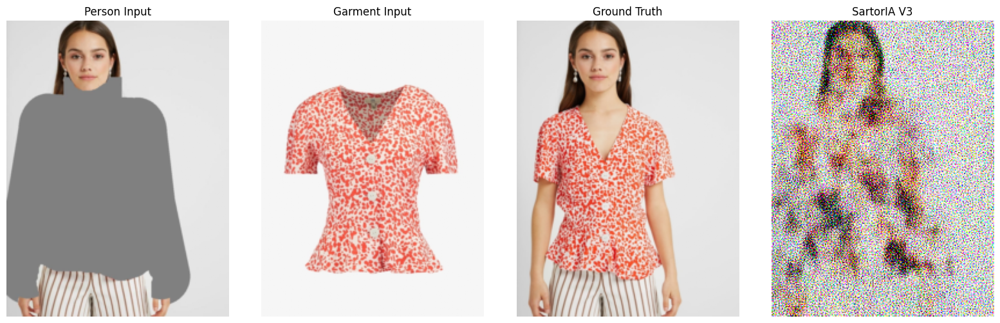


Generated V3 image saved: /content/drive/MyDrive/VESTA_AI/outputs/generated/v3/sartoria_v3_first_result.png

Phase 13.1 completed!


In [47]:
# 1. Verify checkpoint exists
assert V3_BEST_CHECKPOINT.exists(), (
    "Best V3 checkpoint not found!"
)

# 2. Load best checkpoint
best_v3_checkpoint = torch.load(
    V3_BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

model_v3.load_state_dict(
    best_v3_checkpoint["model_state_dict"]
)

model_v3.eval()

print("Best V3 checkpoint loaded!")
print("Best epoch:", best_v3_checkpoint["epoch"])
print(
    "Best validation weighted loss:",
    best_v3_checkpoint["val_metrics"]["weighted_loss"]
)

# 3. Define V3 reverse diffusion sampler
@torch.no_grad()
def sartoria_v3_generate(
    model,
    scheduler,
    person,
    garment,
    mask,
    pose,
    device,
    seed=2026
):

    model.eval()

    batch_size = person.shape[0]

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    image = torch.randn(
        person.shape,
        device=device,
        generator=generator
    )

    betas = scheduler.betas
    alphas = scheduler.alphas
    alpha_bar = scheduler.alpha_cumprod

    for t in tqdm(
        reversed(range(scheduler.timesteps)),
        total=scheduler.timesteps,
        desc="SartorIA V3 generation"
    ):

        timesteps = torch.full(
            (batch_size,),
            t,
            device=device,
            dtype=torch.long
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            predicted_velocity = model(
                noisy_target=image,
                timesteps=timesteps,
                person=person,
                garment=garment,
                mask=mask,
                pose=pose
            )

        a_bar = alpha_bar[t]
        beta = betas[t]
        alpha = alphas[t]

        # Convert velocity prediction to noise prediction
        predicted_noise = (
            torch.sqrt(1.0 - a_bar) * image.float()
            + torch.sqrt(a_bar) * predicted_velocity.float()
        )

        if t > 0:
            previous_alpha_bar = alpha_bar[t - 1]
        else:
            previous_alpha_bar = torch.tensor(
                1.0,
                device=device
            )

        # DDPM posterior variance
        posterior_variance = (
            beta * (1.0 - previous_alpha_bar)
            / (1.0 - a_bar)
        )

        # Reverse diffusion step
        image = (
            image.float()
            - (
                beta / torch.sqrt(1.0 - a_bar)
            ) * predicted_noise
        ) / torch.sqrt(alpha)

        if t > 0:

            reverse_noise = torch.randn(
                image.shape,
                device=device,
                generator=generator
            )

            image = (
                image
                + torch.sqrt(posterior_variance)
                * reverse_noise
            )

    return image.clamp(-1, 1)


print("\nSartorIA V3 generation sampler defined!")

# 4. Load a fixed validation sample
sample = val_dataset[0]

person_v3 = sample["agnostic"].unsqueeze(0).to(device)
garment_v3 = sample["garment"].unsqueeze(0).to(device)
mask_v3 = sample["cloth_mask"].unsqueeze(0).to(device)
pose_v3 = sample["pose"].unsqueeze(0).to(device)
target_v3 = sample["target"].unsqueeze(0).to(device)

# 5. Generate V3 result
generated_v3 = sartoria_v3_generate(
    model=model_v3,
    scheduler=new_scheduler,
    person=person_v3,
    garment=garment_v3,
    mask=mask_v3,
    pose=pose_v3,
    device=device,
    seed=2026
)

# 6. Check numerical stability
print("\nGenerated V3 shape:", generated_v3.shape)
print("Contains NaN:", torch.isnan(generated_v3).any().item())
print("Contains Inf:", torch.isinf(generated_v3).any().item())
print("Generated RMS:", generated_v3.float().pow(2).mean().sqrt().item())
print("Generated absolute maximum:", generated_v3.abs().max().item())

assert generated_v3.shape == target_v3.shape
assert torch.isfinite(generated_v3).all()

# 7. Display results
def sartoria_display_image(tensor):
    return (
        tensor.detach()
        .float()
        .cpu()
        .squeeze(0)
        .permute(1, 2, 0)
        .mul(0.5)
        .add(0.5)
        .clamp(0, 1)
        .numpy()
    )

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    person_v3,
    garment_v3,
    target_v3,
    generated_v3
]

titles = [
    "Person Input",
    "Garment Input",
    "Ground Truth",
    "SartorIA V3"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(sartoria_display_image(img))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 8. Save generated result
V3_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "generated" / "v3"
V3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

generated_array = (
    sartoria_display_image(generated_v3) * 255
).round().astype("uint8")

generated_path = V3_OUTPUT_DIR / "sartoria_v3_first_result.png"

Image.fromarray(generated_array).save(generated_path)

print("\nGenerated V3 image saved:", generated_path)
print("\nPhase 13.1 completed!")


## Phase 13.2 — Denoising Diagnostic

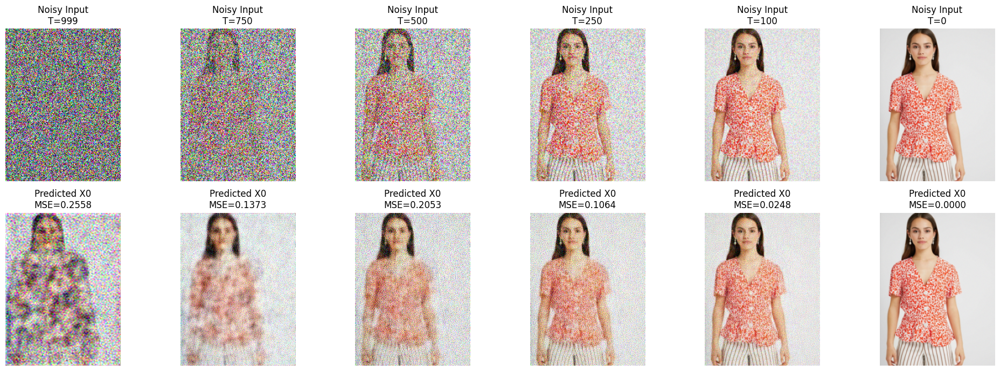


DENOISING DIAGNOSTIC RESULTS
------------------------------------------------------------
T=999 | MSE=0.25576 | Range=(-1.518, 2.266)
T=750 | MSE=0.13732 | Range=(-1.796, 2.062)
T=500 | MSE=0.20533 | Range=(-2.189, 2.636)
T=250 | MSE=0.10642 | Range=(-1.779, 2.162)
T=100 | MSE=0.02482 | Range=(-1.342, 1.493)
T=  0 | MSE=0.00005 | Range=(-1.008, 0.982)

Phase 13.2 completed!


In [48]:
model_v3.eval()

diagnostic_timesteps = [999, 750, 500, 250, 100, 0]

# Fixed noise for a controlled comparison
torch.manual_seed(2026)

diagnostic_noise = torch.randn_like(target_v3)

fig, axes = plt.subplots(
    2, 6,
    figsize=(20, 7)
)

diagnostic_results = []

for i, t in enumerate(diagnostic_timesteps):

    timestep = torch.tensor(
        [t],
        device=device,
        dtype=torch.long
    )

    alpha_bar = new_scheduler.alpha_cumprod[t]

    # Create a noisy ground-truth image
    noisy_image = (
        torch.sqrt(alpha_bar) * target_v3
        + torch.sqrt(1.0 - alpha_bar) * diagnostic_noise
    )

    with torch.no_grad():

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            predicted_velocity = model_v3(
                noisy_target=noisy_image,
                timesteps=timestep,
                person=person_v3,
                garment=garment_v3,
                mask=mask_v3,
                pose=pose_v3
            )

    # Recover predicted clean image from velocity
    predicted_x0 = (
        torch.sqrt(alpha_bar) * noisy_image.float()
        - torch.sqrt(1.0 - alpha_bar)
        * predicted_velocity.float()
    )

    mse = torch.mean(
        (predicted_x0 - target_v3).pow(2)
    ).item()

    diagnostic_results.append({
        "timestep": t,
        "reconstruction_mse": mse,
        "predicted_min": predicted_x0.min().item(),
        "predicted_max": predicted_x0.max().item()
    })

    axes[0, i].imshow(
        sartoria_display_image(noisy_image)
    )
    axes[0, i].set_title(f"Noisy Input\nT={t}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        sartoria_display_image(predicted_x0)
    )
    axes[1, i].set_title(
        f"Predicted X0\nMSE={mse:.4f}"
    )
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

print("\nDENOISING DIAGNOSTIC RESULTS")
print("-" * 60)

for result in diagnostic_results:
    print(
        f"T={result['timestep']:>3} | "
        f"MSE={result['reconstruction_mse']:.5f} | "
        f"Range=({result['predicted_min']:.3f}, "
        f"{result['predicted_max']:.3f})"
    )

print("\nPhase 13.2 completed!")
